# F1 Podium Prediction — Milestone 1

> **Generated file: do not edit this notebook by hand.** The source of truth is
> `scripts/build_notebook.py`. Edit the cells there, then rebuild and re-execute the notebook
> (see that script's docstring). Hand edits to this `.ipynb` are overwritten on the next build.

Goal: for each driver in each race, predict whether they finish on the podium
(`results.positionOrder <= 3`), using only information available after qualifying.

Sections: **1** Setup, **2** Data Loading, **3** Raw Data Audit, **4** Audit follow-ups,
**5** Findings → open decisions, **6** Cleaning, **7** Post-cleaning EDA, **8** Data-engineering questions,
**9** Modeling table, **10** Evaluation harness and baselines, **11** Tree models and model comparison.
Sections 3–4 only *measure* the raw data;
cleaning happens only in section 6, following decisions recorded in the notebook.
Reusable code lives in `src/f1podium/`.

## 1. Setup

Make the `src/` folder importable.
- **On Kaggle:** `/kaggle/input` is searched (up to 6 levels deep) for a `src/` folder containing `f1podium/` and a
  `VERSION` file (inside or beside `src/`; made by `scripts/package_kaggle.py`). That packaged `src/` is used and its
  **commit hash is printed**. Check that it matches the final commit before submitting. If `/kaggle/input` exists but
  no such folder is found, the cell stops with an error listing what is there.
- **Otherwise:** the repo's `src/`, found by searching upwards from the current folder, so the same cell works
  from `notebooks/` or from the repo root.

In [1]:
import os
import sys
from pathlib import Path

def _find_kaggle_src(root, max_depth=6):
    # First directory named "src" (walking sorted, depth <= max_depth) that contains f1podium/ and
    # has VERSION either inside src/ or beside it. Returns (src, version_file) or None.
    root = Path(root)
    for dirpath, dirnames, _ in os.walk(root):
        dirnames.sort()
        here = Path(dirpath)
        if len(here.relative_to(root).parts) >= max_depth:
            dirnames[:] = []
        if here.name == "src" and (here / "f1podium").is_dir():
            for version_file in (here / "VERSION", here.parent / "VERSION"):
                if version_file.is_file():
                    return here, version_file
    return None

def _describe_tree(root, max_depth=4):
    lines = []
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames.sort()
        depth = len(Path(dirpath).relative_to(root).parts)
        lines.append("  " * depth + (Path(dirpath).name or str(root)) + "/")
        lines.extend("  " * (depth + 1) + name for name in sorted(filenames))
        if depth >= max_depth:
            dirnames[:] = []
    return "\n".join(lines)

def _add_src_to_path(kaggle_input=Path("/kaggle/input")):
    # Returns (src dir, commit hash or None) and puts the src dir first on sys.path.
    # 1. Kaggle: a dataset made by scripts/package_kaggle.py has src/ and VERSION (inside or beside src/).
    if kaggle_input.exists():
        found = _find_kaggle_src(kaggle_input)
        if found is None:
            raise FileNotFoundError(
                "No src/ (with f1podium/ and VERSION) found under " + str(kaggle_input)
                + ". Contents (depth <= 4):\n" + _describe_tree(kaggle_input)
            )
        src, version_file = found
        sys.path.insert(0, str(src))
        return src, version_file.read_text().strip()
    # 2. Otherwise the repo's src/, found by searching upwards from the working directory.
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "src" / "f1podium").is_dir():
            src = base / "src"
            if str(src) not in sys.path:
                sys.path.insert(0, str(src))
            return src, None
    raise FileNotFoundError("Could not find src/f1podium above " + str(Path.cwd()))

SRC_DIR, SRC_COMMIT = _add_src_to_path()
print("src dir    :", SRC_DIR)
print("src commit :", SRC_COMMIT or "none (using the repo's src/, not a packaged copy)")

# autoreload is a local-development convenience. IPython's autoreload imports `imp`, which does not
# exist on Python 3.13 (Kaggle), so skip it there and never let it stop the notebook.
if SRC_COMMIT or Path("/kaggle/input").exists():
    print("autoreload skipped (Kaggle / packaged src)")
else:
    try:
        get_ipython().run_line_magic("load_ext", "autoreload")
        get_ipython().run_line_magic("autoreload", "2")
    except Exception as exc:
        print(f"autoreload unavailable: {exc}")

src dir    : C:\Users\yshim\dev\f1-podium\src
src commit : none (using the repo's src/, not a packaged copy)


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

from f1podium import config
from f1podium.clean import (
    CLEAN_STEP_DUPLICATE,
    CLEAN_STEP_INDY500,
    CLEAN_STEP_NON_STARTER,
    INDY500_CIRCUIT_REF,
    INDY500_YEARS,
    NON_START_STATUSES,
    STEP_NON_STARTER,
    WITHDREW_STATUS,
    clean_results,
)
from f1podium import de_questions as de
from f1podium import plots
from f1podium.eda import rate_by, with_podium
from f1podium.load import load_all
from f1podium.validate import (
    find_duplicates,
    missing_summary,
    run_foreign_key_checks,
    run_primary_key_checks,
)

pd.set_option("display.max_rows", 250)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

np.random.seed(config.RANDOM_SEED)

print("Python     :", sys.version.split()[0], "|", sys.executable)

import warnings
from importlib.metadata import version as _pkg_version

PINNED = {'pandas': '2.3.3', 'numpy': '2.1.3', 'scikit-learn': '1.6.1', 'statsmodels': '0.14.4', 'scipy': '1.15.3'}   # from requirements.txt at build time
for _pkg in ["pandas", "numpy", "scikit-learn", "scipy", "statsmodels"]:
    _installed = _pkg_version(_pkg)
    print(f"{_pkg:<11}: {_installed}")
    if _pkg in PINNED and _installed != PINNED[_pkg]:
        warnings.warn(f"{_pkg} {_installed} differs from requirements.txt pin {PINNED[_pkg]}")
print("src        :", SRC_DIR)
print("raw data   :", config.RAW_DIR)
print("split      : train <=", config.TRAIN_END_YEAR, "| val", config.VAL_YEARS,
      "| test >=", config.TEST_START_YEAR)
print("seed       :", config.RANDOM_SEED)

Python     : 3.13.7 | C:\Users\yshim\dev\f1-podium\.venv\Scripts\python.exe
pandas     : 2.3.3
numpy      : 2.1.3
scikit-learn: 1.6.1
scipy      : 1.15.3
statsmodels: 0.14.4
src        : C:\Users\yshim\dev\f1-podium\src
raw data   : C:\Users\yshim\dev\f1-podium\data\raw
split      : train <= 2019 | val (2020, 2021) | test >= 2022
seed       : 42


## 2. Data Loading

`load_all()` reads the 14 CSVs with an explicit schema per table:
`\N` (and empty fields) become missing; IDs/counts use nullable `Int64`;
text uses `string`; dates are parsed strictly with `%Y-%m-%d`.
The loader raises if a file's columns differ from the declared schema.

In [3]:
tables = load_all()

load_summary = pd.DataFrame(
    {
        "rows": {n: len(df) for n, df in tables.items()},
        "columns": {n: df.shape[1] for n, df in tables.items()},
        "memory_MB": {n: round(df.memory_usage(deep=True).sum() / 1e6, 2) for n, df in tables.items()},
    }
).rename_axis("table")
display(load_summary)

,rows,columns,memory_MB
table,,,
circuits,77,9,0.03
constructor_results,12625,5,1.15
constructor_standings,13391,7,1.38
constructors,212,5,0.06
driver_standings,34863,7,3.62
drivers,861,9,0.34
lap_times,589081,6,60.09
pit_stops,11371,7,1.79
qualifying,10494,9,2.35


Declared dtypes of the three tables we will use most:

In [4]:
for name in ["races", "results", "qualifying"]:
    print(f"--- {name}")
    print(tables[name].dtypes.to_string(), end="\n\n")

--- races
raceId                  Int64
year                    Int64
round                   Int64
circuitId               Int64
name           string[python]
date           datetime64[ns]
time           string[python]
url            string[python]
fp1_date       datetime64[ns]
fp1_time       string[python]
fp2_date       datetime64[ns]
fp2_time       string[python]
fp3_date       datetime64[ns]
fp3_time       string[python]
quali_date     datetime64[ns]
quali_time     string[python]
sprint_date    datetime64[ns]
sprint_time    string[python]

--- results
resultId                    Int64
raceId                      Int64
driverId                    Int64
constructorId               Int64
number                      Int64
grid                        Int64
position                    Int64
positionText       string[python]
positionOrder               Int64
points                    float64
laps                        Int64
time               string[python]
milliseconds                I

In [5]:
# Short aliases used throughout the audit
races = tables["races"]
results = tables["results"]
qualifying = tables["qualifying"]

def with_year(df: pd.DataFrame) -> pd.DataFrame:
    """Attach races.year, checking the join neither drops nor duplicates rows."""
    out = df.merge(races[["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
    assert len(out) == len(df), "join changed the row count"
    assert out["year"].notna().all(), "some rows have a raceId not in races"
    return out

## 3. Raw Data Audit

### 3.1 Missing values per column

Count and percentage of missing values for every column of every table
(after treating `\N` and empty fields as missing).

In [6]:
missing = missing_summary(tables)
display(missing.sort_values(["table", "pct_missing"], ascending=[True, False]).reset_index(drop=True))

,table,column,dtype,n_rows,n_missing,pct_missing
0,circuits,circuitId,Int64,77,0,0.00
1,circuits,circuitRef,string,77,0,0.00
2,circuits,name,string,77,0,0.00
3,circuits,location,string,77,0,0.00
4,circuits,country,string,77,0,0.00
5,circuits,lat,float64,77,0,0.00
6,circuits,lng,float64,77,0,0.00
7,circuits,alt,Int64,77,0,0.00
8,circuits,url,string,77,0,0.00
9,constructor_results,status,string,12625,12608,99.87


Only the columns that have at least one missing value, worst first:

In [7]:
display(
    missing[missing["n_missing"] > 0]
    .sort_values("pct_missing", ascending=False)
    .reset_index(drop=True)
)

,table,column,dtype,n_rows,n_missing,pct_missing
0,constructor_results,status,string,12625,12608,99.87
1,races,sprint_time,string,1125,1110,98.67
2,races,sprint_date,datetime64[ns],1125,1107,98.40
3,races,fp3_time,string,1125,1072,95.29
4,races,fp1_time,string,1125,1057,93.96
5,races,fp2_time,string,1125,1057,93.96
6,races,quali_time,string,1125,1057,93.96
7,races,fp3_date,datetime64[ns],1125,1053,93.60
8,drivers,number,Int64,861,802,93.15
9,races,fp1_date,datetime64[ns],1125,1035,92.00


### 3.2 Primary keys

A key passes if it has no nulls and no repeated values. Surrogate ids (e.g. `raceId`)
are listed first, then natural/composite keys, which say more about the data.
`results (raceId, driverId)` is **expected to fail**: early seasons have shared drives.

In [8]:
pk_results = run_primary_key_checks(tables)
display(pk_results)
print(f"{(~pk_results['passed']).sum()} of {len(pk_results)} primary-key checks failed")

,table,key,n_rows,n_null_key,n_duplicate_rows,passed
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,drivers,driverId,861,0,0,True
3,races,raceId,1125,0,0,True
4,status,statusId,139,0,0,True
5,seasons,year,75,0,0,True
6,results,resultId,26759,0,0,True
7,sprint_results,resultId,360,0,0,True
8,qualifying,qualifyId,10494,0,0,True
9,driver_standings,driverStandingsId,34863,0,0,True


1 of 24 primary-key checks failed


### 3.3 Foreign keys

For each relationship: how many child rows have a null key, and how many point to an
id that does not exist in the parent table.

In [9]:
fk_results = run_foreign_key_checks(tables)
display(fk_results)
print(f"{(~fk_results['passed']).sum()} of {len(fk_results)} foreign-key checks failed")

,child,fk,parent,n_child_rows,n_null_fk,n_unmatched_rows,n_unmatched_distinct,example_unmatched,passed
0,races,circuitId,circuits.circuitId,1125,0,0,0,[],True
1,races,year,seasons.year,1125,0,0,0,[],True
2,results,raceId,races.raceId,26759,0,0,0,[],True
3,results,driverId,drivers.driverId,26759,0,0,0,[],True
4,results,constructorId,constructors.constructorId,26759,0,0,0,[],True
5,sprint_results,raceId,races.raceId,360,0,0,0,[],True
6,sprint_results,driverId,drivers.driverId,360,0,0,0,[],True
7,sprint_results,constructorId,constructors.constructorId,360,0,0,0,[],True
8,qualifying,raceId,races.raceId,10494,0,0,0,[],True
9,qualifying,driverId,drivers.driverId,10494,0,0,0,[],True


0 of 23 foreign-key checks failed


### 3.4 Duplicate `(raceId, driverId)` rows in `results`, by year

Our modelling grain is one row per `(raceId, driverId)`. Here we count, per season,
the rows that violate it. Nothing is dropped; the rule for handling them is an open decision.

In [10]:
dups = with_year(find_duplicates(results, ["raceId", "driverId"]))

dup_by_year = pd.DataFrame({
    "n_duplicated_pairs": dups.drop_duplicates(["raceId", "driverId"]).groupby("year").size(),
    "n_rows_involved": dups.groupby("year").size(),
    "n_races_affected": dups.groupby("year")["raceId"].nunique(),
})
dup_by_year.loc["Total"] = dup_by_year.sum()
display(dup_by_year)

,n_duplicated_pairs,n_rows_involved,n_races_affected
year,,,
1950,4,8,3
1951,4,8,2
1952,3,6,3
1953,14,30,5
1954,16,33,5
1955,15,33,4
1956,12,24,6
1957,8,16,5
1958,3,6,3


Example duplicated entries (same driver, same race, more than one row):

In [11]:
example = dups.merge(
    tables["drivers"][["driverId", "driverRef"]], on="driverId", how="left", validate="many_to_one"
).merge(
    tables["constructors"][["constructorId", "constructorRef"]], on="constructorId", how="left", validate="many_to_one"
)
display(example[[
    "year", "raceId", "driverId", "driverRef", "constructorRef", "number",
    "grid", "positionText", "positionOrder", "points", "laps", "statusId",
]].head(12))

,year,raceId,driverId,driverRef,constructorRef,number,grid,positionText,positionOrder,points,laps,statusId
0,1978,540,229,ertl,ats,10,0,F,26,0.0,0,81
1,1978,540,229,ertl,ensign,23,0,F,29,0.0,0,97
2,1964,717,373,clark,lotus-climax,1,1,7,7,0.0,102,60
3,1964,717,373,clark,lotus-climax,2,1,R,12,0.0,54,98
4,1962,733,465,greene,lotus-climax,48,0,W,22,0.0,0,54
5,1962,733,465,greene,gilby,50,0,W,25,0.0,0,54
6,1961,742,475,moss,ferguson,26,20,D,19,0.0,56,2
7,1961,742,475,moss,lotus-climax,28,5,R,21,0.0,44,23
8,1961,745,418,gregory,lotus-climax,22,11,R,17,0.0,23,6
9,1961,745,418,gregory,lotus-climax,21,15,11,11,0.0,92,18


### 3.5 Qualifying data: first year and coverage per season

Two coverage measures per season:

- **races covered**: share of races with *any* qualifying rows;
- **entries covered**: share of `results` rows (driver–race entries) whose
  `(raceId, driverId)` also appears in `qualifying`. This is what matters for our grain:
  it is the share of model rows that would have qualifying features.

In [12]:
quali_race_ids = set(qualifying["raceId"].dropna())
first_quali_year = int(races.loc[races["raceId"].isin(quali_race_ids), "year"].min())
print("First season with qualifying data:", first_quali_year)

quali_pairs = qualifying[["raceId", "driverId"]].drop_duplicates().assign(has_quali=True)
entries = with_year(results[["raceId", "driverId"]]).merge(
    quali_pairs, on=["raceId", "driverId"], how="left", validate="many_to_one"
)
assert len(entries) == len(results), "join changed the row count"
entries["has_quali"] = entries["has_quali"].notna()  # True where a qualifying row matched

races_with_results = set(results["raceId"])
season = races.assign(
    has_results=races["raceId"].isin(races_with_results),
    has_quali=races["raceId"].isin(quali_race_ids),
)
quali_cov = pd.DataFrame({
    "n_races": season.groupby("year").size(),
    "n_races_with_results": season.groupby("year")["has_results"].sum(),
    "n_races_with_quali": season.groupby("year")["has_quali"].sum(),
    "n_results_rows": entries.groupby("year").size(),
    "n_results_rows_with_quali": entries.groupby("year")["has_quali"].sum(),
}).fillna(0).astype(int)
quali_cov["pct_races_covered"] = (100 * quali_cov["n_races_with_quali"] / quali_cov["n_races"]).round(1)
quali_cov["pct_entries_covered"] = (
    100 * quali_cov["n_results_rows_with_quali"] / quali_cov["n_results_rows"].replace(0, np.nan)
).round(1)
display(quali_cov)

First season with qualifying data: 1994


,n_races,n_races_with_results,n_races_with_quali,n_results_rows,n_results_rows_with_quali,pct_races_covered,pct_entries_covered
year,,,,,,,
1950,7,7,0,160,0,0.0,0.0
1951,8,8,0,179,0,0.0,0.0
1952,8,8,0,215,0,0.0,0.0
1953,9,9,0,246,0,0.0,0.0
1954,9,9,0,230,0,0.0,0.0
1955,7,7,0,180,0,0.0,0.0
1956,8,8,0,190,0,0.0,0.0
1957,8,8,0,171,0,0.0,0.0
1958,11,11,0,241,0,0.0,0.0


### 3.6 `grid = 0` by decade

`grid = 0` has no single documented meaning (e.g. pit-lane start vs. did not start).
We only count it here; how to treat it is an open decision.

In [13]:
grid = with_year(results[["raceId", "grid"]])
grid["decade"] = (grid["year"] // 10 * 10).astype(int)
grid_by_decade = grid.groupby("decade").agg(
    n_results_rows=("grid", "size"),
    n_grid_null=("grid", lambda s: int(s.isna().sum())),
    n_grid_zero=("grid", lambda s: int((s == 0).sum())),
)
grid_by_decade["pct_grid_zero"] = (100 * grid_by_decade["n_grid_zero"] / grid_by_decade["n_results_rows"]).round(2)
display(grid_by_decade)

,n_results_rows,n_grid_null,n_grid_zero,pct_grid_zero
decade,,,,
1950,2007,0,68,3.39
1960,2113,0,198,9.37
1970,3807,0,351,9.22
1980,4503,0,571,12.68
1990,4250,0,357,8.4
2000,3643,0,8,0.22
2010,4297,0,28,0.65
2020,2139,0,57,2.66


## 4. Audit follow-ups

Deeper looks at the three open questions raised by the audit. **Investigation only:**
nothing is cleaned, dropped or recoded in the data; any grouping below exists only to
make a table readable.

### 4.1 What do `grid = 0` rows look like?

Two cross-tabs of the `grid = 0` rows from `results`, by decade:

- **× status**: the race outcome recorded in `status` (e.g. *Did not qualify*, *Engine*, *Finished*).
- **× positionText**: Ergast's result code. Letters are non-classifications
  (`R` retired, `D` disqualified, `E` excluded, `W` withdrawn, `F` failed to qualify,
  `N` not classified). Numbers are classified finishing positions; to keep the table
  narrow they are grouped into *classified P1–3* and *classified P4+*.

If `grid = 0` mostly means "never started", we expect it to sit with *Did not qualify* /
`F` / `W`. If it means "started from the pit lane", we expect normal outcomes
(finishes, retirements).

In [14]:
POS_TEXT_LABELS = {
    "R": "R (retired)",
    "D": "D (disqualified)",
    "E": "E (excluded)",
    "W": "W (withdrawn)",
    "F": "F (failed to qualify)",
    "N": "N (not classified)",
}

def position_text_group(pt: str) -> str:
    """Readable group for a positionText value (display only)."""
    if pt.isdigit():
        return "classified P1-3" if int(pt) <= 3 else "classified P4+"
    return POS_TEXT_LABELS.get(pt, pt)

grid0 = with_year(results.loc[results["grid"] == 0, ["raceId", "statusId", "positionText"]])
grid0["decade"] = (grid0["year"] // 10 * 10).astype(int)
grid0 = grid0.merge(tables["status"], on="statusId", how="left", validate="many_to_one")
assert grid0["status"].notna().all(), "grid = 0 row with unknown statusId"
grid0["positionText_group"] = grid0["positionText"].map(position_text_group)
print("grid = 0 rows:", len(grid0))

def crosstab_by_decade(row_col: str, top_n: int | None = None) -> pd.DataFrame:
    """Rows sorted by total; optionally keep the top_n rows and fold the rest into 'Other'."""
    ct = pd.crosstab(grid0[row_col], grid0["decade"], margins=True, margins_name="Total")
    body = ct.drop(index="Total").sort_values("Total", ascending=False)
    if top_n is not None and len(body) > top_n:
        rest = body.iloc[top_n:]
        other = rest.sum().rename(f"Other ({len(rest)} statuses)")
        body = pd.concat([body.iloc[:top_n], other.to_frame().T])
    return pd.concat([body, ct.loc[["Total"]]])

grid = 0 rows: 1638


**`grid = 0` × status**: the top 15 statuses, with the rest folded into *Other*. The last row is the column total:

In [15]:
display(crosstab_by_decade("status", top_n=15))

decade,1950,1960,1970,1980,1990,2000,2010,2020,Total
Did not qualify,49,71,298,380,209,2,4,0,1013
Did not prequalify,0,3,32,164,132,0,0,0,331
Withdrew,13,118,14,10,4,1,2,2,164
+1 Lap,0,0,0,0,0,0,5,22,27
Finished,0,0,0,0,0,0,3,19,22
Accident,2,3,6,4,3,0,1,1,20
Injury,0,1,0,1,4,1,1,0,8
+2 Laps,0,0,0,0,0,0,4,3,7
Excluded,0,0,0,5,1,0,0,0,6
Engine,4,1,0,0,0,0,0,1,6


**`grid = 0` × positionText group:**

In [16]:
display(crosstab_by_decade("positionText_group"))

decade,1950,1960,1970,1980,1990,2000,2010,2020,Total
positionText_group,,,,,,,,,
F (failed to qualify),49,74,330,544,342,5,4,0,1348
W (withdrawn),19,124,21,17,11,3,4,4,203
classified P4+,0,0,0,0,0,0,13,47,60
R (retired),0,0,0,1,0,0,7,6,14
E (excluded),0,0,0,5,2,0,0,0,7
D (disqualified),0,0,0,4,2,0,0,0,6
Total,68,198,351,571,357,8,28,57,1638


**What this shows.**

- **Before 2000, `grid = 0` almost always means "did not start".** Of the 1,638 rows,
  1,348 are `F` (failed to qualify): 1,013 *Did not qualify* plus 331 *Did not prequalify*.
  Another 203 are `W` (withdrawn). These cars never took the start. Prequalifying shows up only
  in the 1970s–90s, when more cars entered than could race.
- **From the 2010s on, it mostly means "started from the pit lane".** The statuses become
  *Finished*, *+1 Lap* and mechanical retirements, so these cars raced. All 60 classified
  `grid = 0` rows fall in 2015–2024, and the best finish is **P5**. No `grid = 0` entry in this
  dataset reached the podium.
- **Some rows are still unexplained (Unknown).** 18 *Accident* rows from the 1950s–1990s have
  `grid = 0`. These may be accidents in practice or qualifying; the cause is not investigated here.
- **Leakage note.** `status` and `positionText` are post-race columns, so they cannot be model
  features. They are used here only to understand what `grid = 0` means. Failing to qualify is
  known *after qualifying*, which is our prediction cutoff, so deciding how to treat those rows
  remains an open decision rather than a leakage problem.

#### 4.1b Non-start statuses: `grid = 0` vs `grid > 0`

The other direction: start from statuses that *sound* like a non-start and check their grid value.
`laps_gt0` counts rows that completed at least one lap, which is direct evidence that the car raced.

The candidate list is for investigation only; it is **not** a non-starter definition. It includes
*Not classified* to test it. In F1 terminology, *not classified* means the car started but covered
too little of the race distance to be classified. `laps` is a post-race column, used here as evidence only.

In [17]:
NON_START_CANDIDATES = [
    "Did not qualify", "Did not prequalify", "107% Rule", "Withdrew", "Not classified",
    "Excluded", "Injury", "Injured", "Driver unwell", "Safety concerns", "Underweight",
]
missing_statuses = set(NON_START_CANDIDATES) - set(tables["status"]["status"])
assert not missing_statuses, f"not in status table: {missing_statuses}"

cand = (
    results[["raceId", "statusId", "grid", "laps"]]
    .merge(tables["status"], on="statusId", how="left", validate="many_to_one")
    .query("status in @NON_START_CANDIDATES")
)
cand["grid_group"] = np.where(cand["grid"] > 0, "grid>0", "grid=0")
non_start_split = (
    cand.groupby(["status", "grid_group"])
    .agg(rows=("laps", "size"), laps_gt0=("laps", lambda s: int((s > 0).sum())))
    .unstack("grid_group", fill_value=0)
    .reindex(NON_START_CANDIDATES)
    .fillna(0)
    .astype(int)
)
non_start_split.columns = [f"{grid}: {measure}" for measure, grid in non_start_split.columns]
non_start_split = non_start_split[["grid=0: rows", "grid=0: laps_gt0", "grid>0: rows", "grid>0: laps_gt0"]]
display(non_start_split)

,grid=0: rows,grid=0: laps_gt0,grid>0: rows,grid>0: laps_gt0
status,,,,
Did not qualify,1013,0,12,1
Did not prequalify,331,0,0,0
107% Rule,2,0,7,0
Withdrew,164,0,84,23
Not classified,0,0,172,172
Excluded,6,0,2,1
Injury,8,0,5,1
Injured,2,0,5,0
Driver unwell,0,0,10,9


Where the `Withdrew` rows with `grid > 0` come from (the top 5 races):

In [18]:
withdrew_started_grid = with_year(
    results.loc[(results["statusId"].isin(tables["status"].query("status == 'Withdrew'")["statusId"]))
                & (results["grid"] > 0), ["raceId", "laps"]]
).merge(races[["raceId", "name"]], on="raceId", how="left", validate="many_to_one")
display(
    withdrew_started_grid.groupby(["year", "name"])
    .agg(rows=("laps", "size"), laps_gt0=("laps", lambda s: int((s > 0).sum())))
    .sort_values("rows", ascending=False)
    .head(5)
)

,,rows,laps_gt0
year,name,,
2005,United States Grand Prix,14,0
1976,Japanese Grand Prix,4,4
1975,Spanish Grand Prix,3,2
1954,Argentine Grand Prix,2,0
1952,Swiss Grand Prix,2,2


**What this shows.**

- **Most non-start statuses go with `grid = 0`, but not all of them.** *Did not prequalify* is 331 rows, all with
  `grid = 0`. *Did not qualify* has 1,013 rows with `grid = 0` and 12 with `grid > 0`; one of those 12 even
  completed a lap.
- **`Withdrew` covers three different situations:**
  - 164 rows with `grid = 0`: never took a grid slot.
  - 61 rows with `grid > 0` and no laps: qualified, then did not start. 14 of these are the
    2005 US GP, where most of the field withdrew after the formation lap.
  - 23 rows with `grid > 0` and at least one lap: started the race, then withdrew.
- **`Not classified` is not a non-start.** All 172 rows have `grid > 0` and at least one lap.
- **Other candidates are small and mixed.**
  - *107% Rule:* 7 of its 9 rows have `grid > 0`, but none completed a lap.
  - *Driver unwell:* 9 of its 10 rows completed laps, so it mostly means "started, then stopped".
  - *Excluded* and *Injury:* no `grid = 0` row completed a lap, but one `grid > 0` row each did.
- **So neither signal is enough on its own.** `grid = 0` alone and status alone each misclassify
  some entries. Any non-starter definition has to say which signals it uses, and whether those
  signals are known at the prediction cutoff.

### 4.2 The 85 duplicate `(raceId, driverId)` pairs

One row per duplicated pair, describing its rows:

- `n_rows`: how many `results` rows the driver has in that race;
- `n_rows_grid_pos`: how many of those rows have `grid > 0` (i.e. a real starting slot);
- `positionTexts`: each row's `positionText`, in `positionOrder` order;
- `constructors_differ`: whether the rows are for different constructors.

Then the pairs are summarised as **counts per pattern**. For the pattern,
`positionText` is reduced to *classified* vs. its letter code, so that e.g. `4 / R` and
`7 / R` count as the same pattern (`R + classified`).

In [19]:
dup_rows = (
    with_year(find_duplicates(results, ["raceId", "driverId"]))
    .merge(tables["drivers"][["driverId", "driverRef"]], on="driverId", how="left", validate="many_to_one")
    .sort_values(["year", "raceId", "driverId", "positionOrder"])
)
dup_rows["pt_kind"] = dup_rows["positionText"].map(lambda pt: "classified" if pt.isdigit() else pt)

dup_pairs = (
    dup_rows.groupby(["raceId", "driverId"], sort=False)
    .agg(
        year=("year", "first"),
        driverRef=("driverRef", "first"),
        n_rows=("resultId", "size"),
        n_rows_grid_pos=("grid", lambda s: int((s > 0).sum())),
        positionTexts=("positionText", lambda s: " / ".join(s)),
        n_constructors=("constructorId", "nunique"),
        result_pattern=("pt_kind", lambda s: " + ".join(sorted(s))),
    )
    .reset_index()
)
dup_pairs["constructors_differ"] = dup_pairs["n_constructors"] > 1
indy_race_ids = set(races.loc[races["name"] == "Indianapolis 500", "raceId"])
dup_pairs["indy500"] = dup_pairs["raceId"].isin(indy_race_ids)
assert len(dup_pairs) == dup_rows[["raceId", "driverId"]].drop_duplicates().shape[0]
print("duplicated pairs:", len(dup_pairs), "| rows involved:", len(dup_rows),
      "| pairs from the Indianapolis 500:", int(dup_pairs["indy500"].sum()))
display(dup_pairs[[
    "year", "raceId", "driverRef", "n_rows", "n_rows_grid_pos",
    "positionTexts", "constructors_differ", "indy500",
]])

duplicated pairs: 85 | rows involved: 176 | pairs from the Indianapolis 500: 21


,year,raceId,driverRef,n_rows,n_rows_grid_pos,positionTexts,constructors_differ,indy500
0,1950,835,bettenhausen,2,2,5 / R,True,True
1,1950,838,rosier,2,2,6 / R,False,False
2,1950,839,fangio,2,2,R / R,False,False
3,1950,839,ascari,2,2,2 / R,False,False
4,1951,828,fangio,2,2,1 / 11,False,False
5,1951,828,ascari,2,2,2 / R,False,False
6,1951,828,fagioli,2,2,1 / 11,False,False
7,1951,831,farina,2,2,3 / R,False,False
8,1952,817,farina,2,2,R / R,False,False
9,1952,820,schell,2,2,R / R,False,False


**Counts per pattern** (`years` = first–last season the pattern occurs):

In [20]:
dup_patterns = (
    dup_pairs.groupby(["n_rows", "n_rows_grid_pos", "constructors_differ", "result_pattern"])
    .agg(
        n_pairs=("year", "size"),
        n_indy500=("indy500", "sum"),
        years=("year", lambda y: f"{y.min()}-{y.max()}"),
    )
    .reset_index()
    .sort_values("n_pairs", ascending=False, ignore_index=True)
)
assert dup_patterns["n_pairs"].sum() == len(dup_pairs)
display(dup_patterns)

,n_rows,n_rows_grid_pos,constructors_differ,result_pattern,n_pairs,n_indy500,years
0,2,2,False,R + classified,46,7,1950-1964
1,2,2,False,R + R,12,1,1950-1958
2,2,2,False,classified + classified,8,2,1951-1956
3,2,2,True,R + classified,7,6,1950-1956
4,3,3,True,R + R + classified,3,3,1953-1954
5,3,3,False,R + classified + classified,2,0,1955-1955
6,2,0,True,F + F,2,0,1958-1978
7,2,2,True,R + R,2,2,1953-1954
8,2,0,True,W + W,1,0,1962-1962
9,2,2,True,D + R,1,0,1961-1961


**What this shows.**

- **Each row is one car the driver drove, and it carries that car's grid slot and result.**
  This was confirmed on the 1951 French GP (raceId 828). Fangio has one row for car 8, grid 7,
  **1st**: Fagioli's car, which Fangio took over and won in. He has a second row for his own
  car 24, grid 1, 11th. Fagioli has rows for the same two cars. So in shared drives, `grid`
  describes the *car*, not where that driver started.
- **Most duplicates are classic 1950s shared drives.** 82 of the 85 pairs have `grid > 0` in every
  row. The most common pattern is *R + classified* with the same constructor (46 pairs): the
  driver's own car retired, and they finished the race in a teammate's car. In 8 pairs, both
  cars the driver drove were classified.
- **3 pairs are not shared drives.** They have `grid = 0` in both rows: *F + F* in 1958 and 1978,
  and *W + W* in 1962. The driver was entered in two cars and started neither. These overlap
  with the non-starter question in 4.1.
- **21 of the 85 pairs come from the Indianapolis 500** (1950, 1953, 1954). In about half of them
  (11 of 21) the constructors differ, because drivers relieved each other across teams. This links the shared-drive
  rule to the open Indy 500 exclusion decision.
- **Why it matters for the target.** With shared drives, one driver can have both a podium row
  and a non-podium row in the same race (Fangio 1951 above). Any rule for these rows has to say
  what `podium` means for such a driver. That is an open decision and is not settled here.

### 4.3 Qualifying coverage per season, 1990–2024

Share of race entries (`results` rows) that have a matching `qualifying` row: the
`pct_entries_covered` column from 3.5, plotted. Dashed lines mark the planned
train / validation / test boundaries. (Race-level coverage is almost identical and is
in the 3.5 table.)

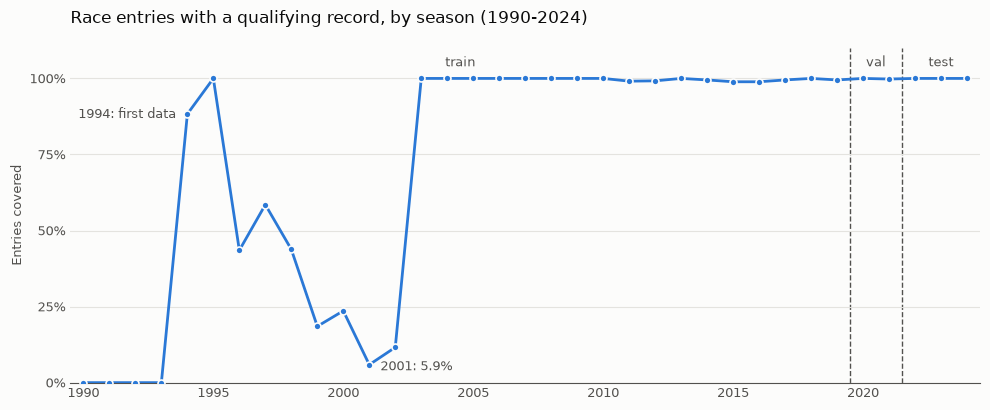

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

INK, INK_MUTED, SERIES, SURFACE = "#0b0b0b", "#52514e", "#2a78d6", "#fcfcfb"

cov = quali_cov.loc[1990:2024, "pct_entries_covered"]
years, pct = cov.index.astype(int), cov.astype(float).to_numpy()

fig, ax = plt.subplots(figsize=(10, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(years, pct, color=SERIES, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1.2, zorder=3)

# Planned split boundaries
for x in (config.TRAIN_END_YEAR + 0.5, config.TEST_START_YEAR - 0.5):
    ax.axvline(x, color=INK_MUTED, linewidth=1, linestyle="--", zorder=1)
for x, label in [((1990 + config.TRAIN_END_YEAR) / 2, "train"),
                 (sum(config.VAL_YEARS) / 2, "val"),
                 ((config.TEST_START_YEAR + 2024) / 2, "test")]:
    ax.text(x, 103, label, ha="center", va="bottom", color=INK_MUTED, fontsize=9)

# Selective direct labels: first year with data and the lowest season after it
first = int(years[pct > 0][0])
gap_years = cov.loc[first:2002]
low = int(gap_years.idxmin())
ax.annotate(f"{first}: first data", (first, cov[first]), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center", color=INK_MUTED, fontsize=9)
ax.annotate(f"{low}: {cov[low]:.1f}%", (low, cov[low]), xytext=(8, -4),
            textcoords="offset points", color=INK_MUTED, fontsize=9)

ax.set_xlim(1989.5, 2024.5)
ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_xticks(range(1990, 2025, 5))
ax.grid(axis="y", color="#e4e3df", linewidth=0.8, zorder=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(INK_MUTED)
ax.tick_params(colors=INK_MUTED, length=0, labelsize=9)
ax.set_title("Race entries with a qualifying record, by season (1990-2024)",
             loc="left", color=INK, fontsize=12, pad=18)
ax.set_ylabel("Entries covered", color=INK_MUTED, fontsize=9)
fig.tight_layout()
plt.show()

**What this shows.**

- **There are four phases.** There is no qualifying data before 1994. 1994–1995 is nearly
  complete. **1996–2002 is patchy**, as low as 5.9% of entries in 2001. **From 2003 on**, coverage
  is about 99–100%.
- **Validation (2020–21) and test (2022+) are fully covered.** The coverage gap affects only the
  training years.
- **The training window and missing-qualifying strategy are linked.** A window starting in 2003
  has near-complete qualifying data. An earlier start brings many rows with no qualifying times.
  `results.grid` has no nulls in any year (3.6), so it is always available as a pre-race
  position signal.
- **The small dips in 2011–2019 (~99%)** are a handful of entries without a qualifying row.
  Their cause is Unknown and was not investigated here.

## 5. Findings → open decisions

Decisions are labelled D1, D2, … and recorded in full in section 6.

| Finding | Evidence (section) | Open decision | Rule | Status |
|---|---|---|---|---|
| 85 duplicated `(raceId, driverId)` pairs, mostly 1950s shared drives | 3.4, 4.2 | **D1** Shared-drive rule | Rule B: target-blind heuristic (started row, lowest grid, lowest resultId; see 6.3) | **Decided** |
| 11 Indianapolis 500 races (1950–1960); they also hold 21 of the 85 duplicate pairs | 4.2 | **D2** Indy 500 exclusion | Exclude races at the Indianapolis circuit in 1950–1960 (see 6.1) | **Decided** |
| About 1,500 entries that never started (DNQ, DNPQ, 107% rule, withdrawn without a grid slot) | 4.1, 4.1b | **D3** Non-starters | Exclude by status, plus grid for *Withdrew* (see 6.2) | **Decided** |
| … | 3.5, 4.3 | Missing-qualifying strategy / training window | … | Pending |
| `grid = 0` means "did not start" before 2000 and mostly "pit-lane start" after 2010 | 3.6, 4.1 | Meaning of `grid = 0` **as a feature** | After cleaning, a pit-lane start: `pit_lane_start = 1`, `grid_filled` = number of starters (see 9) | **Decided** |
| `results.points` excludes sprint points (2021–2024) | 9.5 | Sprint data | Sprint points of **earlier** rounds count towards `points_before`; the current round's sprint is never used (see 9) | **Decided** |

## 6. Cleaning

Cleaning steps implement the decisions recorded below. Each step is a pure function in
`src/f1podium/clean.py` that returns a new table plus a log; the raw tables are never modified.

**Pipeline order for `results`:** D2 Indianapolis 500 exclusion → D3 non-starter filter → D1 duplicate resolution.

- **D2 runs first** because it removes whole races, including 21 of the duplicate pairs. Those pairs
  then never reach the duplicate rule.
- **D3 runs before D1** so that a did-not-qualify row can never be the row D1 keeps, and so that pairs
  made only of non-starters disappear entirely. After D3, every remaining duplicate pair consists of
  cars that took a grid slot.

The whole pipeline is one call, `clean_results`, which fixes this order (a unit test fails if the order changes)
and itself raises if `(raceId, driverId)` is not unique at the end. It returns the cleaned table and a
**combined log** with one row per removed `results` row, labelled with the step that removed it. Sections
6.1–6.3 below read their per-step views from that log.

In [22]:
results_clean, clean_log = clean_results(results, races, tables["circuits"], tables["status"])

print(f"results rows: {len(results)} -> {len(results_clean)} (removed {len(clean_log)})")
display(clean_log["step"].value_counts().rename_axis("step").to_frame("rows_removed"))

def log_rows(step: str) -> pd.DataFrame:
    """Rows of the combined log removed by one step."""
    return clean_log[clean_log["step"] == step]

results rows: 26759 -> 24761 (removed 1998)


,rows_removed
step,
D3: non-starter,1529
D2: Indianapolis 500,405
D1: duplicate,64


### 6.1 D2: Indianapolis 500 exclusion

#### Decision record

**Problem.** From 1950 to 1960 the Indianapolis 500 counted towards the drivers' championship, so it appears in
`races` and `results`. It also accounts for 21 of the 85 duplicate pairs (4.2): relief drivers moved across teams.

**Options considered**

| Option | Rule | Assessment |
|---|---|---|
| A | Keep the races | Mixes in a race that does not behave like a Grand Prix (see *Why*). |
| B | Keep them, with an "is Indy 500" indicator | Lets a model separate them, but 11 races are too few to learn a separate pattern from. |
| **C** | **Exclude all results of these races** | Chosen. |

**Choice: C.** Exclude every `results` row of a race held at the circuit with `circuitRef == "indianapolis"`
in 1950–1960 (inclusive).

**Why** *(drafted for your review)*. The Indy 500 was run to American (AAA/USAC) rules, with its own qualifying format
and a field almost entirely separate from the Grand Prix regulars. Its entries therefore say little about the
podium chances of an F1 field after qualifying, which is what we predict.

**How it is identified.** It is identified by circuit **and** year range, not by name. The same circuit later hosted the
United States Grand Prix (2000–2007), which is an ordinary F1 race and is kept. The table below shows every
race held at the circuit. An assertion checks that the selection equals exactly the races named
"Indianapolis 500".

In [23]:
indy_circuit = tables["circuits"].loc[
    tables["circuits"]["circuitRef"] == INDY500_CIRCUIT_REF, ["circuitId", "circuitRef", "name"]
]
display(indy_circuit)

at_indy = races[races["circuitId"].isin(indy_circuit["circuitId"])]
display(
    at_indy.groupby("name")
    .agg(first_year=("year", "min"), last_year=("year", "max"), n_races=("raceId", "size"))
    .sort_values("first_year")
)
print("Excluded year range (inclusive):", INDY500_YEARS)

,circuitId,circuitRef,name
18,19,indianapolis,Indianapolis Motor Speedway


,first_year,last_year,n_races
name,,,
Indianapolis 500,1950,1960,11
United States Grand Prix,2000,2007,8


Excluded year range (inclusive): (1950, 1960)


In [24]:
indy_rows = log_rows(CLEAN_STEP_INDY500)
indy_log = (
    indy_rows.groupby(["raceId", "year"]).size().rename("n_rows_excluded").reset_index()
    .merge(races[["raceId", "name"]], on="raceId", how="left", validate="one_to_one")
    .sort_values("year", ignore_index=True)
)

named_indy500 = set(races.loc[races["name"] == "Indianapolis 500", "raceId"])
assert set(indy_log["raceId"]) == named_indy500, "selection != races named 'Indianapolis 500'"
assert len(indy_rows) == results["raceId"].isin(named_indy500).sum(), "not every Indy 500 row was removed"

print(f"D2 removed {len(indy_rows)} rows from {len(indy_log)} races")
display(indy_log[["raceId", "year", "name", "n_rows_excluded"]])

D2 removed 405 rows from 11 races


,raceId,year,name,n_rows_excluded
0,835,1950,Indianapolis 500,35
1,826,1951,Indianapolis 500,34
2,818,1952,Indianapolis 500,33
3,809,1953,Indianapolis 500,47
4,800,1954,Indianapolis 500,55
5,794,1955,Indianapolis 500,35
6,786,1956,Indianapolis 500,34
7,778,1957,Indianapolis 500,33
8,768,1958,Indianapolis 500,33
9,757,1959,Indianapolis 500,33


### 6.2 D3: Non-starter filter

#### Decision record

**Problem.** About 1,500 `results` rows describe entries that never took the start (4.1, 4.1b). We predict podiums for
the cars that line up after qualifying, so these rows are not part of the population we predict for.

**Choice.** Exclude a row when:
- its status is *Did not qualify*, *Did not prequalify* or *107% Rule*, whatever its grid; **or**
- its status is *Withdrew* **and** `grid == 0`.

**Why status is acceptable here.** CLAUDE.md lists `status` as a post-race column, and it is never used as a
**feature**. Here it is used only to define *which rows are in the population*, and only through values that are
settled by qualifying:
- not qualifying, not prequalifying and failing the 107% rule are all decided in qualifying, so they are known at our cutoff;
- *Withdrew* with `grid = 0` means the car never took a grid slot *(Assumption: the withdrawal is known before the start)*.

**Deliberately kept:**
- **Not classified:** these cars started (4.1b: all 172 rows completed laps).
- **Pit-lane starts:** `grid = 0` with any other status, mostly 2010 onwards.
- **Withdrew with `grid > 0`:** the car qualified and withdrew later. That is not known at the cutoff in general
  (e.g. 2005 US GP), so these remain as real entries; their label is non-podium.

**Never used for selection:** `laps` or any other post-race column. The diagnostic in 6.4 looks at `laps`
afterwards, only to show what remains.

In [25]:
non_start_log = (
    log_rows(CLEAN_STEP_NON_STARTER)
    .merge(results[["resultId", "statusId", "grid"]], on="resultId", how="left", validate="one_to_one")
    .merge(tables["status"], on="statusId", how="left", validate="many_to_one")
)
assert set(non_start_log["status"]) <= set(NON_START_STATUSES) | {WITHDREW_STATUS}
assert (non_start_log.loc[non_start_log["status"] == WITHDREW_STATUS, "grid"] == 0).all()

print(f"D3 removed {len(non_start_log)} rows")
display(non_start_log["reason"].value_counts().rename_axis("reason").to_frame("n_rows"))

D3 removed 1529 rows


,n_rows
reason,
status: Did not qualify,1025
status: Did not prequalify,331
Withdrew with grid = 0,164
status: 107% Rule,9


Excluded rows by status × decade:

In [26]:
non_start_log["decade"] = (non_start_log["year"] // 10 * 10).astype(int)
display(pd.crosstab(non_start_log["status"], non_start_log["decade"], margins=True, margins_name="Total"))

decade,1950,1960,1970,1980,1990,2000,2010,2020,Total
status,,,,,,,,,
107% Rule,0,0,0,0,7,2,0,0,9
Did not prequalify,0,3,32,164,132,0,0,0,331
Did not qualify,50,72,299,381,217,2,4,0,1025
Withdrew,13,118,14,10,4,1,2,2,164
Total,63,193,345,555,360,5,6,2,1529


### 6.3 D1: Duplicate `(raceId, driverId)` rows in `results`

#### Decision record

**Problem.** In the raw data, 85 driver–race pairs have more than one `results` row (176 rows, 1950–1978; see 3.4 and 4.2).
Our grain needs exactly one row per driver per race. After D2 removes the Indianapolis 500 (21 pairs) and D3 removes
the pairs made only of non-starters (3 pairs), **61 pairs** reach this step.

**Options considered**

| Option | Rule | Assessment |
|---|---|---|
| A | Keep the row with the best `positionOrder` | Chooses rows **using the target**: a driver who took over a winning car gets the podium. This is label leakage and inflates podium rates. |
| **B** | **Keep one row per pair chosen by pre-race fields only** (`grid > 0`, then lowest grid, then lowest `resultId`) | Target-blind: the choice never looks at positions, points or status, so it cannot favour podium rows. |
| C | Drop every duplicated pair | Deletes real race entries, including genuine podiums, and leaves holes in those races. |
| D | Aggregate rows (e.g. best result, mean grid) | Creates a row that never existed: its features and label come from different cars. |

**Choice: B**, applied in this order:
1. Pairs where no row has `grid > 0` are non-starters. They are left untouched and logged as
   *resolved by non-starter filter*. Because D3 runs first, this step is expected never to be used; an assertion checks it.
2. Keep the row with `grid > 0`.
3. If several rows have `grid > 0`, keep the lowest grid.
4. Final deterministic tie-break: the lowest `resultId`.

**Why.** B is **not** "keep the car the driver started in"; the data cannot tell us that. **Every resolved
pair has more than one row with `grid > 0`.** Step 2 never decides a real pair (see the step counts below:
0 × *single started row*). In a shared drive, every row carries *that car's* grid slot, not the driver's.
So the lowest grid is a **target-blind heuristic for the driver's primary entry**: the
better-placed car they are listed with. What B guarantees is that the row is chosen without looking at the
outcome, unlike rule A, and is fully deterministic. It does not guarantee that the kept row is the car the
driver started in. *(Assumption: the lowest grid usually corresponds to the primary entry; Unknown how often.)*

**Known misattributions (accepted).** Here the heuristic keeps a car the driver took over, not the one they started in:
- **Fagioli, 1951 French GP (raceId 828).** He started car 8 from grid 7. Fangio took it over and won.
  Fagioli then drove Fangio's car 24 (grid 1, classified 11th). B keeps the car-24 row (resultId 20188, P11)
  instead of car 8 (resultId 19918, P1).
- **Brooks, 1957 British GP (raceId 780).** Moss took over the car Brooks started in (grid 3) and won.
  Brooks drove Moss's car (grid 1, classified 12th). B keeps resultId 20293 (P12) instead of 18806 (P1).

In both cases the label changes from podium to non-podium. The log column
`lowest_grid_differs_from_lowest_resultId` flags the pairs where the lowest grid and the lowest `resultId`
disagree (counted below). The lowest `resultId` is often the originally entered car, but it is only partial evidence,
so these flagged pairs are where further misattributions are most likely.

**Measured impact:** see the end of this section.

In [27]:
# One row per duplicated pair, rebuilt from the combined log (one log row per dropped results row).
dup_log = (
    log_rows(CLEAN_STEP_DUPLICATE)
    .groupby(["raceId", "driverId"], as_index=False)
    .agg(
        year=("year", "first"),
        n_rows=("resultId", lambda s: len(s) + 1),  # dropped rows + the kept row
        resolving_step=("resolving_step", "first"),
        kept_resultId=("kept_resultId", "first"),
        dropped_resultIds=("resultId", lambda s: sorted(int(x) for x in s)),
        lowest_grid_differs_from_lowest_resultId=("lowest_grid_differs_from_lowest_resultId", "first"),
    )
    .sort_values(["year", "raceId", "driverId"], ignore_index=True)
)

print("Pairs per resolving step:")
display(dup_log["resolving_step"].value_counts().rename_axis("resolving_step").to_frame("n_pairs"))
display(dup_log)

Pairs per resolving step:


,n_pairs
resolving_step,
lowest_grid,60
lowest_resultId,1


,raceId,driverId,year,n_rows,resolving_step,kept_resultId,dropped_resultIds,lowest_grid_differs_from_lowest_resultId
0,838,627,1950,2,lowest_grid,20143,[20182],False
1,839,579,1950,2,lowest_grid,20164,[20184],False
2,839,647,1950,2,lowest_grid,20166,[20183],False
3,828,579,1951,2,lowest_grid,19928,[20186],False
4,828,647,1951,2,lowest_grid,19935,[19919],True
5,828,786,1951,2,lowest_grid,20188,[19918],True
6,831,642,1951,2,lowest_grid,19998,[20189],False
7,817,642,1952,2,lowest_grid,19654,[20190],False
8,820,501,1952,2,lowest_grid,19734,[20192],False
9,823,759,1952,2,lowest_grid,19814,[20193],False


**Checks.** Every check below is an assertion, so the notebook stops if any of them fails.
`clean_results` already raises if the final table is not unique; these repeat the checks visibly:
- **Row count:** the cleaned table has exactly *raw − removed* rows.
- **Uniqueness:** `(raceId, driverId)` is **fully** unique.
- **No pending pairs:** the *non-starter* step of D1 was never needed, because D3 ran first.
- **Kept rows exist:** every pair's kept row is in the cleaned table.

In [28]:
n_dropped = int(dup_log["dropped_resultIds"].str.len().sum())
assert len(results_clean) == len(results) - len(clean_log), "row count != raw - removed"
assert not results_clean.duplicated(["raceId", "driverId"]).any(), "(raceId, driverId) is not unique"
assert not (dup_log["resolving_step"] == STEP_NON_STARTER).any(), "non-starter pairs reached D1"
assert dup_log["kept_resultId"].isin(results_clean["resultId"]).all(), "a kept row is missing"

print(f"D1 dropped {n_dropped} rows in {len(dup_log)} pairs")
print("All checks passed: (raceId, driverId) is unique.")

D1 dropped 64 rows in 61 pairs
All checks passed: (raceId, driverId) is unique.


#### Sensitivity check: rule B vs rule A (best `positionOrder`)

For each pair that rule B resolved, we also apply rule A (best `positionOrder`, with the lowest `resultId` as tie-break).
We then count how often the two rules keep a different row, and how often the **podium label**
(`positionOrder <= 3`) differs. This shows how much the label depends on the choice.
`positionOrder` is used here only to measure this; it plays no part in rule B itself.

In [29]:
# The rows D1 chose between: each pair's kept row plus its dropped rows.
pair_result_ids = set(dup_log["kept_resultId"]) | {r for ids in dup_log["dropped_resultIds"] for r in ids}
dup_rows_all = results[results["resultId"].isin(pair_result_ids)]
assert len(dup_rows_all) == dup_log["n_rows"].sum(), "pair rows do not match the log"

rule_a = (
    dup_rows_all.sort_values(["positionOrder", "resultId"])
    .groupby(["raceId", "driverId"]).head(1)
    [["raceId", "driverId", "resultId"]]
    .rename(columns={"resultId": "kept_A"})
)
compare = (
    dup_log[["year", "raceId", "driverId", "kept_resultId", "lowest_grid_differs_from_lowest_resultId"]]
    .rename(columns={"kept_resultId": "kept_B"})
    .merge(rule_a, on=["raceId", "driverId"], how="left", validate="one_to_one")
)
by_id = results.set_index("resultId")
for rule in ("A", "B"):
    kept = compare[f"kept_{rule}"]
    compare[f"grid_{rule}"] = kept.map(by_id["grid"])
    compare[f"positionOrder_{rule}"] = kept.map(by_id["positionOrder"])
    compare[f"podium_{rule}"] = compare[f"positionOrder_{rule}"] <= 3
assert compare[["kept_A", "positionOrder_A", "positionOrder_B"]].notna().all().all()

podium_differs = compare["podium_A"] != compare["podium_B"]
sensitivity = pd.Series({
    "pairs resolved by rule B": len(compare),
    "kept row differs (A vs B)": int((compare["kept_A"] != compare["kept_B"]).sum()),
    "podium label differs (A vs B)": int(podium_differs.sum()),
    "podium labels in these pairs, rule A": int(compare["podium_A"].sum()),
    "podium labels in these pairs, rule B": int(compare["podium_B"].sum()),
    "pairs flagged: lowest grid != lowest resultId": int(compare["lowest_grid_differs_from_lowest_resultId"].sum()),
}).to_frame("count")
display(sensitivity)

,count
pairs resolved by rule B,61
kept row differs (A vs B),44
podium label differs (A vs B),17
"podium labels in these pairs, rule A",21
"podium labels in these pairs, rule B",4
pairs flagged: lowest grid != lowest resultId,16


Pairs whose podium label depends on the rule:

In [30]:
display(
    compare.loc[podium_differs]
    .merge(tables["drivers"][["driverId", "driverRef"]], on="driverId", how="left", validate="many_to_one")
    [["year", "raceId", "driverRef", "kept_B", "grid_B", "positionOrder_B",
      "kept_A", "grid_A", "positionOrder_A", "lowest_grid_differs_from_lowest_resultId"]]
    .reset_index(drop=True)
)

,year,raceId,driverRef,kept_B,grid_B,positionOrder_B,kept_A,grid_A,positionOrder_A,lowest_grid_differs_from_lowest_resultId
0,1950,839,ascari,20166,2,17,20183,6,2,False
1,1951,828,fangio,19928,1,11,20186,7,1,False
2,1951,828,ascari,19935,3,18,19919,6,2,True
3,1951,828,fagioli,20188,1,11,19918,7,1,True
4,1951,831,farina,19998,2,16,20189,7,3,False
5,1953,810,gonzalez,19480,5,16,20209,13,3,False
6,1954,804,hawthorn,19349,3,17,20241,5,2,False
7,1954,806,gonzalez,19389,5,17,20242,13,3,False
8,1956,784,fangio,18895,1,13,20267,3,1,False
9,1956,785,fangio,18899,1,4,20270,9,2,False


**Measured impact** (on the D3 output, i.e. after the Indy 500 and non-starters are removed).

- **Rows.** 24,825 → 24,761: 64 rows dropped across 61 pairs. `(raceId, driverId)` is now fully unique.
  For comparison, on raw `results` the same rule would see 85 pairs. 21 of those were Indy 500 pairs (removed by D2),
  and 3 were made only of non-starters (removed by D3).
- **Steps used.** 60 pairs were resolved by *lowest grid* and 1 by the *lowest resultId* tie-break. *Single started row*
  and *non-starter* were never used. Every pair has `grid > 0` on all its rows, which is why step 3 does almost all the work.
- **Sensitivity to the rule.** Rules A and B keep a different row in 44 of 61 pairs, but the **podium label differs in
  17 pairs**. All 17 go the same way: rule A gives a podium and rule B does not (21 vs 4 podium labels in these pairs).
  So rule A would add 17 podium labels. All 17 are from 1950–1960, inside the training period; validation and test rows
  are unaffected.
- **Where the heuristic misattributes.** 16 of the 61 pairs are flagged (lowest grid ≠ lowest resultId). 4 of the 17 flips are
  flagged, including the two known misattributions (Fagioli 1951, Brooks 1957). This is accepted for now. A possible
  follow-up (Experiment) is to put the lowest-resultId tie-break before the lowest-grid one and re-measure.

### 6.4 Pipeline summary

Row counts after each step, with assertions that they chain exactly and that the final table has one row
per `(raceId, driverId)`.

In [31]:
step_order = [CLEAN_STEP_INDY500, CLEAN_STEP_NON_STARTER, CLEAN_STEP_DUPLICATE]
removed = clean_log["step"].value_counts().reindex(step_order, fill_value=0)
pipeline_counts = pd.DataFrame({
    "rows_removed": [0, *removed.tolist()],
    "rows": [len(results), *(len(results) - removed.cumsum()).tolist()],
}, index=pd.Index(["raw results", *[f"after {s}" for s in step_order]], name="step"))
display(pipeline_counts)

assert pipeline_counts["rows"].iloc[-1] == len(results_clean), "row counts do not chain to the cleaned table"
assert set(clean_log["step"]) <= set(step_order), "unexpected step label in the log"
assert not results_clean.duplicated(["raceId", "driverId"]).any(), "final table is not unique"
assert len(results) == len(tables["results"]) == 26759, "raw results table changed"
print(f"results_clean: {len(results_clean)} rows, one per (raceId, driverId).")

,rows_removed,rows
step,,
raw results,0,26759
after D2: Indianapolis 500,405,26354
after D3: non-starter,1529,24825
after D1: duplicate,64,24761


results_clean: 24761 rows, one per (raceId, driverId).


#### Diagnostic: remaining rows with `laps == 0`

**Diagnostic only, not used to select rows.** `laps` is a post-race column. This table shows what is left in
`results_clean` among entries that completed no lap, so we can see whether the population looks right.

In [32]:
remaining_no_laps = (
    results_clean.loc[results_clean["laps"] == 0, ["statusId", "grid"]]
    .merge(tables["status"], on="statusId", how="left", validate="many_to_one")
)
remaining_no_laps["grid_group"] = np.where(remaining_no_laps["grid"] > 0, "grid>0", "grid=0")
no_laps_by_status = pd.crosstab(remaining_no_laps["status"], remaining_no_laps["grid_group"], margins=True, margins_name="Total")
no_laps_by_status = pd.concat([
    no_laps_by_status.drop(index="Total").sort_values("Total", ascending=False),
    no_laps_by_status.loc[["Total"]],
])
print(f"remaining rows with laps == 0: {len(remaining_no_laps)} of {len(results_clean)}")
display(no_laps_by_status.head(16))

remaining rows with laps == 0: 995 of 24761


grid_group,grid=0,grid>0,Total
status,,,
Collision,0,353,353
Accident,18,224,242
Withdrew,0,61,61
Engine,6,47,53
Spun off,0,38,38
Gearbox,0,34,34
Electrical,0,24,24
Transmission,0,24,24
Clutch,0,24,24


**What this shows** (diagnostic only; nothing here changes the selection).

- **995 of the 24,761 remaining rows completed no lap.** Most are real starts that ended on the first lap:
  *Collision* (353) and *Accident* (242) with `grid > 0`, plus mechanical failures (*Engine*, *Gearbox*, *Clutch*, …).
  These are entries with a correct non-podium label.
- **61 *Withdrew* rows with `grid > 0` remain by design (D3).** The car qualified and withdrew later, which is not known
  at our cutoff, so it stays as a non-podium entry. The 2005 US GP accounts for 14 of them.
- **56 rows have `grid = 0` and no laps** (1954–2023; 8 of them from 2000 onwards). They are mostly *Accident* (18),
  *Injury* (8), *Excluded* (6), *Disqualified* (6) and *Engine* (6). Some of these may be entries that never started
  (for example, an accident in practice). D3 does not catch them, because their status does not say "did not start".
  *Unknown:* how many of them actually took the start. This is noted here only; any change to D3 would be a new decision.

#### Diagnostic: the remaining `grid = 0` rows with no laps

**Diagnostic only, not used to select rows.** These are the 56 rows from the note above: `grid == 0` and `laps == 0`
in `results_clean`. Their statuses do not say "did not start", so D3 keeps them, but some look non-start-like.
They are grouped by status and by era. The era boundary is 2003, the first season with complete qualifying
data (4.3).

In [33]:
grid0_no_laps = (
    results_clean.loc[(results_clean["grid"] == 0) & (results_clean["laps"] == 0),
                      ["resultId", "raceId", "driverId", "statusId", "grid", "laps"]]
    .merge(tables["status"], on="statusId", how="left", validate="many_to_one")
    .merge(races[["raceId", "year", "name"]], on="raceId", how="left", validate="many_to_one")
    .merge(tables["drivers"][["driverId", "driverRef"]], on="driverId", how="left", validate="many_to_one")
)
grid0_no_laps["era"] = np.where(grid0_no_laps["year"] < 2003, "before 2003", "2003+")
print(f"remaining rows with grid == 0 and laps == 0: {len(grid0_no_laps)}")

by_status_era = pd.crosstab(grid0_no_laps["status"], grid0_no_laps["era"], margins=True, margins_name="Total")
by_status_era = pd.concat([
    by_status_era.drop(index="Total").sort_values("Total", ascending=False),
    by_status_era.loc[["Total"]],
])[["before 2003", "2003+", "Total"]]
display(by_status_era)

remaining rows with grid == 0 and laps == 0: 56


era,before 2003,2003+,Total
status,,,
Accident,18,0,18
Injury,7,1,8
Excluded,6,0,6
Engine,5,1,6
Disqualified,6,0,6
Fuel system,1,1,2
Injured,2,0,2
Safety concerns,2,0,2
Brakes,0,1,1


All rows, by era and year:

In [34]:
display(
    grid0_no_laps.sort_values(["era", "year", "raceId"], ascending=[False, True, True])
    [["era", "year", "name", "driverRef", "status", "grid", "laps", "resultId"]]
    .reset_index(drop=True)
)

,era,year,name,driverRef,status,grid,laps,resultId
0,before 2003,1954,Swiss Grand Prix,manzon,Accident,0,0,19372
1,before 2003,1954,Spanish Grand Prix,collins,Accident,0,0,19415
2,before 2003,1956,Monaco Grand Prix,hawthorn,Engine,0,0,18911
3,before 2003,1956,Monaco Grand Prix,brooks,Engine,0,0,18912
4,before 2003,1956,Monaco Grand Prix,chiron,Engine,0,0,18913
5,before 2003,1958,German Grand Prix,ruttman,Engine,0,0,18661
6,before 2003,1960,Italian Grand Prix,gould,Fuel system,0,0,18265
7,before 2003,1963,South African Grand Prix,driver,Accident,0,0,20320
8,before 2003,1964,Dutch Grand Prix,maggs,Accident,0,0,17229
9,before 2003,1966,Belgian Grand Prix,arundell,Engine,0,0,16850


**What this shows** (diagnostic only; nothing here changes the selection or decides anything).

- **51 of the 56 rows are from before 2003 and 5 are from 2003 onwards.** Before 2003 they are mostly *Accident* (18),
  *Injury*/*Injured* (9), *Excluded* (6), *Disqualified* (6) and *Engine* (5). From 2003 there is one row each for
  *Injury*, *Fuel system*, *Battery*, *Brakes* and *Engine*.
- **Many look like entries that never took the start.** From general F1 history (outside this dataset, not verified
  against it), several rows are well-known non-starts:
  - Rindt 1970, Cevert 1973, Villeneuve 1982 and Ratzenberger 1994 were fatal accidents in practice or qualifying.
  - Barrichello and Wendlinger in 1994, and Pérez at Monaco 2011, were injured in practice or qualifying.
  - Leclerc (São Paulo 2023) and Tsunoda (Monza 2021) did not make it to the start.
- **The timing differs between cases, which matters for our cutoff.** Some of these were known by the end of qualifying,
  such as injuries in practice or qualifying. Others happened after qualifying, on the way to the grid or on the
  formation lap, so they were not known at our cutoff. *Excluded* and *Disqualified* with no laps may also be
  qualifying-related decisions. *Unknown:* which rows fall into which group; the dataset has no column that says.
- **Scale.** 56 rows out of 24,761, all with a non-podium label. Any change to D3 for them would be a new decision.

## 7. Post-cleaning EDA

How does the cleaned table (`results_clean`, section 6) differ from raw `results`, and what does the cleaned data say
about the decisions that are still open (training window, missing-qualifying strategy, `grid = 0` as a feature)?
**Descriptive only:** nothing here changes the data or decides anything.

**Definitions used in this section**
- **Podium:** `positionOrder <= 3` (the project target). It is used here only to describe the data.
- **Non-finish:** status is neither *Finished* nor *+N Lap(s)*. *(Assumption: a car classified laps down finished the race.
  This is a reliability measure, not part of the target.)*
- **Starters per race:** cleaned rows per race. This includes the 61 *Withdrew* rows with `grid > 0` that D3 keeps by design.
- **Qualifying position:** `qualifying.position`, joined one-to-one on `(raceId, driverId)`. It is missing when there is no
  qualifying row or the position is null.
- **Era:** *before 2003* vs *2003+*. 2003 is the first season with complete qualifying data (4.3).

In [35]:
raw_y = with_podium(with_year(results))
clean_y = with_podium(with_year(results_clean))

finish_status = tables["status"]["status"].str.fullmatch("Finished|[+][0-9]+ Laps?")
finish_ids = tables["status"].loc[finish_status, "statusId"]
clean_y["non_finish"] = ~clean_y["statusId"].isin(finish_ids)
clean_y["era"] = np.where(clean_y["year"] < 2003, "before 2003", "2003+")

clean_q = clean_y.merge(
    qualifying[["raceId", "driverId", "position", "q1"]].rename(columns={"position": "quali_position"}),
    on=["raceId", "driverId"], how="left", validate="one_to_one",
)
assert len(clean_q) == len(clean_y), "qualifying join changed the row count"

print(f"finish-like statuses: {int(finish_status.sum())} (Finished, +1 Lap, +2 Laps, ...)")
print(f"rows: raw {len(raw_y)}, cleaned {len(clean_y)}")

finish-like statuses: 34 (Finished, +1 Lap, +2 Laps, ...)
rows: raw 26759, cleaned 24761


### 7.1 Rows per season, raw vs cleaned

**Question:** in which seasons did cleaning remove rows, and how many?

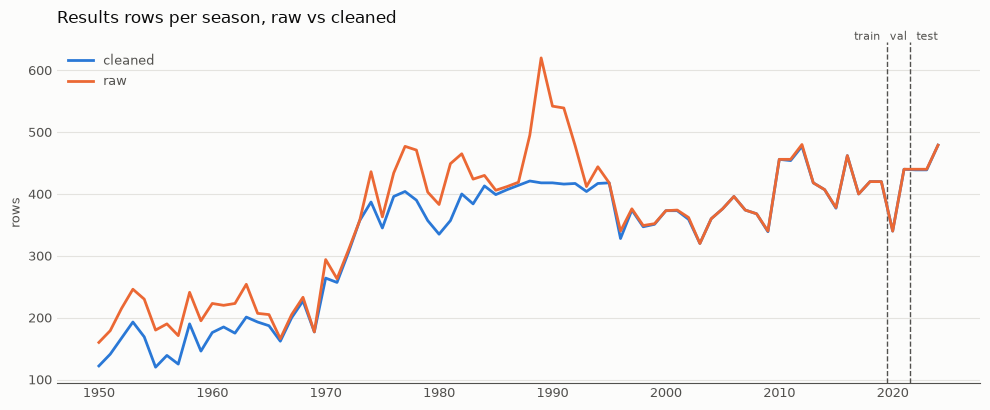

removed in total: 1998
seasons with most rows removed:


,cleaned,raw,removed
year,,,
1989,418,620,202
1990,418,542,124
1991,416,539,123
1981,357,449,92
1978,390,471,81
1988,421,495,74


In [36]:
rows_per_season = pd.DataFrame({
    "cleaned": clean_y.groupby("year").size(),
    "raw": raw_y.groupby("year").size(),
}).fillna(0).astype(int)
rows_per_season["removed"] = rows_per_season["raw"] - rows_per_season["cleaned"]

fig, ax = plots.new_figure()
plots.style_axes(ax, "Results rows per season, raw vs cleaned", ylabel="rows")
plots.plot_lines(ax, rows_per_season[["cleaned", "raw"]])
plots.mark_splits(ax, config.TRAIN_END_YEAR, config.TEST_START_YEAR)
fig.tight_layout()
plt.show()

print("removed in total:", int(rows_per_season["removed"].sum()))
print("seasons with most rows removed:")
display(rows_per_season.sort_values("removed", ascending=False).head(6))

**What it shows.** Cleaning removed 1,998 rows, and almost all of them come from before the mid-1990s.
- **Prequalifying era (D3).** The largest gaps are 1989 (620 → 418, −202), 1990 (−124) and 1991 (−123), followed by
  1981, 1978 and 1988. These are the years when many more cars entered than were allowed to start.
- **1950s (D2 and D1).** The raw line sits above the cleaned one throughout the decade. That is the Indianapolis 500
  and the shared drives.
- **Modern seasons are barely touched.** Only 9 rows were removed from 2003 onwards: none in validation (2020–21)
  and 2 in test (both D3 non-starters).

**Supports:** the impact of D1–D3. The cleaning decisions mainly change pre-1995 data, so how much they matter for the model
depends on the **training window**, which is still open. Validation and test are essentially unaffected.

### 7.2 Podium base rate per season, raw vs cleaned

**Question:** did cleaning change the class balance (podium rows ÷ rows), and does the base rate drift over time?

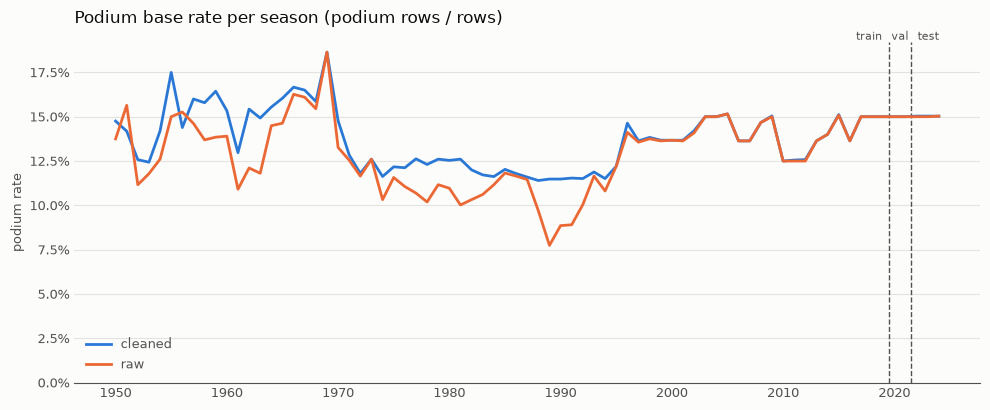

overall podium rate: raw 12.69%, cleaned 13.50%
cleaned, before 2003: 13.03% | 2003+: 14.33%
cleaned podium rate, lowest and highest seasons:


,cleaned rate
year,
1988,11.4%
1989,11.5%
1990,11.5%
1966,16.7%
1955,17.5%
1969,18.6%


In [37]:
podium_rate = pd.DataFrame({
    "cleaned": rate_by(clean_y, "year", "podium")["rate"],
    "raw": rate_by(raw_y, "year", "podium")["rate"],
})

fig, ax = plots.new_figure()
plots.style_axes(ax, "Podium base rate per season (podium rows / rows)", ylabel="podium rate", percent=True)
plots.plot_lines(ax, podium_rate)
plots.mark_splits(ax, config.TRAIN_END_YEAR, config.TEST_START_YEAR)
ax.set_ylim(0, None)
fig.tight_layout()
plt.show()

print(f"overall podium rate: raw {raw_y['podium'].mean():.2%}, cleaned {clean_y['podium'].mean():.2%}")
print(f"cleaned, before 2003: {clean_y.loc[clean_y['era'] == 'before 2003', 'podium'].mean():.2%} | "
      f"2003+: {clean_y.loc[clean_y['era'] == '2003+', 'podium'].mean():.2%}")
print("cleaned podium rate, lowest and highest seasons:")
display(podium_rate["cleaned"].sort_values().iloc[[0, 1, 2, -3, -2, -1]].to_frame("cleaned rate").style.format("{:.1%}"))

**What it shows.**
- **Cleaning raised the base rate.** Overall it goes from 12.69% raw to 13.50% cleaned. The difference is largest in
  1988–1992, where raw drops to about 8% because non-starters inflate the number of rows. Once they are removed, the
  cleaned rate stays at about 11.5% even then.
- **The base rate follows field size.** There are 3 podiums per race, so the rate is roughly 3 ÷ the number of starters.
  - The lowest cleaned seasons are 1988–1990 (about 11.5%), which had large fields.
  - The highest are 1969 (18.6%), 1955 and 1966, which had small fields.
  - 2017–2024 sit at exactly 15% because every race had 20 cars.
- **By era:** 13.0% before 2003 and 14.3% from 2003.

**Supports:** D3, since a podium rate computed with non-starters in the denominator would be misleading. It also shows
that the class balance is about 13–15% positive, which matters later for the choice of evaluation metric. The drift
with field size is evidence for the **training window / era** decision.

### 7.3 Starters per race, by season (cleaned)

**Question:** how many cars line up per race, and how much does that vary within and between seasons?

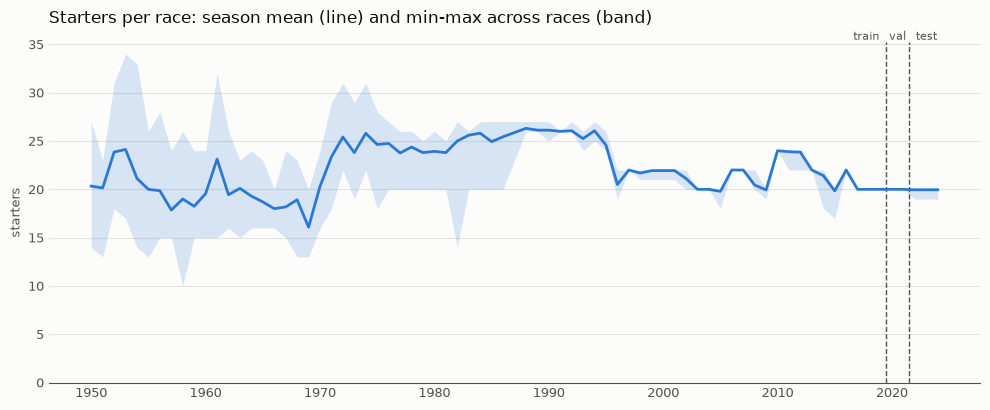

,mean,min,max
year,,,
1950,20.3,14,27
1953,24.1,17,34
1960,19.6,15,24
1970,20.3,16,24
1980,23.9,20,26
1989,26.1,26,27
1995,24.6,24,26
2003,20.0,20,20
2010,24.0,24,24


seasons with exactly 20 starters in every race: [2003, 2004, 2017, 2018, 2019, 2020, 2021]


In [38]:
per_race = clean_y.groupby(["year", "raceId"]).size()
field = per_race.groupby("year").agg(["mean", "min", "max"])
x = field.index.to_numpy(dtype=float)

fig, ax = plots.new_figure()
plots.style_axes(ax, "Starters per race: season mean (line) and min-max across races (band)", ylabel="starters")
ax.fill_between(x, field["min"], field["max"], color=plots.SERIES[0], alpha=0.18, linewidth=0, zorder=2)
ax.plot(x, field["mean"], color=plots.SERIES[0], linewidth=2, zorder=3)
plots.mark_splits(ax, config.TRAIN_END_YEAR, config.TEST_START_YEAR)
ax.set_ylim(0, None)
fig.tight_layout()
plt.show()

display(field.loc[[1950, 1953, 1960, 1970, 1980, 1989, 1995, 2003, 2010, 2024]].round(1))
print("seasons with exactly 20 starters in every race:",
      [int(y) for y in field.index if field.loc[y, "min"] == field.loc[y, "max"] == 20])

**What it shows.**
- **1950s–60s:** fields are small and vary a lot within a season, from 10 to 34 starters per race.
- **1970s–1995:** fields grow to 24–27 (1989: 26 in every race).
- **From 1996:** fields settle at 20–24. Every race has exactly 20 cars in 2003, 2004 and 2017–2021; 2024 has 19–20.

The counts include the 61 *Withdrew* rows with `grid > 0` that D3 keeps.

**Supports:** later feature design, plus the training window. The same grid slot means different things in different
fields: P10 of 34 is not P10 of 20. If several eras are combined, a relative position such as grid ÷ field size may be
needed *(Recommendation for the feature step, not decided here)*.

### 7.4 Podium rate by grid position (1–20), before 2003 vs 2003+

**Question:** how strongly does starting position predict a podium, and is that relationship the same in both eras?
`grid = 0` (meaning still pending) and grid positions above 20 are left out; their counts are printed below.

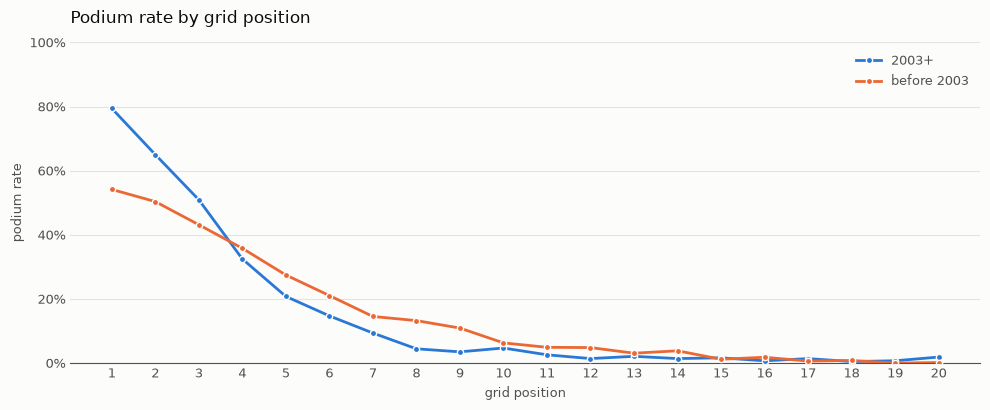

rows left out of this plot:

,grid_zero,grid_over_20
era,,
2003+,77,412
before 2003,51,2366


smallest n per (grid, era): 373


era,2003+,before 2003
grid,,
1,79.4%,54.2%
2,65.0%,50.4%
3,50.9%,43.1%
4,32.5%,35.8%
5,20.8%,27.5%
6,14.7%,21.1%
10,4.7%,6.3%


In [39]:
on_grid = clean_y[clean_y["grid"].between(1, 20)]
by_grid = rate_by(on_grid, ["grid", "era"], "podium")
grid_rate = by_grid["rate"].unstack("era")[["2003+", "before 2003"]]

fig, ax = plots.new_figure()
plots.style_axes(ax, "Podium rate by grid position", xlabel="grid position", ylabel="podium rate", percent=True)
plots.plot_lines(ax, grid_rate, marker=True)
ax.set_xticks(range(1, 21))
ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()

left_out = clean_y.assign(
    grid_zero=clean_y["grid"].eq(0), grid_over_20=clean_y["grid"].gt(20)
).groupby("era")[["grid_zero", "grid_over_20"]].sum()
print("rows left out of this plot:"); display(left_out)
print("smallest n per (grid, era):", int(by_grid["n"].min()))
display(grid_rate.loc[[1, 2, 3, 4, 5, 6, 10]].style.format("{:.1%}"))

**What it shows.** Grid position is strongly related to finishing on the podium in both eras, but the shape differs.
- **2003+:** the curve is much steeper. Pole converts 79.4% of the time, P2 65.0% and P3 50.9%.
- **Before 2003:** pole converts only 54.2% (P2 50.4%, P3 43.1%).
- **The curves cross at P4.** From P4 to about P10 the older era gives *more* podiums than today (P5: 27.5% vs 20.8%).
- **Rows left out:** grid 0 (51 before 2003, 77 from 2003) and grid > 20 (2,366 and 412). Each point is based on at
  least 373 rows.

**Supports:** the **training window / era** decision. A model trained across both eras would learn an average of two
different curves. It also shows why `grid = 0` needs a decided meaning before it is used as a number: it would otherwise
read as "better than pole".

### 7.5 Podium rate by qualifying position (2003+)

**Question:** is qualifying position informative in the seasons where we have it, and how does it relate to grid?

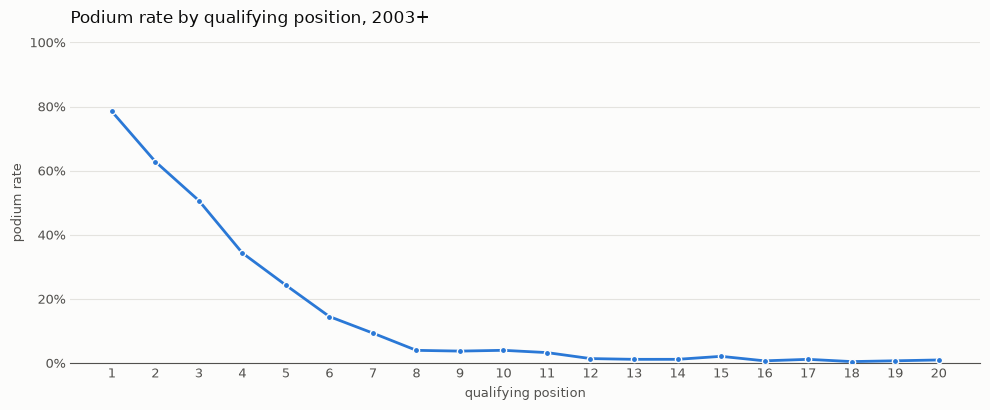

smallest n per qualifying position: 412
2003+ rows where grid == qualifying position: 72.4% (differences: grid penalties, pit-lane starts, missing qualifying)


,n,rate
quali_position,,
1,428,78.5%
2,428,62.9%
3,428,50.7%
4,428,34.3%
5,428,24.3%
6,427,14.5%
10,427,4.0%


In [40]:
q2003 = clean_q[(clean_q["year"] >= 2003) & clean_q["quali_position"].between(1, 20)]
by_quali = rate_by(q2003, "quali_position", "podium")

fig, ax = plots.new_figure()
plots.style_axes(ax, "Podium rate by qualifying position, 2003+", xlabel="qualifying position",
                 ylabel="podium rate", percent=True)
plots.plot_lines(ax, by_quali[["rate"]], marker=True)
ax.set_xticks(range(1, 21))
ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()

recent = clean_q[clean_q["year"] >= 2003]
same = (recent["grid"] == recent["quali_position"]).mean()
print(f"smallest n per qualifying position: {int(by_quali['n'].min())}")
print(f"2003+ rows where grid == qualifying position: {same:.1%} (differences: grid penalties, pit-lane starts, missing qualifying)")
display(by_quali.loc[[1, 2, 3, 4, 5, 6, 10], ["n", "rate"]].style.format({"rate": "{:.1%}"}))

**What it shows.**
- **Qualifying position is about as informative as grid from 2003.** The podium rate is 78.5% from qualifying P1,
  62.9% from P2, 50.7% from P3, 24.3% from P5 and 4.0% from P10. Each position has at least 412 rows.
- **But grid and qualifying position are not the same thing.** They agree in only 72.4% of 2003+ rows. The others
  differ because of grid penalties, pit-lane starts and the occasional missing qualifying row.

**Supports:** the qualifying-feature questions. It is evidence that qualifying data is usable and complete from 2003,
which bears on the missing-qualifying strategy and a possible 2003 start. Whether to use grid, qualifying position or
both is a feature decision for later; their 72% agreement suggests they carry overlapping but not identical information.

### 7.6 Non-finish rate per decade (cleaned)

**Question:** did reliability (the share of starters that do not finish) change by era?

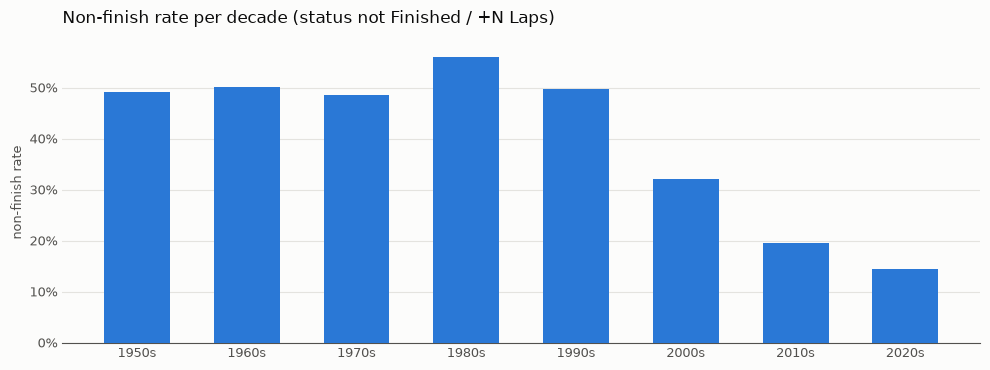

,n,n_flag,rate
decade,,,
1950,1512,743,49.1%
1960,1883,943,50.1%
1970,3462,1681,48.6%
1980,3948,2213,56.1%
1990,3890,1937,49.8%
2000,3638,1168,32.1%
2010,4291,840,19.6%
2020,2137,308,14.4%


In [41]:
clean_y["decade"] = (clean_y["year"] // 10 * 10).astype(int)
by_decade = rate_by(clean_y, "decade", "non_finish")

fig, ax = plots.new_figure(height=3.8)
plots.style_axes(ax, "Non-finish rate per decade (status not Finished / +N Laps)", ylabel="non-finish rate",
                 percent=True)
ax.bar([f"{d}s" for d in by_decade.index], by_decade["rate"], color=plots.SERIES[0], width=0.6, zorder=3)
ax.set_ylim(0, None)
fig.tight_layout()
plt.show()

display(by_decade.style.format({"rate": "{:.1%}"}))

**What it shows.**
- **1950s–1990s:** about half of all starters did not finish (49–50%), with a peak of 56.1% in the 1980s.
- **Since then reliability has improved sharply:** 32.1% in the 2000s, 19.6% in the 2010s and 14.4% in the 2020s.

This fits 7.4. When half the field retires, a midfield starter has a real chance of a podium, and even pole is far from
safe.

**Supports:** the **training window**. Older seasons follow different race dynamics, which argues for a later start
date, an era feature, or at least era-split evaluation. *(Evidence only; the window is not decided here.)*

### 7.7 Missingness per season: grid, qualifying position, q1 (cleaned)

**Question:** in which seasons are the pre-race fields missing? `grid` is never null (asserted below), so instead of a flat line
at 0% the chart shows the share of `grid = 0`. `q1 missing` is drawn dashed on top of `qualifying position missing`,
because the two lines overlap for most seasons. That value is **not** missing, but its meaning differs by era (4.1), so it is worth seeing alongside.

grid missing: 0 rows in every season (asserted), so it is not drawn as a line.


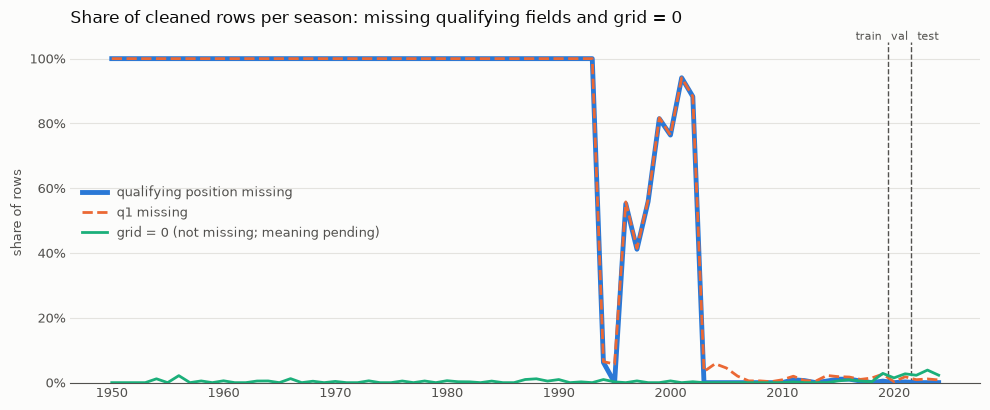

,quali_missing,q1_missing,grid_zero
era,,,
2003+,0.3%,1.6%,0.9%
before 2003,90.2%,90.4%,0.3%


2003+ seasons with the most q1 missing:


,qualifying position missing,q1 missing
year,,
2004,0.0%,5.8%
2005,0.0%,4.5%
2003,0.0%,3.4%
2019,0.5%,2.6%


In [42]:
assert clean_q["grid"].notna().all(), "grid has missing values"
print("grid missing: 0 rows in every season (asserted), so it is not drawn as a line.")

missing_by_season = clean_q.assign(
    quali_missing=clean_q["quali_position"].isna(),
    q1_missing=clean_q["q1"].isna(),
    grid_zero=clean_q["grid"].eq(0),
).groupby("year")[["quali_missing", "q1_missing", "grid_zero"]].mean()
missing_by_season.columns = [
    "qualifying position missing", "q1 missing", "grid = 0 (not missing; meaning pending)",
]

fig, ax = plots.new_figure()
plots.style_axes(ax, "Share of cleaned rows per season: missing qualifying fields and grid = 0",
                 ylabel="share of rows", percent=True)
# q1 is drawn dashed over a thicker solid line so the two overlapping series stay visible.
plots.plot_lines(ax, missing_by_season, linestyles=["-", "--", "-"], linewidths=[3.5, 2, 2])
plots.mark_splits(ax, config.TRAIN_END_YEAR, config.TEST_START_YEAR)
ax.set_ylim(0, 1.05)
fig.tight_layout()
plt.show()

eras = clean_q.assign(
    quali_missing=clean_q["quali_position"].isna(), q1_missing=clean_q["q1"].isna(), grid_zero=clean_q["grid"].eq(0)
)
display(eras.groupby("era")[["quali_missing", "q1_missing", "grid_zero"]].mean().style.format("{:.1%}"))
print("2003+ seasons with the most q1 missing:")
display(missing_by_season.loc[2003:, ["qualifying position missing", "q1 missing"]]
        .sort_values("q1 missing", ascending=False).head(4).style.format("{:.1%}"))

**What it shows.**
- **`grid` is never missing** (asserted).
- **Qualifying position** is missing for every row before 1994, for 53.7% of rows in 1994–2002, and for only 0.26% of
  rows from 2003. Before 2003 overall it is 90.2%.
- **`q1`** follows the same pattern but is a little less complete from 2003: 1.64% missing, worst in 2004 (5.8%),
  2005 (4.5%) and 2003 (3.4%). Those seasons used different qualifying formats. Why the time is missing while a
  position exists is *Unknown*.
- **`grid = 0`** is rare after cleaning: 0.32% of rows before 2003 and 0.86% from 2003. It drifts upward in the 2020s,
  in line with more pit-lane starts.

**Supports:**
- The **missing-qualifying strategy and the training window:** from 2003 the qualifying fields are essentially complete,
  while before 2003 they are mostly absent.
- **Feature choice:** qualifying position is more complete than the `q1` time.
- **The meaning of `grid = 0`:** it is a small but growing modern share.

*(All evidence only; none of these decisions is made here.)*

## 8. Data-engineering questions

Descriptive questions about the sport, answered from the cleaned results. Reusable code is in
`src/f1podium/de_questions.py`.

> **Cutoff note.** These analyses use **race outcomes** (who finished on the podium) to *describe* the data. They are
> not model features and nothing here feeds the prediction model, so the "known before lights-out" cutoff that
> governs features does **not** apply to them. They are also not used to select or tune anything.

### 8.1 Q1: which circuits convert a front-row start into a podium most often, and does the ranking change?

**Grain.** `results_clean` (section 6): one row per `(raceId, driverId)`, joined to `races` (year, round,
circuitId), to `circuits` (name), and **left-joined** to `qualifying` on `(raceId, driverId)` for the qualifying
position. Every join is checked: the keys must be unique, and the row count must be unchanged after each join.

**The answer is in 8.7.**

**Definitions**
- **Podium:** `positionOrder <= 3`.
- **Front row by grid:** `grid` in {1, 2}. `grid = 0` is never front row.
- **Front row by qualifying:** qualifying position in {1, 2}. A missing qualifying position is never front row.
- **Qualifying position and grid are different things:** penalties, pit-lane starts and others' penalties move cars.
  Both are reported, and 8.5 compares them directly.
- **Conversion rate:** podiums ÷ front-row starts, with a Wilson 95% interval.
- **Windows:** primary = 2003–2024 (complete qualifying data, both definitions). Secondary = grid-based, all years.
- **Eras:** ≤2013 vs ≥2014. **Minimum:** 10 front-row starts per circuit-era (`config.MIN_FRONT_ROW_STARTS`).

In [43]:
fr = de.build_front_row_table(results_clean, races, tables["circuits"], qualifying)

# The grain checks are also enforced inside build_front_row_table; repeated here so they are visible.
assert len(fr) == len(results_clean), "a join changed the row count"
assert not fr.duplicated(["raceId", "driverId"]).any(), "(raceId, driverId) is not unique"
assert not qualifying.duplicated(["raceId", "driverId"]).any(), "qualifying is not unique on (raceId, driverId)"
assert fr["grid"].notna().all()
assert not fr.loc[fr["grid"] == 0, "front_row_grid"].any(), "grid = 0 must never be front row"

print(f"rows: results_clean {len(results_clean)} -> joined table {len(fr)}")
print(f"qualifying rows: {len(qualifying)}, unique on (raceId, driverId): "
      f"{not qualifying.duplicated(['raceId', 'driverId']).any()}")

limit_rows = []
for definition, flag in [("grid", "front_row_grid"), ("quali", "front_row_quali")]:
    bad = de.races_over_front_row_limit(fr, flag)
    in_primary = bad["year"].between(*config.DE_WINDOW)
    assert not in_primary.any(), "a primary-window race has more than 2 front-row rows"
    limit_rows.append({
        "definition": definition,
        "races with > 2 front-row rows (all years)": len(bad),
        "of which in 2003-2024": int(in_primary.sum()),
        "years": ", ".join(map(str, sorted(bad["year"].unique()))) or "-",
    })
display(pd.DataFrame(limit_rows).set_index("definition"))

rows: results_clean 24761 -> joined table 24761
qualifying rows: 10494, unique on (raceId, driverId): True


,races with > 2 front-row rows (all years),of which in 2003-2024,years
definition,,,
grid,8,0,"1951, 1952, 1953, 1955, 1956, 1957, 1964"
quali,0,0,-


A front row holds two cars, so more than two front-row rows in a race signals a data quirk. By **qualifying**
there are none. By **grid** there are 8 races, all between 1951 and 1964: the same car's grid slot appears on two
drivers' rows (shared drives, see 6.3). None are in the primary window. They only affect the secondary all-years
window, where they add a few extra "front-row" starts.

### 8.2 Missingness: qualifying-position coverage, 2003–2024

**Question:** in the primary window, how many rows have no qualifying position? Those rows can never count as a front
row by qualifying, so this bounds how complete the qualifying-based answer is.

2003-2024: 8961 rows, 23 without a qualifying position (0.26%); lowest season: 2016 (98.92%)


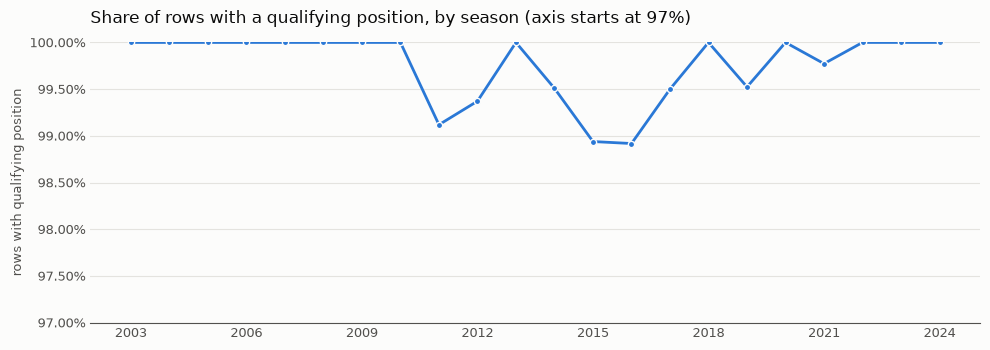

,n_rows,n_with_quali,coverage
year,,,
2011,454,450,0.991189
2012,477,474,0.993711
2014,407,405,0.995086
2015,377,373,0.98939
2016,462,457,0.989177
2017,400,398,0.995
2019,420,418,0.995238
2021,440,439,0.997727


In [44]:
cov = de.quali_coverage_by_season(fr)
missing_rows = int((cov["n_rows"] - cov["n_with_quali"]).sum())
print(f"2003-2024: {int(cov['n_rows'].sum())} rows, {missing_rows} without a qualifying position "
      f"({missing_rows / cov['n_rows'].sum():.2%}); lowest season: {int(cov['coverage'].idxmin())} "
      f"({cov['coverage'].min():.2%})")

fig, ax = plots.new_figure(height=3.6)
plots.style_axes(ax, "Share of rows with a qualifying position, by season (axis starts at 97%)",
                 ylabel="rows with qualifying position", percent=True)
plots.plot_lines(ax, cov[["coverage"]], marker=True)
ax.set_ylim(0.97, 1.0)
ax.set_xticks(range(config.DE_WINDOW[0], config.DE_WINDOW[1] + 1, 3))
fig.tight_layout()
plt.show()

display(cov.loc[cov["n_with_quali"] < cov["n_rows"]])

**What it shows (missingness).**
- **Qualifying position is almost complete in the primary window:** 23 of 8,961 rows (0.26%) have none. 2003–2010 are
  complete; the lowest season is 2016 (98.92%). Eight seasons have any gap (table above).
- **It does not affect the grid-based answer.** All 854 grid front-row starts in 2003–2024 have a qualifying position
  (see the 2 × 2 table in 8.6), so none of the 23 rows is a grid front-row start. For the qualifying-based answer, a
  missing position can only mean "not counted as front row".
- **`grid` itself is never missing**, and neither are year, round or circuit after the joins (asserted).

### 8.3 Conversion per circuit and era; effect of the minimum-starts rule

The tables below hold **every circuit × era × definition** (columns `rate`, `ci_low`, `ci_high`, `meets_min`).
Circuits below the minimum are not ranked, because a rate from a handful of starts is mostly noise. The second table
shows what each threshold drops (10 is the configured value; 5 and 20 show how sensitive that choice is).

In [45]:
conv = de.conversion_tables(fr)
assert conv.groupby(["window", "definition", "era", "circuitId"]).size().max() == 1, "duplicate circuit-era rows"
assert (conv["n_podium"] <= conv["n_front_row"]).all()

print("circuit-era cells (all, then those meeting the minimum):")
display(
    conv.groupby(["window", "definition", "era"], sort=False)
    .agg(circuits=("circuitId", "size"), meeting_min=("meets_min", "sum"),
         front_row_starts=("n_front_row", "sum"), podiums=("n_podium", "sum"))
    .assign(rate=lambda d: d["podiums"] / d["front_row_starts"])
)

print("circuits dropped by each minimum-starts threshold:")
thr = de.threshold_report(conv, (5, config.MIN_FRONT_ROW_STARTS, 20))
display(
    thr.set_index(["window", "definition", "era", "min_starts"])
    [["circuits_with_starts", "circuits_dropped", "circuits_kept", "starts_in_dropped"]]
)

circuit-era cells (all, then those meeting the minimum):


circuits  meeting_min  front_row_starts  podiums      rate
window    definition era                                                              
2003–2024 grid       ≤2013        27           21               400      272  0.680000
                     ≥2014        32           19               454      345  0.759912
          quali      ≤2013        27           21               400      269  0.672500
                     ≥2014        32           19               456      336  0.736842
all years grid       ≤2013        69           45              1781      994  0.558113
                     ≥2014        32           19               454      345  0.759912

circuits dropped by each minimum-starts threshold:


circuits_with_starts  circuits_dropped  circuits_kept  starts_in_dropped
window    definition era   min_starts                                                                          
2003–2024 grid       ≤2013 5                             27                 3             24                 10
                           10                            27                 6             21                 32
                           20                            27                17             10                184
                     ≥2014 5                             32                 5             27                 16
                           10                            32                13             19                 75
                           20                            32                22             10                230
          quali      ≤2013 5                             27                 3             24                 10
                           10                            27                 6             21                 32
                           20                            27                17             10                184
                     ≥2014 5                             32                 5             27                 16
                           10                            32                13             19                 76
                           20                            32                21             11                212
all years grid       ≤2013 5                             69                17             52                 48
                           10                            69                24             45                 98
                           20                            69                40             29                312
                     ≥2014 5                             32                 5             27                 16
                           10                            32                13             19                 75
                           20                            32                22             10                230

**What it shows.**
- **At the configured minimum (10 front-row starts, i.e. 5 races), 21 of 27 circuits are kept in ≤2013 and 19 of 32 in
  ≥2014.** That drops 6 circuits (32 of 400 starts, 8%) and 13 circuits (75 of 454 starts, 17%). The qualifying-based
  table is the same for ≤2013 and drops 13 circuits (76 starts) for ≥2014.
- **≥2014 loses more circuits because many appear only a few times** (e.g. Sepang 7 starts, Hockenheimring 8,
  Istanbul Park 4, Nürburgring 2). Dropping them removes few starts, so the rates are still based on most of the data.
- **The threshold is a real choice.** At 5 starts only 3 and 5 circuits drop; at 20 (10 races) just 10–11 circuits are kept
  per era. The tables above let you see the rest.
- **All-years window:** 24 of 69 circuits (98 of 1,781 starts) drop in ≤2013, circuits with few front-row starts in the old data.

### 8.4 Top circuits per era (primary window, both definitions)

**Question:** which circuits convert front-row starts into podiums most often, and do the grid-based and
qualifying-based answers agree? Circuits are ranked by their **grid-based** rate within each era (only circuits meeting
the minimum); the qualifying-based rate is drawn next to it for the same circuits. Dots are rates, bars are Wilson
95% intervals.

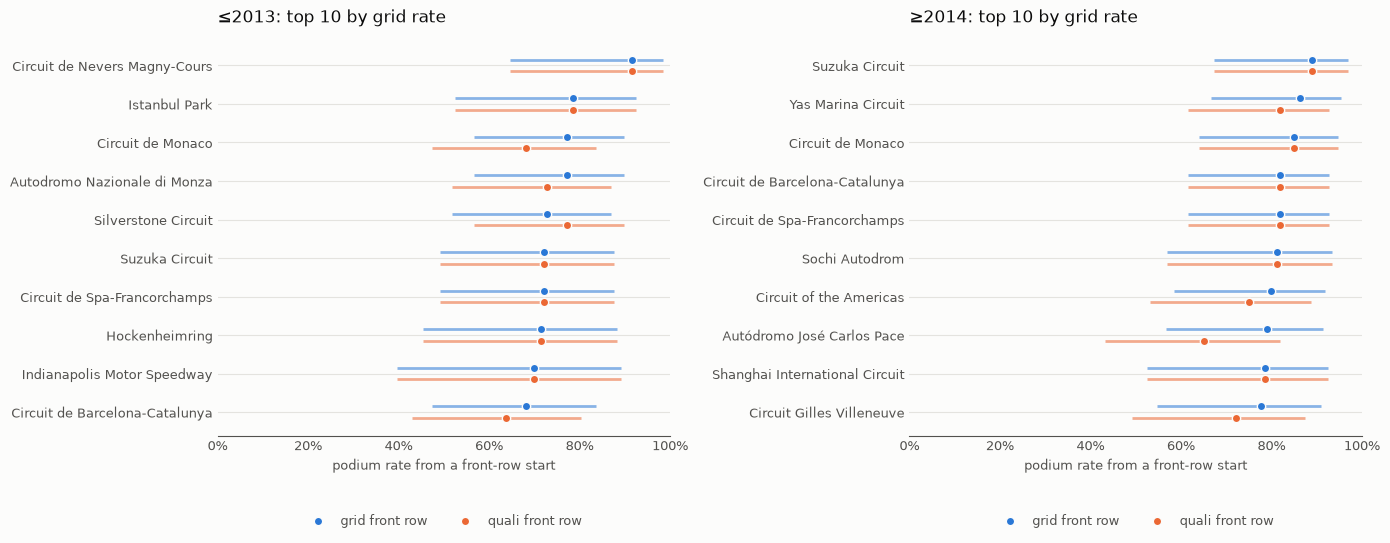

≤2013: top 10 by grid-based rate


,grid: podiums/starts,grid: rate,grid: 95% interval,quali: podiums/starts,quali: rate
Circuit de Nevers Magny-Cours,11/12,92%,65% - 99%,11/12,92%
Istanbul Park,11/14,79%,52% - 92%,11/14,79%
Circuit de Monaco,17/22,77%,57% - 90%,15/22,68%
Autodromo Nazionale di Monza,17/22,77%,57% - 90%,16/22,73%
Silverstone Circuit,16/22,73%,52% - 87%,17/22,77%
Suzuka Circuit,13/18,72%,49% - 88%,13/18,72%
Circuit de Spa-Francorchamps,13/18,72%,49% - 88%,13/18,72%
Hockenheimring,10/14,71%,45% - 88%,10/14,71%
Indianapolis Motor Speedway,7/10,70%,40% - 89%,7/10,70%
Circuit de Barcelona-Catalunya,15/22,68%,47% - 84%,14/22,64%


≥2014: top 10 by grid-based rate


,grid: podiums/starts,grid: rate,grid: 95% interval,quali: podiums/starts,quali: rate
Suzuka Circuit,16/18,89%,67% - 97%,16/18,89%
Yas Marina Circuit,19/22,86%,67% - 95%,18/22,82%
Circuit de Monaco,17/20,85%,64% - 95%,17/20,85%
Circuit de Barcelona-Catalunya,18/22,82%,61% - 93%,18/22,82%
Circuit de Spa-Francorchamps,18/22,82%,61% - 93%,18/22,82%
Sochi Autodrom,13/16,81%,57% - 93%,13/16,81%
Circuit of the Americas,16/20,80%,58% - 92%,15/20,75%
Autódromo José Carlos Pace,15/19,79%,57% - 91%,13/20,65%
Shanghai International Circuit,11/14,79%,52% - 92%,11/14,79%
Circuit Gilles Villeneuve,14/18,78%,55% - 91%,13/18,72%


circuit pairs whose 95% intervals do not overlap:


circuits  pairs  pairs_with_non_overlapping_ci  share
era   definition                                                       
≤2013 grid              21    210                              0    0.0
      quali             21    210                              0    0.0
≥2014 grid              19    171                              0    0.0
      quali             19    171                              0    0.0

In [46]:
TOP_N = 10
primary = conv[conv["window"] == de.WINDOW_PRIMARY]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), facecolor=plots.SURFACE, sharex=True)
top_tables = {}
for ax, era in zip(axes, de.ERAS):
    g = primary[(primary["era"] == era) & primary["meets_min"]]
    by_def = {d: g[g["definition"] == d].set_index("circuit") for d in ("grid", "quali")}
    assert all(t.index.is_unique for t in by_def.values()), "circuit names are not unique"
    top = by_def["grid"].sort_values("rate", ascending=False).head(TOP_N).index.tolist()
    ax.set_facecolor(plots.SURFACE)
    plots.rate_dot_plot(ax, top, {"grid front row": by_def["grid"], "quali front row": by_def["quali"]})
    plots.style_axes(ax, f"{era}: top {TOP_N} by grid rate",
                     xlabel="podium rate from a front-row start")
    grid_top = by_def["grid"].loc[top]  # rank order; the explicit index below keeps the columns aligned
    quali_top = by_def["quali"].reindex(top)
    top_tables[era] = pd.DataFrame({
        "grid: podiums/starts": grid_top["n_podium"].astype(str) + "/" + grid_top["n_front_row"].astype(str),
        "grid: rate": grid_top["rate"],
        "grid: 95% interval": grid_top["ci_low"].map("{:.0%}".format) + " - " + grid_top["ci_high"].map("{:.0%}".format),
        "quali: podiums/starts": quali_top["n_podium"].astype("Int64").astype(str) + "/"
                                 + quali_top["n_front_row"].astype("Int64").astype(str),
        "quali: rate": quali_top["rate"],
    }, index=top)
fig.tight_layout()
plt.show()

for era in de.ERAS:
    print(f"{era}: top {TOP_N} by grid-based rate")
    display(top_tables[era].style.format({"grid: rate": "{:.0%}", "quali: rate": "{:.0%}"}))

# How much of the within-era ordering is resolved by the data? Pairs of circuits (meeting the minimum)
# whose 95% intervals do not overlap.
sep_rows = []
for era in de.ERAS:
    for definition in ("grid", "quali"):
        g = primary[(primary["era"] == era) & (primary["definition"] == definition) & primary["meets_min"]]
        n_pairs, n_separated = de.ci_separated_pairs(g["ci_low"], g["ci_high"])
        sep_rows.append({"era": era, "definition": definition, "circuits": len(g), "pairs": n_pairs,
                         "pairs_with_non_overlapping_ci": n_separated, "share": n_separated / n_pairs})
print("circuit pairs whose 95% intervals do not overlap:")
display(pd.DataFrame(sep_rows).set_index(["era", "definition"]).round(3))

**What it shows.**
- **Highest conversion by grid (podiums / front-row starts).** ≤2013: Magny-Cours 11/12 (92%), Istanbul Park 11/14 (79%),
  Monaco 17/22 and Monza 17/22 (77%), Silverstone 16/22 (73%). ≥2014: Suzuka 16/18 (89%), Yas Marina 19/22 (86%),
  Monaco 17/20 (85%), Barcelona 18/22 and Spa 18/22 (82%). Monaco is in the top three in both eras.
- **Grid-based and qualifying-based rates mostly sit on top of each other.** Among the plotted circuits the biggest gaps are Monaco ≤2013
  (77% vs 68%) and Interlagos ≥2014 (79% vs 65%): cars that qualified on the front row but started further back
  (8.6).
- **The ordering within an era is not statistically resolved.** The intervals are about ±10–20 points wide. In every era
  and definition the highest lower bound (65–67%) is below the lowest upper bound (75–77%), so **no pair of circuits has
  non-overlapping 95% intervals** (0 of 171–210 pairs). The top-10 lists describe the point estimates. Overlapping
  intervals mean the circuits are *not distinguishable at this sample size*; they do not show that there is *no difference*.

**Overall (primary window, grid-based):** 68.0% of front-row starts became podiums in ≤2013 (272/400, 95% interval
63.3%–72.4%) and 76.0% in ≥2014 (345/454, 71.9%–79.7%). By qualifying: 67.2% (269/400) and 73.7% (336/456).
The difference between eras is tested in 8.5.

### 8.5 Does the ranking change between eras?

**Question:** are the circuits that convert best in ≤2013 also the ones that convert best in ≥2014?
Each point is a circuit that meets the minimum in **both** eras; the dashed line is y = x (the axes are zoomed to the
data, and are the same on both). The table gives the
Spearman rank correlation of the circuit rates between eras, for circuits present in both eras, with and without the
minimum-starts rule.

**First, the overall level.** All front-row starts in 2003–2024, ≤2013 vs ≥2014, for both definitions: the
difference (new − old), a Newcombe 95% interval and a two-sided two-proportion z-test. Each start is treated as an
independent trial; starts from the same race (pole and P2) and the same circuit are correlated, so the interval is
somewhat too narrow and the p-value somewhat too small.

In [47]:
era_diff = de.overall_era_difference(fr)
level_rows = []
for r in era_diff.itertuples():
    level_rows.append({
        "definition": r.definition,
        "≤2013 podiums/starts": f"{r.podiums_old}/{r.starts_old}",
        "≤2013 rate": f"{r.rate_old:.1%}",
        "≥2014 podiums/starts": f"{r.podiums_new}/{r.starts_new}",
        "≥2014 rate": f"{r.rate_new:.1%}",
        "difference (pct points)": f"{100 * r.diff:+.1f}",
        "95% interval": f"{100 * r.ci_low:+.1f} to {100 * r.ci_high:+.1f}",
        "z": round(r.z, 2),
        "p (two-sided)": f"{r.p_value:.4f}",
    })
display(pd.DataFrame(level_rows).set_index("definition"))

,≤2013 podiums/starts,≤2013 rate,≥2014 podiums/starts,≥2014 rate,difference (pct points),95% interval,z,p (two-sided)
definition,,,,,,,,
grid,272/400,68.0%,345/454,76.0%,+8.0,+2.0 to +14.0,2.60,0.0093
quali,269/400,67.2%,336/456,73.7%,+6.4,+0.3 to +12.5,2.06,0.0391


**Then the ranking.** Spearman rank correlation of the circuit rates between eras (circuits present in both eras),
with an approximate 95% interval; the scatter shows the same circuits against the y = x line.

n_circuits_both_eras  spearman_both_eras  n_circuits_min_both  spearman_min_both  spearman_min_both_ci_low  spearman_min_both_ci_high
window    definition                                                                                                                                       
2003–2024 grid                          21                0.14                   14               0.30                     -0.28                       0.72
          quali                         21                0.26                   14               0.57                      0.01                       0.86
all years grid                          24                0.03                   16              -0.03                     -0.52                       0.47

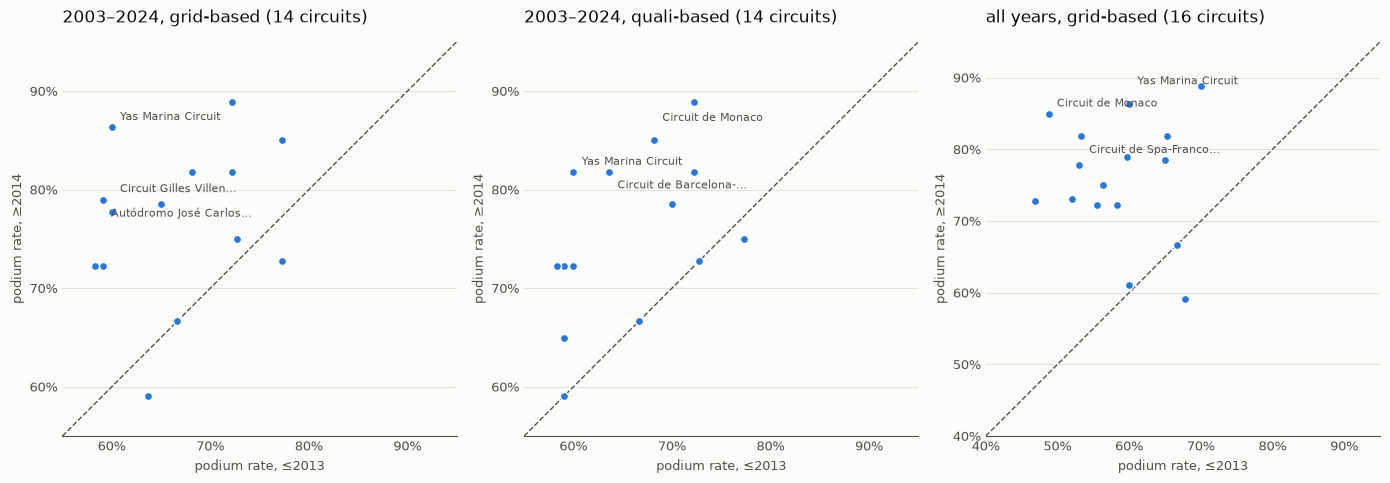

circuits  above_diagonal (higher in >=2014)  median change (pct points)
window    definition                                                                         
2003–2024 grid              14                                 11                        13.4
          quali             14                                 10                        10.9
all years grid              16                                 14                        18.8

In [48]:
rank_corr = de.era_rank_correlation(conv)
display(rank_corr.set_index(["window", "definition"]).round(2))

above_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4.9), facecolor=plots.SURFACE)
for ax, (window, definition) in zip(axes, [(de.WINDOW_PRIMARY, "grid"), (de.WINDOW_PRIMARY, "quali"),
                                          (de.WINDOW_ALL, "grid")]):
    g = conv[(conv["window"] == window) & (conv["definition"] == definition) & conv["meets_min"]]
    wide = g.pivot(index="circuit", columns="era", values="rate").reindex(columns=list(de.ERAS)).dropna()
    ax.set_facecolor(plots.SURFACE)
    plots.identity_scatter(ax, wide[de.ERA_OLD], wide[de.ERA_NEW])
    above_rows.append({
        "window": window, "definition": definition, "circuits": len(wide),
        "above_diagonal (higher in >=2014)": int((wide[de.ERA_NEW] > wide[de.ERA_OLD]).sum()),
        "median change (pct points)": round(100 * float((wide[de.ERA_NEW] - wide[de.ERA_OLD]).median()), 1),
    })
    plots.style_axes(ax, f"{window}, {definition}-based ({len(wide)} circuits)",
                     xlabel=f"podium rate, {de.ERA_OLD}", ylabel=f"podium rate, {de.ERA_NEW}")
fig.tight_layout()
plt.show()

display(pd.DataFrame(above_rows).set_index(["window", "definition"]))

**What it shows.**
- **The overall level rose, and the rise is unlikely to be chance.** By grid: 68.0% → 76.0%, +8.0 points (95% interval
  +2.0 to +14.0; z = 2.60, p = 0.009). By qualifying: 67.2% → 73.7%, +6.4 points (+0.3 to +12.5; z = 2.06, p = 0.039).
  The qualifying interval only just excludes zero. Both treat starts as independent, so the true uncertainty is somewhat
  larger than shown.
- **Most of the change is a level shift, not a reshuffle.** 11 of 14 circuits lie above the y = x line by grid (10 of 14 by
  qualifying), with a median rise of about 13 (grid) and 11 (qualifying) percentage points, in line with the overall
  68% → 76%. Reliability improved over the same period (7.6).
- **Rank agreement between eras is weak but uncertain.** Spearman ρ for the 14 circuits that meet the minimum in both eras
  is 0.30 by grid (approximate 95% interval −0.28 to 0.72) and 0.57 by qualifying (0.01 to 0.86). Using all 21
  circuits present in both eras: 0.14 and 0.26. Over all years, grid-based: −0.03 (16 circuits, −0.52 to 0.47).
- **How to read this:** the ranking is **not reproduced** from one era to the other. But with per-circuit uncertainty
  this large (8.4: no pair separable), a low correlation is expected even if the true circuit effects were stable, so
  the data cannot tell a real change in the ranking from noise. The higher qualifying-based value is within that noise.

### 8.6 Qualifying front row vs grid front row, 2003–2024

**Question:** how often does the front row by qualifying differ from the front row by grid, and do those cars convert
differently? Only rows with a qualifying position are included. The second table is the plain 2 × 2 count.

In [49]:
cells = de.grid_vs_quali_cells(fr)
with_q = fr[fr["year"].between(*config.DE_WINDOW) & fr["quali_position"].notna()]
assert cells["n"].sum() == len(with_q), "cells do not add up to the rows with qualifying"

display(
    pd.crosstab(with_q["front_row_quali"].rename("front row by quali"),
                with_q["front_row_grid"].rename("front row by grid"), margins=True)
)
display(
    cells.assign(rate=lambda d: d["rate"].round(3), ci_low=lambda d: d["ci_low"].round(3),
                 ci_high=lambda d: d["ci_high"].round(3))
    .sort_values("n", ascending=False).set_index("cell")
)

front row by grid,False,True,All
front row by quali,,,
False,8046,36,8082
True,38,818,856
All,8084,854,8938


,n,n_podium,rate,ci_low,ci_high
cell,,,,,
neither,8046,656,0.082,0.076,0.088
front row on both,818,594,0.726,0.695,0.756
grid front row only (moved up),36,23,0.639,0.476,0.775
"quali front row, grid 3+ (lost it on the grid)",36,11,0.306,0.180,0.469
"quali front row, grid = 0 (pit lane / no grid slot)",2,0,0.000,0.000,0.658


**What it shows.**
- **The two definitions rarely disagree.** Of the 856 qualifying front-row rows, 38 (4.4%) did not start on the front
  row: 36 started P3 or lower and 2 had `grid = 0` (pit lane). 36 cars started on the front row without qualifying there
  (4.2% of the 854 grid front-row starts).
- **The grid tracks the outcome better than qualifying.** Front row by both: 72.6% podium (594/818; 95% interval
  69.5%–75.6%). Qualified front row but started P3 or lower: 30.6% (11/36; 18.0%–46.9%), less than half, with a
  non-overlapping interval. Moved up to the front row on the grid: 63.9% (23/36; 47.6%–77.5%), compatible with the
  72.6%. The two pit-lane starts did not convert (0/2; too few to say anything). All other starts: 8.2% (656/8,046).
- **Why the circuit rates barely differ by definition:** only about 4% of front-row starts change, so most circuits'
  grid-based and qualifying-based rates move together (8.4).

*(This describes the data. Which of the two to use as a model feature is a feature-design decision, not made here.)*

### 8.7 Answer to Q1

**Which circuits convert a front-row start into a podium most often?**
- **Overall (2003–2024, grid-based): 68.0% (272/400) in ≤2013 and 76.0% (345/454) in ≥2014.**
- **Highest point estimates by grid (podiums / front-row starts):** ≤2013: Magny-Cours 11/12 (92%), Istanbul Park 11/14
  (79%), Monaco 17/22 and Monza 17/22 (77%), Silverstone 16/22 (73%). ≥2014: Suzuka 16/18 (89%), Yas Marina 19/22
  (86%), Monaco 17/20 (85%), Barcelona 18/22 and Spa 18/22 (82%).
- **These orderings are not distinguishable at this sample size.** No two circuits have non-overlapping 95% intervals
  within an era (10–22 front-row starts each). That is not the same as "no difference".

**Does it change from ≤2013 to ≥2014?**
- **The overall level rose:** +8.0 points by grid (95% interval +2.0 to +14.0, p = 0.009) and +6.4 by qualifying
  (+0.3 to +12.5, p = 0.039). 11 of 14 circuits are higher in ≥2014 by grid.
- **The order is only weakly reproduced:** Spearman 0.30 by grid and 0.57 by qualifying (14 circuits), with wide
  intervals. The data **cannot separate a real change in the ranking from noise.**

**Qualifying position vs grid.** They differ for about 4% of front-row starts. Cars that qualified on the front row but
started P3 or lower converted 31% (11/36), against 73% (594/818) for cars on the front row by both, so the grid is what
tracks the result. The definitions give nearly the same circuit rates because so few rows change.

**Grain and missingness.** One row per `(raceId, driverId)` of the cleaned results (24,761 rows); joins to races, circuits
and (left) qualifying were checked for unique keys and unchanged row counts. 23 of 8,961 rows in 2003–2024 (0.26%)
have no qualifying position; none is a grid front-row start.

**Limitations**
- **`circuitId` pools layout changes.** A circuit is one `circuitId` even when the track changed, for example Yas Marina
  (modified for 2021) and Barcelona-Catalunya (final chicane removed for 2023). The rate for such a circuit mixes layouts,
  so it describes the venue, not one specific track. *(Layout history is outside knowledge, not in the dataset.)*
- **Overlapping intervals mean "not distinguishable at this n", not "no difference".** With 10–22 starts per circuit, only
  large differences could show up.
- **The tests and intervals treat starts as independent.** Starts from the same race (pole and P2) are correlated, so
  the reported uncertainty is somewhat too small.
- **Eras are a coarse split.** Cars, rules and circuit layouts changed within each era.
- **The secondary all-years window** includes 8 races (1951–1964) where shared drives put more than two cars on the grid's
  front row; it is shown for context only.
- **Descriptive analysis of race outcomes.** Not a model feature, so the prediction cutoff does not apply.

### 8.8 Q2: do drivers podium more often in their home country, controlling for starting position?

**The answer is in 8.12.**

> **Cutoff note.** Like Q1, this is a descriptive analysis of race outcomes (podiums). It is not a model feature, so
> the "known before lights-out" cutoff does not apply.

**Grain.** `results_clean`: one row per `(raceId, driverId)`, joined to `races` (year, circuitId), `circuits` (country)
and `drivers` (nationality). Every join is checked: unique keys, and an unchanged row count.

**Definitions**
- **Home:** the driver's nationality maps to the circuit's country. The mapping is
  `src/f1podium/reference/nationality_to_country.csv` (nationality, country, note), with country values spelled exactly
  as in `circuits.country`, or `no circuit` when the nationality has no circuit in the data.
  - A nationality can have **more than one** country: American maps to both `USA` and `United States`, because
    `circuits.csv` spells the Las Vegas Strip (2023–24) `United States`. The two dual nationalities map to both countries.
  - Home is a lookup on unique (nationality, country) pairs, so it never adds rows.
  - Reviewed choices: East German → Germany; Rhodesian and Irish → `no circuit`; `'Argentinian '` has a trailing space
    in `drivers.csv` and is stripped.
- **Podium:** `positionOrder <= 3`.
- **Grid buckets** (`config.GRID_BUCKETS`): 1, 2–3, 4–6, 7–10, 11+, and 0 = pit lane.
- **Pooled effect:** Cochran–Mantel–Haenszel (CMH) odds ratio of a podium at home vs away, stratified by grid bucket.
  Robustness: a logistic regression `podium ~ home + C(grid_bucket) + C(decade)` with standard errors clustered by driver.
  Sensitivity: (a) drivers with at least 1 home and 10 away races; (b) 2003 onwards.

In [50]:
nat_map = de.load_nationality_map()
map_check = de.check_nationality_map(nat_map, tables["drivers"], tables["circuits"])
assert map_check["unmapped_nationalities"] == [], map_check
assert map_check["unknown_countries"] == [], map_check

home_df = de.build_home_table(results_clean, races, tables["circuits"], tables["drivers"], nat_map)
assert len(home_df) == len(results_clean), "a join changed the row count"
assert not home_df.duplicated(["raceId", "driverId"]).any()
print(f"rows: results_clean {len(results_clean)} -> home table {len(home_df)}")

rows: results_clean 24761 -> home table 24761


### 8.9 Mapping and missingness

**Question:** does every driver have a usable nationality and every row a grid position, and how many rows can be
"home" at all?

In [51]:
print("mapping check:", map_check)

countries_with_home_drivers = set(nat_map.loc[nat_map["country"] != de.NO_CIRCUIT, "country"])
coverage = pd.Series({
    "rows": len(home_df),
    "home rows": int(home_df["home"].sum()),
    "away rows": int((~home_df["home"]).sum()),
    "rows whose nationality is unmapped": int((~home_df["mapped"]).sum()),
    "rows whose nationality has no circuit in the data": int((~home_df["has_home_circuit"]).sum()),
    "rows at circuits in a country with no matching nationality": int(
        (~home_df["circuit_country"].isin(countries_with_home_drivers)).sum()),
    "rows with null grid": int(home_df["grid"].isna().sum()),
    "rows with no grid bucket": int(home_df["grid_bucket"].isna().sum()),
}).to_frame("count")
assert coverage.loc["rows whose nationality is unmapped", "count"] == 0
assert coverage.loc["rows with null grid", "count"] == 0
display(coverage)

print("nationalities with more than one country, and annotated (reviewed) rows of the mapping:")
display(nat_map[(nat_map["note"] != "") | nat_map.duplicated("nationality", keep=False)].reset_index(drop=True))

mapping check: {'unmapped_nationalities': [], 'unknown_countries': [], 'drivers_without_nationality': 0}


,count
rows,24761
home rows,1950
away rows,22811
rows whose nationality is unmapped,0
rows whose nationality has no circuit in the data,2362
rows at circuits in a country with no matching nationality,1705
rows with null grid,0
rows with no grid bucket,0


nationalities with more than one country, and annotated (reviewed) rows of the mapping:


,nationality,country,note
0,American,USA,
1,American,United States,circuits.csv spells the Las Vegas Strip (2023-...
2,American-Italian,USA,dual nationality: home in both countries
3,American-Italian,Italy,dual nationality: home in both countries
4,Argentine-Italian,Argentina,dual nationality: home in both countries
5,Argentine-Italian,Italy,dual nationality: home in both countries
6,Argentinian,Argentina,drivers.csv has a trailing space ('Argentinian...
7,East German,Germany,ambiguous: German GPs of 1952-53 were in West ...
8,Irish,no circuit,Ireland is not the UK; Northern Irish drivers ...
9,Rhodesian,no circuit,ambiguous: all races at the South African GP; ...


**What it shows (missingness).**
- **The mapping is complete.** All 43 driver nationalities map (0 unmapped), and every mapped country is either a
  `circuits.country` value or `no circuit` (asserted). No driver lacks a nationality and no row lacks a grid position.
- **1,950 of 24,761 rows (7.9%) are home starts.**
- **Two groups can only ever be "away":** 2,362 rows from nationalities with no circuit in the data, and 1,705 rows at
  circuits in countries that no nationality maps to (e.g. Bahrain, UAE).
- **The reviewed mapping choices** (table above) touch fewer than 40 rows in total.

### 8.10 Home vs away podium rate per grid bucket

**Question:** within the same starting-position bucket, do drivers podium more often at home? Each row label shows the
number of home and away starts; dots are rates and bars are Wilson 95% intervals.

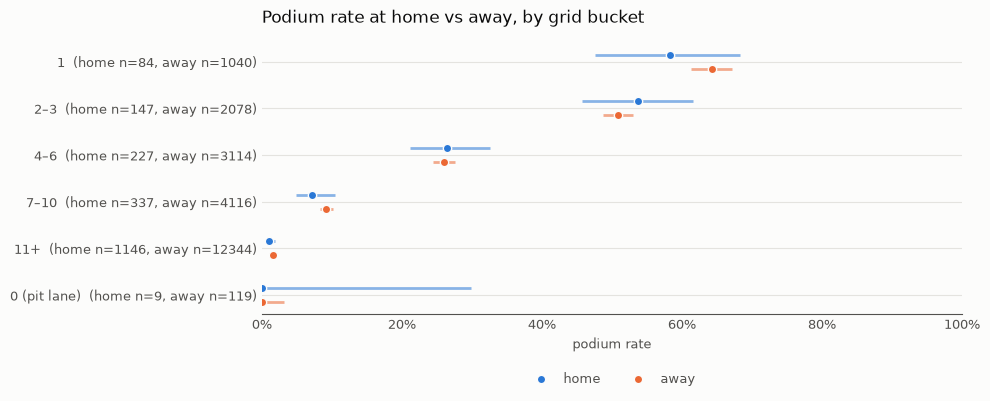

,home: podiums/n,home: rate,home: 95% interval,away: podiums/n,away: rate,away: 95% interval
grid bucket,,,,,,
1,49/84,58.3%,48% - 68%,668/1040,64.2%,61% - 67%
2–3,79/147,53.7%,46% - 62%,1057/2078,50.9%,49% - 53%
4–6,60/227,26.4%,21% - 33%,810/3114,26.0%,25% - 28%
7–10,24/337,7.1%,5% - 10%,379/4116,9.2%,8% - 10%
11+,12/1146,1.0%,1% - 2%,204/12344,1.7%,1% - 2%
0 (pit lane),0/9,0.0%,0% - 30%,0/119,0.0%,0% - 3%


In [52]:
rates = de.bucket_rates(home_df)
assert rates["n"].sum() == home_df["grid_bucket"].notna().sum()

wide = rates.pivot(index="grid_bucket", columns="side", values=["n", "podiums", "rate", "ci_low", "ci_high"])
order = [b for b in de.grid_bucket_labels()[1:] + de.grid_bucket_labels()[:1] if b in wide.index]
labels = {b: f"{b}  (home n={int(wide.loc[b, ('n', 'home')])}, away n={int(wide.loc[b, ('n', 'away')])})"
          for b in order}
series = {}
for side in ("home", "away"):
    frame = rates[rates["side"] == side].set_index("grid_bucket")[["rate", "ci_low", "ci_high"]]
    series[side] = frame.rename(index=labels)

fig, ax = plots.new_figure(height=4.2)
plots.rate_dot_plot(ax, [labels[b] for b in order], series, max_label=60)
plots.style_axes(ax, "Podium rate at home vs away, by grid bucket", xlabel="podium rate")
fig.tight_layout()
plt.show()

table = pd.DataFrame({
    "home: podiums/n": [f"{int(wide.loc[b, ('podiums', 'home')])}/{int(wide.loc[b, ('n', 'home')])}" for b in order],
    "home: rate": [wide.loc[b, ("rate", "home")] for b in order],
    "home: 95% interval": [f"{wide.loc[b, ('ci_low', 'home')]:.0%} - {wide.loc[b, ('ci_high', 'home')]:.0%}" for b in order],
    "away: podiums/n": [f"{int(wide.loc[b, ('podiums', 'away')])}/{int(wide.loc[b, ('n', 'away')])}" for b in order],
    "away: rate": [wide.loc[b, ("rate", "away")] for b in order],
    "away: 95% interval": [f"{wide.loc[b, ('ci_low', 'away')]:.0%} - {wide.loc[b, ('ci_high', 'away')]:.0%}" for b in order],
}, index=pd.Index(order, name="grid bucket"))
display(table.style.format({"home: rate": "{:.1%}", "away: rate": "{:.1%}"}))

**What it shows.**
- **Within each grid bucket, home and away rates are close.** Home vs away: from P1 58.3% (49/84) vs 64.2% (668/1,040);
  P2–3 53.7% (79/147) vs 50.9% (1,057/2,078); P4–6 26.4% (60/227) vs 26.0% (810/3,114); P7–10 7.1% (24/337) vs 9.2%
  (379/4,116); P11+ 1.0% (12/1,146) vs 1.7% (204/12,344).
- **The direction is not consistent:** home is a little higher in P2–3 and P4–6, and a little lower in P1, P7–10 and P11+.
- **Every home interval overlaps its away interval.** That means the two are *not distinguishable at this sample size*
  (84–1,146 home starts per bucket), not that they are equal.
- **Pit lane:** no podiums at home or away (0/9, 0/119). The bucket carries no information on the odds ratio, so it is
  left out of the pooled estimates below.

### 8.11 Pooled home effect: CMH, logistic regression and sensitivity analyses

**Question:** pooling the grid buckets, is the odds of a podium at home different from away? An odds ratio (OR) above 1
means more podiums at home. Strata with no podiums carry no information on the OR and are dropped (listed in the table).
The CMH test treats every row as independent; the logistic model clusters standard errors by driver.

In [53]:
effects = de.q2_effects(home_df)
shown = effects[["analysis", "method", "n_rows", "n_home", "odds_ratio", "ci_low", "ci_high", "p_value",
                 "homogeneity_p", "strata_dropped"]].copy()
shown["strata_dropped"] = shown["strata_dropped"].map(", ".join)
display(shown.set_index(["analysis", "method"]).round({"odds_ratio": 3, "ci_low": 3, "ci_high": 3,
                                                       "p_value": 4, "homogeneity_p": 3}))
logit_row = effects[effects["method"].str.startswith("logistic")].iloc[0]
assert logit_row["converged"], "the logistic regression did not converge"
print(f"logistic: {int(logit_row['n_drivers'])} driver clusters, converged = {logit_row['converged']}")

n_rows  n_home  odds_ratio  ci_low  ci_high  p_value  homogeneity_p strata_dropped
analysis                                        method                                                                                                                                
main (all years)                                CMH, stratified by grid bucket                       24633    1941       0.908   0.764    1.079   0.2787          0.312   0 (pit lane)
                                                logistic + grid bucket + decade, clustered by d...   24633    1941       0.912   0.743    1.119   0.3764            NaN   0 (pit lane)
(a) drivers with >= 1 home and >= 10 away races CMH, stratified by grid bucket                       19570    1533       0.927   0.776    1.109   0.4096          0.592   0 (pit lane)
(b) 2003+ only                                  CMH, stratified by grid bucket                        8884     364       0.765   0.516    1.133   0.1771          0.842   0 (pit lane)

logistic: 686 driver clusters, converged = True


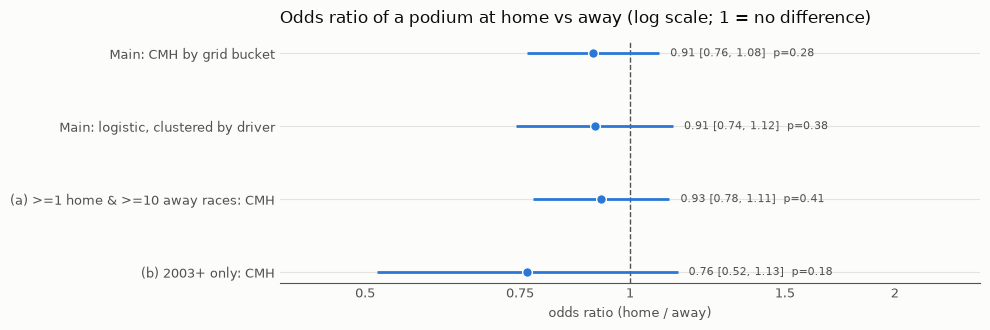

In [54]:
from matplotlib.ticker import FixedLocator, FuncFormatter

short = [
    "Main: CMH by grid bucket",
    "Main: logistic, clustered by driver",
    "(a) >=1 home & >=10 away races: CMH",
    f"(b) {config.Q2_RECENT_START_YEAR}+ only: CMH",
]
y = np.arange(len(effects))[::-1]
fig, ax = plots.new_figure(height=3.4)
ax.axvline(1.0, color=plots.INK_MUTED, linewidth=1, linestyle="--", zorder=1)
ax.hlines(y, effects["ci_low"], effects["ci_high"], color=plots.SERIES[0], linewidth=2, zorder=2)
ax.plot(effects["odds_ratio"], y, "o", color=plots.SERIES[0], markersize=7, markeredgecolor=plots.SURFACE, zorder=3)
for yi, r in zip(y, effects.itertuples()):
    ax.annotate(f"{r.odds_ratio:.2f} [{r.ci_low:.2f}, {r.ci_high:.2f}]  p={r.p_value:.2f}", (r.ci_high, yi),
                xytext=(8, 0), textcoords="offset points", va="center", color=plots.INK_MUTED, fontsize=8)
ax.set_xscale("log")
ax.set_xlim(0.4, 2.5)
ax.xaxis.set_major_locator(FixedLocator([0.5, 0.75, 1.0, 1.5, 2.0]))
ax.xaxis.set_minor_locator(FixedLocator([]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_yticks(y)
ax.set_yticklabels(short)
plots.style_axes(ax, "Odds ratio of a podium at home vs away (log scale; 1 = no difference)",
                 xlabel="odds ratio (home / away)")
fig.tight_layout()
plt.show()

**What it shows.**
- **Main CMH estimate: OR 0.91 (95% interval 0.76–1.08), p = 0.28**, on 24,633 rows (1,941 home); the pit-lane bucket is
  dropped. The Breslow–Day p = 0.31 gives no evidence that the odds ratio differs between grid buckets, so pooling them is
  reasonable.
- **Logistic regression with decade, clustered by driver (686 drivers): OR 0.91 (0.74–1.12), p = 0.38.** The same answer
  once era is controlled and the correlation between one driver's races is allowed for.
- **Sensitivity (a), drivers with at least 1 home and 10 away races:** OR 0.93 (0.78–1.11), p = 0.41 (19,570 rows,
  1,533 home). **(b) 2003 onwards:** OR 0.76 (0.52–1.13), p = 0.18 (8,884 rows, 364 home); fewer home starts, so a wider
  interval.
- **All four intervals include 1, and all four point estimates are below 1.**

### 8.12 Answer to Q2

**No evidence of a home advantage.** Holding the starting-position bucket fixed, the odds of a podium at home vs away are
**OR 0.91 (95% interval 0.76–1.08, p = 0.28)** (Cochran–Mantel–Haenszel).
- The data are compatible with anything from about 24% lower to 8% higher odds at home. A large home advantage is
  unlikely; a small effect in either direction cannot be ruled out.
- **The result is robust:** logistic regression with decade and driver-clustered errors 0.91 (0.74–1.12); drivers with
  at least 1 home and 10 away races 0.93 (0.78–1.11); 2003 onwards 0.76 (0.52–1.13). Every interval includes 1.
- **Per bucket, home vs away:** P1 58.3% (49/84) vs 64.2% (668/1,040); P2–3 53.7% (79/147) vs 50.9% (1,057/2,078);
  P4–6 26.4% (60/227) vs 26.0% (810/3,114); P7–10 7.1% (24/337) vs 9.2% (379/4,116); P11+ 1.0% (12/1,146) vs 1.7%
  (204/12,344); pit lane 0/9 vs 0/119.

**Grain and missingness.** One row per `(raceId, driverId)` of the cleaned results (24,761 rows); joins to races,
circuits and drivers checked for unique keys and unchanged row counts. 0 unmapped nationalities, 0 null grid positions.
1,950 rows are home starts.

**Limitations**
- **One nationality field.** It does not capture dual nationality (two dual nationalities are mapped to both countries),
  residence, or a team's home. "Home" is a simplification.
- **Confounding by driver strength and selection.** Home and away rows come from different mixes of drivers, and local
  one-off entries in weaker cars were common at home races in early decades. Sensitivity (a) addresses this only partly. A
  within-driver comparison (e.g. a conditional logistic model by driver) would be the next step *(Experiment)*.
- **Mapping choices.** East German → Germany, Rhodesian and Irish → `no circuit`, and the US spelling split are judgement
  calls; together they touch fewer than 40 rows.
- **Grid buckets are coarse.** Starting positions still differ within a bucket.
- **Independence.** The CMH test treats rows as independent; the logistic model clusters by driver and agrees.
- **Overlapping intervals mean "not distinguishable at this n", not "no difference".**
- **Descriptive analysis of race outcomes.** Not a model feature, so the prediction cutoff does not apply.

### 8.13 Q3: which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**The answer is in 8.17.**

> **Cutoff note: `status` is post-race.** A car's status (Engine, Collision, Finished, ...) is only known after the race.
> This question *describes* reliability, so the prediction cutoff does not apply here. **`status` and anything
> derived from it for the current race must never be a model feature.**

**Grain.** `results_clean`: one row per `(raceId, driverId)` (a race start), joined to `races` (year), `constructors`
(name) and `status` (status text), then to the status-category mapping. Every join is many-to-one and checked for an
unchanged row count; a null `statusId` or an unmapped status raises. Rows outside 2014–2024 are dropped after the joins.

**Definitions**
- **Status category:** `src/f1podium/reference/status_category.csv` maps every one of the 139 statuses to
  *finished*, *mechanical*, *accident_driver*, *regulatory* or *other*. Ambiguous statuses are flagged and carry an
  alternative category (e.g. `Retired` → other, alternative mechanical).
- **Mechanical retirement:** a race start whose status category is *mechanical*.
- **Rate:** mechanical retirements ÷ starts, per `constructorId` and era, with a Wilson 95% interval.
- **Eras:** 2014–2021 (hybrid era before the 2022 rules) and 2022–2024 (`config.Q3_ERAS`).
- **Minimum:** 40 starts per constructor-era (`config.Q3_MIN_STARTS`, about one season with two cars).
- **Sensitivity:** (a) renamed or bought teams merged into lineages (`reference/constructor_lineage.csv`);
  (b) ambiguous statuses switched to their alternative category.

In [55]:
status_map = de.load_status_categories()
status_check = de.check_status_categories(status_map, tables["status"])
assert status_check == {"unmapped_statuses": [], "unknown_statuses": []}, status_check
assert results_clean["statusId"].notna().all(), "null statusId in results_clean"

ret = de.build_retirement_table(results_clean, races, tables["constructors"], tables["status"], status_map)
assert not ret.duplicated(["raceId", "driverId"]).any()
in_eras = results_clean["raceId"].isin(
    races.loc[races["year"].between(config.Q3_ERAS[0][1], config.Q3_ERAS[-1][2]), "raceId"])
assert len(ret) == in_eras.sum(), "the era filter should be the only step that removes rows"

lineage = de.load_constructor_lineage()
ret_lin = de.add_lineage(ret, lineage, tables["constructors"])
print(f"rows: results_clean {len(results_clean)} -> joined (all checks passed) -> {len(ret)} in "
      f"{config.Q3_ERAS[0][1]}–{config.Q3_ERAS[-1][2]}")
print("starts per era:", ret.groupby("era").size().to_dict())

rows: results_clean 24761 -> joined (all checks passed) -> 4623 in 2014–2024
starts per era: {'2014–2021': 3266, '2022–2024': 1357}


### 8.14 Mapping and missingness

**Question:** how are race starts split across the status categories, and how many rows depend on a judgement call
(an ambiguous status)?

In [56]:
cat_counts = pd.crosstab(ret["category"], ret["era"], margins=True, margins_name="total")
cat_share = pd.crosstab(ret["category"], ret["era"], normalize="columns")
display(cat_counts.join(cat_share.add_suffix(" share").round(3)))

print("ambiguous statuses that occur in the eras (rows per era), with the main and alternative category:")
amb_rows = (
    ret[ret["ambiguous"]].groupby(["status", "category", "alt_category", "era"]).size()
    .unstack("era", fill_value=0).reset_index()
)
display(amb_rows.sort_values(amb_rows.columns[-2], ascending=False).reset_index(drop=True))

missing = pd.Series({
    "null statusId in results_clean": int(results_clean["statusId"].isna().sum()),
    "statuses not in the mapping": len(status_check["unmapped_statuses"]),
    "rows on an ambiguous status": int(ret["ambiguous"].sum()),
    "rows whose mechanical flag flips under (b)": int((ret["mechanical"] != ret["mechanical_alt"]).sum()),
}).to_frame("count")
display(missing)

era,2014–2021,2022–2024,total,2014–2021 share,2022–2024 share
category,,,,,
accident_driver,221,90,311,0.068,0.066
finished,2660,1165,3825,0.814,0.859
mechanical,314,82,396,0.096,0.060
other,63,16,79,0.019,0.012
regulatory,8,4,12,0.002,0.003
total,3266,1357,4623,NaN,NaN


ambiguous statuses that occur in the eras (rows per era), with the main and alternative category:


era,status,category,alt_category,2014–2021,2022–2024
0,Retired,other,mechanical,38,12
1,Wheel,mechanical,other,11,0
2,Withdrew,other,mechanical,8,3
3,Puncture,other,mechanical,7,0
4,Tyre,other,mechanical,4,0
5,Wheel nut,other,mechanical,3,0
6,Damage,accident_driver,mechanical,2,0
7,Rear wing,mechanical,accident_driver,2,1
8,Front wing,accident_driver,mechanical,2,1
9,Debris,accident_driver,mechanical,1,0


,count
null statusId in results_clean,0
statuses not in the mapping,0
rows on an ambiguous status,103
rows whose mechanical flag flips under (b),103


**What it shows (missingness).**
- **Nothing is missing.** 0 null `statusId` in the cleaned results and 0 statuses without a category (asserted); every
  join kept the row count. 4,623 starts fall in 2014–2024: 3,266 in 2014–2021 and 1,357 in 2022–2024.
- **Mechanical retirements are 9.6% of starts in 2014–2021 (314) and 6.0% in 2022–2024 (82).** Finishes rose from
  81.4% to 85.9%; accident/driver retirements stayed at about 7% (221 and 90).
- **103 starts (2.2%) carry an ambiguous status**, and all 103 change their mechanical flag under sensitivity (b).
  `Retired` is most of it (38 + 12), then `Wheel` (11 + 0) and `Withdrew` (8 + 3).

### 8.15 Mechanical-retirement rate per constructor and era

**Question:** which constructors retire with a mechanical failure most often in each era? Constructors are ranked by rate
within each era (only those meeting the minimum); dots are rates and bars are Wilson 95% intervals. The label shows
mechanical retirements / starts.

minimum 40 starts: constructor-eras dropped per era: {'2014–2021': 2, '2022–2024': 0} | kept: {'2014–2021': 17, '2022–2024': 12}


,era,label,n_mech,starts,rate
0,2014–2021,Marussia,3,31,0.096774
1,2014–2021,Caterham,8,34,0.235294


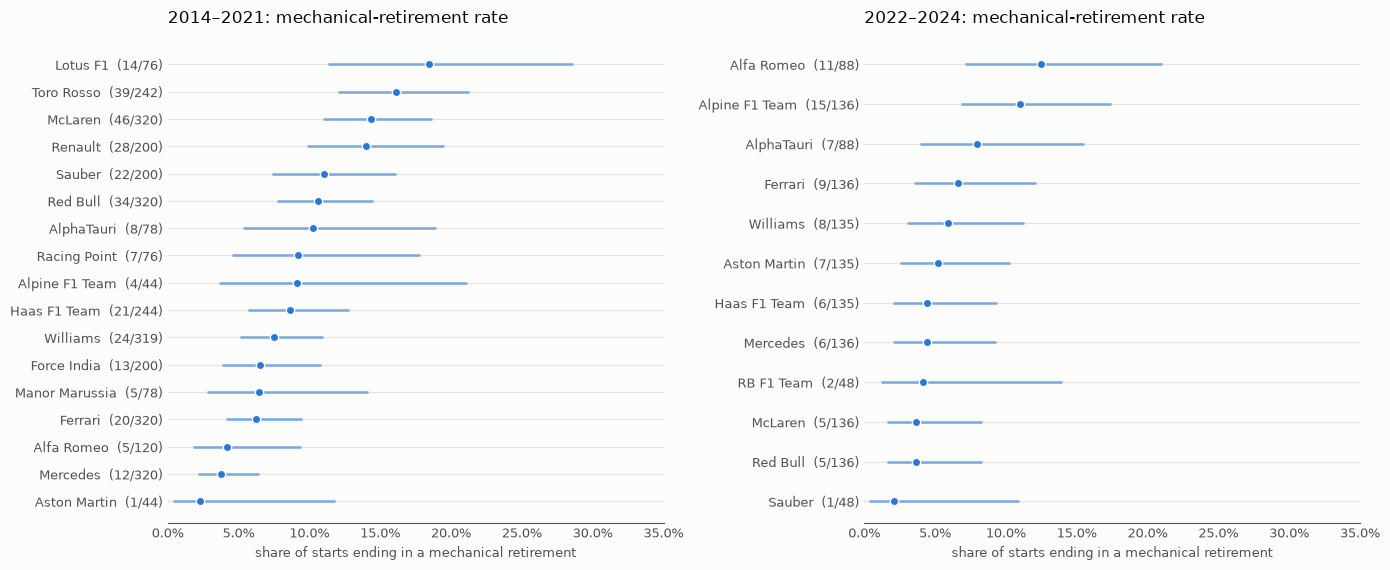

2014–2021: constructors meeting the minimum, by rate


,mechanical/starts,rate,95% interval
constructor,,,
Lotus F1,14/76,18.4%,11.3% - 28.6%
Toro Rosso,39/242,16.1%,12.0% - 21.3%
McLaren,46/320,14.4%,11.0% - 18.6%
Renault,28/200,14.0%,9.9% - 19.5%
Sauber,22/200,11.0%,7.4% - 16.1%
Red Bull,34/320,10.6%,7.7% - 14.5%
AlphaTauri,8/78,10.3%,5.3% - 19.0%
Racing Point,7/76,9.2%,4.5% - 17.8%
Alpine F1 Team,4/44,9.1%,3.6% - 21.2%


2022–2024: constructors meeting the minimum, by rate


,mechanical/starts,rate,95% interval
constructor,,,
Alfa Romeo,11/88,12.5%,7.1% - 21.0%
Alpine F1 Team,15/136,11.0%,6.8% - 17.4%
AlphaTauri,7/88,8.0%,3.9% - 15.5%
Ferrari,9/136,6.6%,3.5% - 12.1%
Williams,8/135,5.9%,3.0% - 11.3%
Aston Martin,7/135,5.2%,2.5% - 10.3%
Haas F1 Team,6/135,4.4%,2.1% - 9.4%
Mercedes,6/136,4.4%,2.0% - 9.3%
RB F1 Team,2/48,4.2%,1.2% - 14.0%


constructor pairs whose 95% intervals do not overlap:


,constructors,pairs,pairs_with_non_overlapping_ci
era,,,
2014–2021,17,136,21
2022–2024,12,66,0


In [57]:
q3_rates = de.mechanical_rates(ret)
assert (q3_rates["n_mech"] <= q3_rates["starts"]).all()
assert q3_rates.groupby("era")["starts"].sum().to_dict() == ret.groupby("era").size().to_dict()
q3_eras = [label for label, _, _ in config.Q3_ERAS]

dropped = q3_rates[~q3_rates["meets_min"]]
print(f"minimum {config.Q3_MIN_STARTS} starts: constructor-eras dropped per era:",
      {era: int((dropped["era"] == era).sum()) for era in q3_eras},
      "| kept:", {era: int(((q3_rates["era"] == era) & q3_rates["meets_min"]).sum()) for era in q3_eras})
display(dropped[["era", "label", "n_mech", "starts", "rate"]].reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), facecolor=plots.SURFACE, sharex=True)
q3_tables = {}
for ax, era in zip(axes, q3_eras):
    g = q3_rates[(q3_rates["era"] == era) & q3_rates["meets_min"]].sort_values("rate", ascending=False)
    g = g.assign(row=g["label"] + "  (" + g["n_mech"].astype(str) + "/" + g["starts"].astype(str) + ")")
    assert g["row"].is_unique
    ax.set_facecolor(plots.SURFACE)
    plots.rate_dot_plot(ax, g["row"].tolist(), {"mechanical": g.set_index("row")}, max_label=40)
    ax.set_xlim(0, 0.35)
    plots.style_axes(ax, f"{era}: mechanical-retirement rate", xlabel="share of starts ending in a mechanical retirement")
    q3_tables[era] = pd.DataFrame({
        "mechanical/starts": (g["n_mech"].astype(str) + "/" + g["starts"].astype(str)).to_numpy(),
        "rate": g["rate"].to_numpy(),
        "95% interval": (g["ci_low"].map("{:.1%}".format) + " - " + g["ci_high"].map("{:.1%}".format)).to_numpy(),
    }, index=pd.Index(g["label"], name="constructor"))
fig.tight_layout()
plt.show()

for era in q3_eras:
    print(f"{era}: constructors meeting the minimum, by rate")
    display(q3_tables[era].style.format({"rate": "{:.1%}"}))

sep_rows = []
for era in q3_eras:
    g = q3_rates[(q3_rates["era"] == era) & q3_rates["meets_min"]]
    n_pairs, n_sep = de.ci_separated_pairs(g["ci_low"], g["ci_high"])
    sep_rows.append({"era": era, "constructors": len(g), "pairs": n_pairs, "pairs_with_non_overlapping_ci": n_sep})
print("constructor pairs whose 95% intervals do not overlap:")
display(pd.DataFrame(sep_rows).set_index("era"))

**What it shows.**
- **The minimum drops 2 of 19 constructors in 2014–2021** (Caterham 8/34 and Marussia 3/31, both 2014 only) and none of
  12 in 2022–2024.
- **2014–2021, highest rates:** Lotus F1 18.4% (14/76), Toro Rosso 16.1% (39/242), McLaren 14.4% (46/320), Renault
  14.0% (28/200). **Lowest:** Aston Martin 2.3% (1/44; 2021 only), Mercedes 3.8% (12/320), Alfa Romeo 4.2% (5/120).
- **2022–2024, highest rates:** Alfa Romeo 12.5% (11/88), Alpine 11.0% (15/136), AlphaTauri 8.0% (7/88).
  **Lowest:** Sauber 2.1% (1/48; 2024 only), McLaren and Red Bull 3.7% (5/136 each).
- **2014–2021 is partly resolved:** 21 of 136 constructor pairs have non-overlapping 95% intervals, e.g. Mercedes
  (2.2%–6.4%) is clearly below McLaren (11.0%–18.6%) and Toro Rosso (12.0%–21.3%).
- **2022–2024 is not resolved:** 0 of 66 pairs have non-overlapping intervals. With 48–136 starts and rates near 5%,
  the ordering is *not distinguishable at this sample size*; that is not the same as "no difference".

### 8.16 Did it change between eras?

**Question:** did the overall mechanical-retirement rate change from 2014–2021 to 2022–2024, and are the least reliable
constructors in one era also the least reliable in the other? The overall comparison is the difference (new − old) with
a Newcombe 95% interval and a two-sided two-proportion z-test; each start is treated as independent (two cars of the
same team in the same race are correlated, so the uncertainty is somewhat understated). The scatter shows constructors
meeting the minimum in both eras against the y = x line.

,2014–2021: mech/starts,2014–2021: rate,2022–2024: mech/starts,2022–2024: rate,difference (pct points),95% interval,z,p (two-sided),Spearman (groups in both eras)
main (constructorId),314/3266,9.6%,82/1357,6.0%,-3.6,-5.1 to -1.9,-3.95,7.8e-05,"-0.46 [-0.84, 0.23], n=11"
(a) lineages merged,314/3266,9.6%,82/1357,6.0%,-3.6,-5.1 to -1.9,-3.95,7.8e-05,"0.08 [-0.58, 0.68], n=10"
(b) ambiguous statuses flipped,365/3266,11.2%,92/1357,6.8%,-4.4,-6.1 to -2.6,-4.56,5.1e-06,"-0.49 [-0.85, 0.19], n=11"


,dropped by minimum,top 3 2014–2021,top 3 2022–2024
main (constructorId),2,"Lotus F1 18.4% (14/76), Toro Rosso 16.1% (39/242), McLaren 14.4% (46/320)","Alfa Romeo 12.5% (11/88), Alpine F1 Team 11.0% (15/136), AlphaTauri 8.0% (7/88)"
(a) lineages merged,1,"Minardi / Toro Rosso / AlphaTauri / RB 14.7% (47/320), McLaren 14.4% (46/320), Toleman / Benetton / Renault / Lotus ...","Toleman / Benetton / Renault / Lotus / Alpine 11.0% (15/136), Sauber / BMW Sauber / Alfa Romeo 8.8% (12/136), Minard..."
(b) ambiguous statuses flipped,2,"Lotus F1 23.7% (18/76), Toro Rosso 18.2% (44/242), Renault 16.0% (32/200)","Alfa Romeo 12.5% (11/88), Alpine F1 Team 11.0% (15/136), RB F1 Team 10.4% (5/48)"


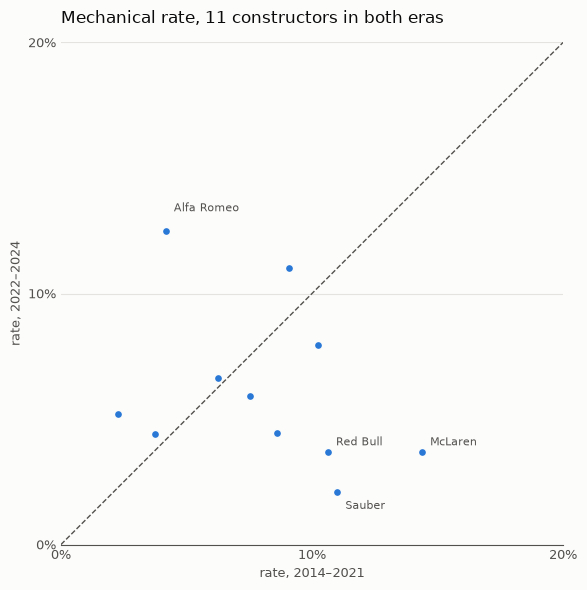

below the y = x line (lower rate in the newer era): 6 of 11


In [58]:
def q3_summary(df, by, flag):
    rates_ = de.mechanical_rates(df, by=by, flag=flag)
    change = de.overall_mechanical_change(df, flag=flag)
    rho = de.mechanical_rank_correlation(rates_, by=by)
    tops = {era: ", ".join(
                f"{r.label} {r.rate:.1%} ({r.n_mech}/{r.starts})"
                for r in rates_[(rates_["era"] == era) & rates_["meets_min"]]
                .sort_values("rate", ascending=False).head(3).itertuples())
            for era in q3_eras}
    return {
        f"{q3_eras[0]}: mech/starts": f"{change['mech_old']}/{change['starts_old']}",
        f"{q3_eras[0]}: rate": f"{change['rate_old']:.1%}",
        f"{q3_eras[1]}: mech/starts": f"{change['mech_new']}/{change['starts_new']}",
        f"{q3_eras[1]}: rate": f"{change['rate_new']:.1%}",
        "difference (pct points)": f"{100 * change['diff']:+.1f}",
        "95% interval": f"{100 * change['ci_low']:+.1f} to {100 * change['ci_high']:+.1f}",
        "z": round(change["z"], 2), "p (two-sided)": f"{change['p_value']:.2g}",
        "Spearman (groups in both eras)": f"{rho['spearman']:.2f} [{rho['ci_low']:.2f}, {rho['ci_high']:.2f}], n={rho['n_both_eras']}",
        "dropped by minimum": int((~rates_["meets_min"]).sum()),
        f"top 3 {q3_eras[0]}": tops[q3_eras[0]], f"top 3 {q3_eras[1]}": tops[q3_eras[1]],
    }

q3_sens = pd.DataFrame({
    "main (constructorId)": q3_summary(ret, "constructorId", "mechanical"),
    "(a) lineages merged": q3_summary(ret_lin, "lineage", "mechanical"),
    "(b) ambiguous statuses flipped": q3_summary(ret, "constructorId", "mechanical_alt"),
}).T
with pd.option_context("display.max_colwidth", 120):
    display(q3_sens.iloc[:, :9])
    display(q3_sens.iloc[:, 9:])

wide = (q3_rates[q3_rates["meets_min"]]
        .pivot(index="constructorId", columns="era", values="rate").reindex(columns=q3_eras).dropna())
names = q3_rates[q3_rates["era"] == q3_eras[1]].set_index("constructorId")["label"]
wide.index = names.reindex(wide.index).to_numpy()
fig, ax = plots.new_figure(width=6.2, height=6.0)
plots.identity_scatter(ax, wide[q3_eras[0]], wide[q3_eras[1]], label_top=4)
plots.style_axes(ax, f"Mechanical rate, {len(wide)} constructors in both eras",
                 xlabel=f"rate, {q3_eras[0]}", ylabel=f"rate, {q3_eras[1]}")
fig.tight_layout()
plt.show()
print("below the y = x line (lower rate in the newer era):", int((wide[q3_eras[1]] < wide[q3_eras[0]]).sum()),
      "of", len(wide))

**What it shows.**
- **The overall rate fell, and the fall is unlikely to be chance.** 9.6% (314/3,266) → 6.0% (82/1,357): −3.6 points
  (95% interval −5.1 to −1.9; z = −3.95, p = 0.00008). Treating starts as independent makes this somewhat too precise.
- **The ranking is not reproduced between eras.** For the 11 constructorIds that meet the minimum in both eras, Spearman
  ρ = −0.46 (approximate 95% interval −0.84 to 0.23). With lineages merged, ρ = 0.08 (−0.58 to 0.68), n = 10. Both
  intervals are wide and include 0, so the data cannot tell a stable reliability order from a reshuffle.
- **6 of 11 constructors are below the y = x line** (lower rate in 2022–2024).
- **Sensitivity (a), lineages merged** (`reference/constructor_lineage.csv`, the same mapping the modeling table uses):
  the overall rates are the same by construction.
  - **2014–2021 top three:** Minardi / Toro Rosso / AlphaTauri / RB 14.7% (47/320), then McLaren and Toleman / Benetton
    / Renault / Lotus / Alpine, both 14.4% (46/320).
  - **2022–2024 top three:** Toleman / … / Alpine 11.0% (15/136), Sauber / BMW Sauber / Alfa Romeo 8.8% (12/136), then
    Ferrari and Minardi / … / RB, both 6.6% (9/136).
  - Only Caterham drops below the minimum.
- **Sensitivity (b), ambiguous statuses flipped:** 11.2% → 6.8%, −4.4 points (−6.1 to −2.6, p = 0.000005). The top
  three in 2014–2021 are Lotus F1 23.7%, Toro Rosso 18.2% and Renault 16.0%. In 2022–2024, RB (10.4%, 5/48) replaces
  AlphaTauri in third place. **The direction and size of the change hold under both sensitivities.**

### 8.17 Answer to Q3

**Highest mechanical-retirement rates (mechanical retirements / starts, constructors with at least 40 starts):**
- **2014–2021:** Lotus F1 18.4% (14/76), Toro Rosso 16.1% (39/242), McLaren 14.4% (46/320). Mercedes had the lowest rate
  among full-period teams, 3.8% (12/320), and its interval does not overlap McLaren's or Toro Rosso's.
- **2022–2024:** Alfa Romeo 12.5% (11/88), Alpine 11.0% (15/136), AlphaTauri 8.0% (7/88). No two constructors are
  distinguishable at this sample size (0 of 66 pairs with non-overlapping intervals).

**Did it change?** Overall, mechanical retirements fell from **9.6% (314/3,266) to 6.0% (82/1,357)**, −3.6 points (95%
interval −5.1 to −1.9; z = −3.95, p = 0.00008). The fall holds under both sensitivities. The constructor ordering is not
reproduced between eras (Spearman −0.46, interval −0.84 to 0.23, 11 constructors). Which teams are least reliable
appears to change, but the data cannot separate that from noise.

**Grain and missingness.** One row per `(raceId, driverId)` of the cleaned results; joins to races, constructors, status
and the category mapping are many-to-one with unchanged row counts (asserted). 4,623 starts in 2014–2024. 0 null
`statusId`, 0 unmapped statuses. 103 starts (2.2%) have an ambiguous status (sensitivity b).

**Status is post-race.** This analysis describes what happened. The prediction cutoff does not apply to it, and
**`status` (or anything derived from the current race's status) must never be used as a model feature.**

**Limitations**
- **Renames and ownership changes.** The main analysis is per `constructorId`, so renamed teams split, for example
  Toro Rosso → AlphaTauri → RB. Sensitivity (a) merges lineages; this changes which team-years are pooled but not the
  overall answer. Lineage history is outside knowledge, not in the dataset.
- **Short and uneven periods.** 2022–2024 has three seasons, and 2020 was shortened to 17 races. Constructors that
  exist for one season in an era (Aston Martin and Alpine in 2021, RB and Sauber in 2024) have wide intervals.
- **Classification is a judgement.** Ergast's status labels are coarse (`Retired`, `Withdrew`), and the category
  mapping is ours. Sensitivity (b) shows the conclusions survive flipping every ambiguous status.
- **A mechanical retirement can follow contact.** Damage from a collision can show up as e.g. `Suspension`, so the
  mechanical rate partly includes accident consequences.
- **Starts are treated as independent.** Two cars of one team in one race share parts and conditions, so the
  intervals and p-values are somewhat too optimistic.
- **Overlapping intervals mean "not distinguishable at this n", not "no difference".**

## 9. Modeling table

One row per `(raceId, driverId)` of `results_clean` (a race start). The table is split into three aligned parts:
**`meta`** (keys, year, round, split; never features), **`X`** (features) and **`y`** (podium, `positionOrder <= 3`),
so the target can never slip into the features. Code: `src/f1podium/features.py`; checks: `src/f1podium/leakage.py`.

**Prediction cutoff: after qualifying, before the race starts.** The leakage rules applied (from the project rules):
- **Current race:** only `results.grid`, `qualifying` and static metadata. Never position, positionText, positionOrder,
  points, laps, time, milliseconds, fastestLap*, rank, statusId or status, nor `lap_times`, `pit_stops`,
  `constructor_results` or standings of the same race (`config.FORBIDDEN_CURRENT_RACE_COLUMNS` / `_TABLES`).
- **Standings are cumulative after a race**, so season points are rebuilt from *earlier* rounds only.
- **Form features use earlier races only:** ordered by `(year, round)`, never `raceId` (which is not chronological),
  and shifted by one race before any rolling or cumulative statistic.
- **No imputation, scaling or encoding here.** Missing values stay NaN; later pipelines are fitted on training data only.

**Decisions taken for this table (2026-10-13):**
- `grid = 0` → `pit_lane_start = 1` and `grid_filled` = number of starters (back of the field).
- Sprint points of earlier rounds count towards `points_before`; the current round's sprint is never used.
- `rank_before` ranks `points_before` within race R's field (ties share the best rank); NaN at round 1.
- Rolling windows use partial history (NaN only with no earlier race); `races_before` says how much history there is.
- **Constructor features follow the team lineage** (`config.CONSTRUCTOR_KEY = "lineage"`). Renamed or bought teams are
  merged by `reference/constructor_lineage.csv`, which maps (constructorId, year range) to a lineage: e.g. Tyrrell /
  BAR / Honda / Brawn / Mercedes, Minardi / Toro Rosso / AlphaTauri / RB, Jordan / … / Aston Martin. Ergast ids reused
  for unrelated teams (Renault 1977–85, Mercedes 1954–55, Aston Martin 1959–60) are kept apart. The `constructorId`
  variant stays available for an ablation. Constructor rows are aggregated to one row per (lineage, race) **before**
  shifting, so a teammate's result in the same race never enters a feature.
- **Still open:** the training window and the missing-qualifying strategy (the table keeps NaN plus `has_quali`).

In [59]:
from f1podium import features as feats
from f1podium import leakage

meta, X, y = feats.build_modeling_table(tables, results_clean)
assert len(meta) == len(X) == len(y) == len(results_clean)
assert not meta.duplicated(["raceId", "driverId"]).any(), "modeling table is not unique on (raceId, driverId)"
assert meta.index.equals(X.index) and X.index.equals(y.index)
print("meta:", meta.shape, "| X:", X.shape, "| y:", y.shape, "| features:", X.shape[1])
display(pd.concat([meta, X], axis=1).query("year == 2024 and round == 2").head(5).T)

meta: (24761, 7) | X: (24761, 21) | y: (24761,) | features: 21


,24302,24303,24304,24305,24306
raceId,1122,1122,1122,1122,1122
driverId,1,4,807,815,817
constructorId,131,117,210,9,215
constructor_key,Tyrrell / BAR / Honda / Brawn / Mercedes,Jordan / Force India / Racing Point / Aston Ma...,Haas F1 Team,Stewart / Jaguar / Red Bull,Minardi / Toro Rosso / AlphaTauri / RB
year,2024,2024,2024,2024,2024
round,2,2,2,2,2
split,test,test,test,test,test
grid_filled,8.0,4.0,15.0,3.0,14.0
pit_lane_start,0.0,0.0,0.0,0.0,0.0
quali_position,8.0,4.0,15.0,3.0,14.0


### 9.2 Feature dictionary

Definition, source, when it becomes available relative to the cutoff, window, and the share of missing values
(all rows and the training split).

In [60]:
fdict = feats.feature_dictionary()
fdict["missing (all)"] = X.isna().mean().map("{:.1%}".format)
fdict["missing (train)"] = X[meta["split"] == "train"].isna().mean().map("{:.1%}".format)
with pd.option_context("display.max_colwidth", 90):
    display(fdict)

,definition,source,availability,window,missing (all),missing (train)
feature,,,,,,
grid_filled,starting grid position; grid = 0 (pit lane) -> number of starters in the race,results.grid,known before the start,race R,0.0%,0.0%
pit_lane_start,1 if grid = 0,results.grid,known before the start,race R,0.0%,0.0%
quali_position,qualifying position (NaN when there is no qualifying row),qualifying.position,known after qualifying,race R,57.7%,63.1%
has_quali,1 if quali_position is present,qualifying,known after qualifying,race R,0.0%,0.0%
is_round_1,1 for the first round of the season,races.round,static,race R,0.0%,0.0%
is_home,driver nationality maps to the circuit's country (Q2 mapping),"drivers, circuits, reference/nationality_to_country.csv",static,race R,0.0%,0.0%
drv_points_before,driver's season points (race + sprint) from rounds before R; 0 at round 1,"results.points, sprint_results.points",earlier rounds only,season to date,0.0%,0.0%
drv_rank_before,rank of drv_points_before among race R's entrants (ties share the best rank); NaN at r...,derived,earlier rounds only,season to date,6.5%,6.7%
con_points_before,"constructor (lineage) season points (race + sprint, all cars) from rounds before R; 0 ...","results.points, sprint_results.points",earlier rounds only,season to date,0.0%,0.0%


### 9.3 Missingness by era

**Question:** where are features missing, and why? Share of NaN per feature with any missing value, by decade and by
split.

In [61]:
with_na = [c for c in X.columns if X[c].isna().any()]
by_decade = X[with_na].isna().groupby((meta["year"] // 10 * 10).rename("decade")).mean()
by_split = X[with_na].isna().groupby(meta["split"]).mean().reindex(list(feats.SPLITS))
display(by_decade.T.style.format("{:.0%}"))
display(by_split.T.style.format("{:.1%}"))

q_cov = X.groupby(meta["year"])["has_quali"].mean()
print("qualifying coverage by season, 1994–2003:", q_cov.loc[1994:2003].round(2).to_dict())

decade,1950,1960,1970,1980,1990,2000,2010,2020
quali_position,100%,100%,100%,100%,64%,26%,1%,0%
drv_rank_before,12%,10%,7%,6%,6%,6%,5%,5%
con_rank_before,12%,10%,7%,6%,6%,6%,5%,5%
drv_podium_rate_last3,14%,7%,3%,2%,2%,1%,1%,1%
drv_podium_rate_last5,14%,7%,3%,2%,2%,1%,1%,1%
drv_mean_pos_last3,14%,7%,3%,2%,2%,1%,1%,1%
drv_mean_pos_last5,14%,7%,3%,2%,2%,1%,1%,1%
con_podium_rate_last3,5%,3%,1%,0%,0%,0%,0%,0%
con_podium_rate_last5,5%,3%,1%,0%,0%,0%,0%,0%
con_mean_pos_last3,5%,3%,1%,0%,0%,0%,0%,0%


split,train,validation,test
quali_position,63.1%,0.1%,0.0%
drv_rank_before,6.7%,5.1%,4.4%
con_rank_before,6.7%,5.1%,4.4%
drv_podium_rate_last3,3.0%,0.8%,0.6%
drv_podium_rate_last5,3.0%,0.8%,0.6%
drv_mean_pos_last3,3.0%,0.8%,0.6%
drv_mean_pos_last5,3.0%,0.8%,0.6%
con_podium_rate_last3,1.0%,0.0%,0.0%
con_podium_rate_last5,1.0%,0.0%,0.0%
con_mean_pos_last3,1.0%,0.0%,0.0%


qualifying coverage by season, 1994–2003: {np.int64(1994): 0.94, np.int64(1995): 1.0, np.int64(1996): 0.45, np.int64(1997): 0.59, np.int64(1998): 0.44, np.int64(1999): 0.19, np.int64(2000): 0.24, np.int64(2001): 0.06, np.int64(2002): 0.12, np.int64(2003): 1.0}


**What it shows.**
- **`quali_position` is the only feature with large gaps:** 57.7% missing overall (63.1% in train). It is missing for
  every season before 1994, patchy in 1994–2002 (coverage 6%–100% per season), and complete from 2003 (0.1% missing in
  validation, 0% in test). `has_quali` marks it. How to fill it is still an open decision, for the pipeline.
- **`rank_before` is NaN on round-1 rows only** (6.5%), by design.
- **Form features are NaN only without history:** driver form 2.8% (career debuts; 14% of rows in the 1950s, 1% from
  2000), constructor form and mechanical rate 0.9% (223 rows: a lineage's first race; 265 rows if keyed by
  `constructorId`, because renamed teams would restart). There are none from 2020 on.
- **Validation and test are almost complete:** the largest gap is 5.1% (validation), the round-1 ranks.

### 9.4 Target rate and field size by split

The splits are by season: train ≤ 2019, validation 2020–2021, test ≥ 2022 (`config`). Every race has three podium
places, so the base rate is roughly 3 ÷ the number of starters.

In [62]:
split_summary = (
    pd.DataFrame({"split": meta["split"], "year": meta["year"], "raceId": meta["raceId"], "podium": y})
    .groupby("split").agg(first_year=("year", "min"), last_year=("year", "max"), races=("raceId", "nunique"),
                          rows=("podium", "size"), podiums=("podium", "sum"), base_rate=("podium", "mean"))
    .reindex(list(feats.SPLITS))
)
split_summary["mean starters per race"] = split_summary["rows"] / split_summary["races"]
split_summary["3 / mean starters"] = 3 / split_summary["mean starters per race"]
display(split_summary.style.format({"base_rate": "{:.1%}", "mean starters per race": "{:.1f}",
                                    "3 / mean starters": "{:.1%}"}))

,first_year,last_year,races,rows,podiums,base_rate,mean starters per race,3 / mean starters
split,,,,,,,,
train,1950,2019,1007,22624,3021,13.4%,22.5,13.4%
validation,2020,2021,39,780,117,15.0%,20.0,15.0%
test,2022,2024,68,1357,204,15.0%,20.0,15.0%


**What it shows.**
- **Train:** 1950–2019, 1,007 races, 22,624 rows, 13.4% podium.
- **Validation:** 2020–2021, 39 races, 780 rows, 15.0%. **Test:** 2022–2024, 68 races, 1,357 rows, 15.0%.
- **Field size explains the base rate:** 22.5 starters per race in train vs 20.0 in validation and test, so 3 ÷ starters
  is 13.4% vs 15.0%, exactly the observed base rates.

> **Reading PR-AUC.** The podium class is rare, so precision-recall AUC is a natural metric, but it has no fixed
> "chance" level like ROC-AUC's 0.5. **A model with no skill scores a PR-AUC about equal to the base rate.** That is
> about 13% on train and 15% on validation and test, so every PR-AUC must be read against the base rate of the same
> split. Because the base rate differs between splits (it tracks field size), PR-AUCs from different splits or eras
> are not directly comparable. Accuracy is not useful here: always predicting "no podium" is right 85–87% of the
> time.

### 9.5 Leakage checks

The same six checks as `tests/test_features.py`, run here on the real table:
1. **Brute force:** every lagged feature of 200 random rows recomputed by naive code that only sees rows strictly
   earlier by `(year, round)`.
2. **Perturbation:** reverse the results, points and statuses of one race R and rebuild. Nothing up to and including R
   may change; later races must change; only R's targets change.
3. **Standings:** `points_before` vs the standings table of the previous round.
4. **Forbidden columns:** none of the current-race outcome columns are in X.
5. **Prefix invariance:** race R's rows built from data up to R only are identical to the full build, for 30 races:
   round 1 of several seasons, the first race after each lineage rename, the split boundaries and the last race.
6. **Split:** disjoint, complete and ordered in time.

In [63]:
checks = {}
prefix_sample = leakage.prefix_race_sample(meta, tables, n=30)

mism, n_checked = leakage.bruteforce_mismatches(tables, results_clean, meta, X, n=200)
checks["1 brute force (200 random rows)"] = (mism.empty, f"{n_checked} rows x {len(leakage.LAGGED_FEATURES)} lagged "
                                             f"features, {len(mism)} mismatching cells")

def rid(year, rnd):
    return int(meta.loc[(meta["year"] == year) & (meta["round"] == rnd), "raceId"].iloc[0])

pert = leakage.perturbation_check(tables, results_clean, rid(2012, 10))
checks["2 perturbation (2012 round 10)"] = (
    pert["changed_rows_up_to_and_incl_R"] == 0 and pert["changed_rows_after_R"] > 0
    and pert["changed_targets_outside_R"] == 0,
    f"changed rows up to and incl. R: {pert['changed_rows_up_to_and_incl_R']}, after R: {pert['changed_rows_after_R']}, "
    f"targets changed in R: {pert['changed_targets_in_R']}, outside R: {pert['changed_targets_outside_R']}")

standings = leakage.standings_check(tables, meta, X)
drv_recent = standings.query("who == 'drivers' and decade >= 1990")["mismatches"].sum()
checks["3 standings (drivers, 1990–2024)"] = (drv_recent == 0, f"{drv_recent} mismatches; full table below")

bad_cols = leakage.forbidden_columns(X, y)
checks["4 forbidden columns"] = (bad_cols == [], f"forbidden columns in X: {bad_cols}")

prefix = leakage.prefix_invariance_check(tables, results_clean, prefix_sample["raceId"].tolist(), full=(meta, X, y))
checks[f"5 prefix invariance ({len(prefix)} races)"] = (bool(prefix["identical"].all()),
                                           f"{int(prefix['identical'].sum())} of {len(prefix)} races identical")

split = leakage.split_check(meta)
checks["6 split"] = (split["disjoint"] and split["races_disjoint"] and split["complete"] and split["ordered"],
                     f"ranges (first, last, rows): {split['ranges']}")

check_table = pd.DataFrame({k: {"passed": v[0], "detail": v[1]} for k, v in checks.items()}).T
with pd.option_context("display.max_colwidth", 140):
    display(check_table)
assert check_table["passed"].all(), "a leakage check failed"

print("races used for the prefix-invariance check:")
with pd.option_context("display.max_colwidth", 120):
    display(prefix_sample.merge(prefix[["raceId", "rows", "identical"]], on="raceId"))

print("points_before vs previous-round standings, mismatches by decade:")
display(standings.pivot(index="decade", columns="who", values=["mismatches", "rows"]))

,passed,detail
1 brute force (200 random rows),True,"200 rows x 15 lagged features, 0 mismatching cells"
2 perturbation (2012 round 10),True,"changed rows up to and incl. R: 0, after R: 240, targets changed in R: 6, outside R: 0"
"3 standings (drivers, 1990–2024)",True,0 mismatches; full table below
4 forbidden columns,True,forbidden columns in X: []
5 prefix invariance (30 races),True,30 of 30 races identical
6 split,True,"ranges (first, last, rows): {'train': (1950, 2019, 22624), 'validation': (2020, 2021, 780), 'test': (2022, 2024, 1357)}"


races used for the prefix-invariance check:


,raceId,year,round,reason,rows,identical
0,833,1950,1,round 1 of 1950,23,True
1,765,1958,1,round 1 of 1958,10,True
2,704,1965,6,random mid-season race,17,True
3,643,1970,1,round 1 of 1970,23,True
4,467,1982,1,round 1 of 1982,26,True
5,404,1986,1,first race of benetton (1986),25,True
6,321,1990,1,round 1 of 1990,27,True
7,175,1999,1,first race of bar (1999),22,True
8,158,2000,1,first race of jaguar (2000),22,True
9,124,2002,1,first race of renault (2002),22,True


points_before vs previous-round standings, mismatches by decade:


mismatches                 rows        
who    constructors drivers constructors drivers
decade                                          
1950            222      73          382    1333
1960            281      14          731    1699
1970            449      21         1687    3233
1980              0      12         2107    3696
1990              0       0         1890    3647
2000              3       0         1716    3426
2010              8       0         2041    4080
2020             12       0         1020    2037

**What it shows.**
- **All six checks pass** (asserted). The brute-force recomputation agrees on all 200 × 15 lagged cells. Reversing
  the 2012 round-10 results changes none of the rows up to and including that race and 240 rows afterwards. The rows of
  30 races built from data up to that race are identical to the full build. They cover round 1 of 8 seasons, the
  first race after each lineage rename, the 2019/2020 and 2021/2022 split boundaries and the last race (table above).
- **Standings, drivers:** 0 mismatches from 1990 to 2024. 2021–2024 only match because sprint points of earlier rounds are
  included. The 120 mismatches before 1990 come from the old dropped-scores rules (only a driver's best N results
  counted) and shared drives.
- **Standings, constructors:**
  - **Before 1980 the differences are expected.** The constructors' championship only started in 1958, and until 1979
    only the best-placed car of a team scored.
  - **The 23 mismatches from 2000 are three documented standings adjustments**, not leakage:
    - McLaren 2007, constructors' points removed at Hungary (−15).
    - Force India 2018, standings restarted at zero after the mid-season takeover.
    - Racing Point 2020, a 15-point penalty.
  - `con_points_before` counts the points scored on track. The test allows exactly these three cases and fails on any other.
- **Teammates:** constructor features are built from one row per (lineage, race), shifted before rolling. A synthetic
  test in `tests/test_features.py` puts both teammates on the podium in round 1 and checks that none of their round-1
  constructor features see it.

## 10. Evaluation harness and baselines (validation only)

**Protocol** (code: `src/f1podium/evaluation.py`, `src/f1podium/models.py`):
- **Fit on train only:** seasons `config.TRAIN_START_YEAR`–`TRAIN_END_YEAR` (1950–2019). Preprocessing is inside the
  sklearn pipeline, so the imputer and scaler only ever see training rows (a unit test checks the imputer's medians).
- **Every choice is made on validation (2020–2021):** model comparison and the decision threshold (the F1-optimal
  threshold on validation, rule `score >= threshold`, ties to the higher threshold). Nothing is tuned yet.
- **Test (2022–2024) is locked.** It is scored only by `final_test_report`, once per model name, which logs every run to
  `results/final_test.csv` with race-level bootstrap 95% CIs. **It is not called in this notebook.**
  `split_rows(meta, "test")` raises, so the development helpers cannot touch test rows.

**Baselines**
- **naive: −grid:** score = −`grid_filled`. Nothing is learned.
- **naive: −quali (fallback −grid):** score = −`quali_position` when the driver has a qualifying position,
  **otherwise −`grid_filled`**. The fallback is used for 63% of training rows (no qualifying data before 1994,
  patchy until 2002), 0.1% of validation rows and no test rows.
- **logistic regression:** median imputation (fitted on train; the missing-value flags already exist) → standardisation
  → `LogisticRegression(solver="lbfgs", penalty="l2", C=1.0, max_iter=1000, class_weight=None)`. Default settings,
  not tuned. All 21 features.

In [64]:
from f1podium import evaluation as ev
from f1podium import models as mdl

final_test_path = config.RESULTS_DIR / ev.FINAL_TEST_FILE
def _file_state(path):
    return path.stat().st_mtime_ns if path.exists() else None
test_log_before = _file_state(final_test_path)

val_rows, fitted = [], {}
for name, model in mdl.baseline_models().items():
    row, fitted[name] = ev.evaluate_on_validation(name, model, meta, X, y)
    val_rows.append(row)
val_table = pd.DataFrame(val_rows).set_index("model")[
    ["n", "base_rate", "pr_auc", "pr_auc_over_base_rate", "roc_auc", "threshold", "precision", "recall", "f1",
     "predicted_positive_share"]]
assert val_table["n"].nunique() == 1 and (val_table["n"] == len(ev.split_rows(meta, "validation"))).all()
assert _file_state(final_test_path) == test_log_before, "this section must not write test results"
display(val_table.style.format({"base_rate": "{:.1%}", "pr_auc": "{:.3f}", "pr_auc_over_base_rate": "{:.2f}x",
                                "roc_auc": "{:.3f}", "threshold": "{:.3f}", "precision": "{:.3f}",
                                "recall": "{:.3f}", "f1": "{:.3f}", "predicted_positive_share": "{:.1%}"}))

,n,base_rate,pr_auc,pr_auc_over_base_rate,roc_auc,threshold,precision,recall,f1,predicted_positive_share
model,,,,,,,,,,
naive: -grid,780,15.0%,0.639,4.26x,0.909,-3.000,0.692,0.692,0.692,15.0%
naive: -quali (fallback -grid),780,15.0%,0.654,4.36x,0.920,-3.000,0.692,0.692,0.692,15.0%
logistic regression,780,15.0%,0.726,4.84x,0.927,0.276,0.634,0.786,0.702,18.6%


**What it shows.**
- **All three models rank far better than chance.** PR-AUC is 0.639 (−grid), 0.654 (−quali) and 0.726 (logistic
  regression), against a base rate of 0.150: 4.3×, 4.4× and 4.8× the no-skill level. ROC-AUC is 0.909, 0.920 and 0.927.
- **Qualifying order beats grid order slightly** (+0.015 PR-AUC). Grid penalties move cars away from where their pace put
  them.
- **Logistic regression adds the most:** +0.072 PR-AUC over the qualifying rule, and +0.007 ROC-AUC. These are
  single-split numbers with no interval yet, so small gaps should not be over-read.
- **Thresholds:** for both rules the F1-optimal threshold is −3, i.e. "predict a podium for P1–P3". That gives precision =
  recall = 0.692 (81 of 117 podiums). Logistic regression's threshold is a probability of 0.276. It predicts 18.6% of rows
  as podium and trades precision (0.634) for recall (0.786), for F1 0.702.

> **Read PR-AUC against the base rate** (15.0% on validation): a model with no skill scores about 0.15, not 0.5.
> **Validation F1 is optimistic:** the threshold was chosen on these same rows. The honest F1 comes from applying the
> frozen threshold to test, later, once.

### 10.2 Logistic-regression coefficients

Coefficients on **standardised** features: each is the change in log-odds of a podium for a one-standard-deviation
increase in that feature (standard deviations from the training rows), holding the other features fixed.

intercept: -3.33 | iterations: 23


,coef,odds ratio per SD
grid_filled,-1.474,0.229
has_quali,-0.309,0.734
con_rank_before,-0.295,0.744
quali_position,-0.294,0.745
drv_rank_before,-0.243,0.785
drv_points_before,0.193,1.212
con_points_before,-0.160,0.852
drv_podium_rate_last5,0.147,1.159
is_round_1,0.115,1.122
con_podium_rate_last5,0.110,1.116


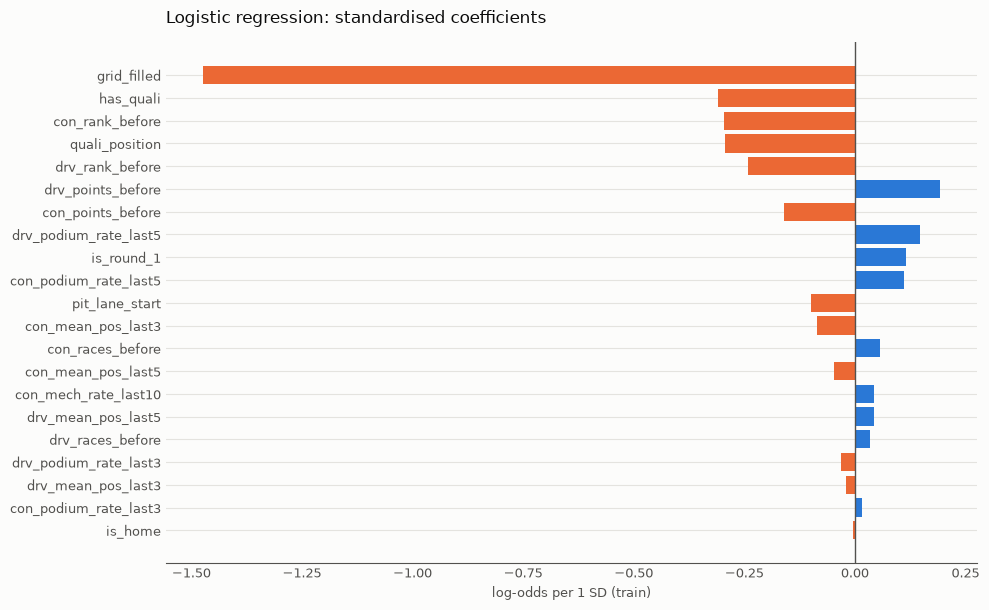

In [65]:
lr = fitted["logistic regression"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out(), name="coef")
coef_table = pd.DataFrame({"coef": coef, "odds ratio per SD": np.exp(coef)}).reindex(
    coef.abs().sort_values(ascending=False).index)
print("intercept:", round(float(lr.named_steps["clf"].intercept_[0]), 3),
      "| iterations:", int(lr.named_steps["clf"].n_iter_[0]))
display(coef_table.round(3))

fig, ax = plots.new_figure(height=6.2)
order = coef_table.index[::-1]
ax.barh(range(len(order)), coef_table.loc[order, "coef"],
        color=[plots.SERIES[0] if v > 0 else plots.SERIES[1] for v in coef_table.loc[order, "coef"]])
ax.axvline(0, color=plots.INK_MUTED, linewidth=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
plots.style_axes(ax, "Logistic regression: standardised coefficients", xlabel="log-odds per 1 SD (train)")
fig.tight_layout()
plt.show()

**What it shows.**
- **Starting position dominates:** `grid_filled` −1.47 (odds × 0.23 per standard deviation, about 7 grid places in
  training), far ahead of everything else. `quali_position` (−0.29) adds a little on top of the grid.
- **Season standing comes next:** constructor rank −0.30 and driver rank −0.24 (a better, i.e. lower, rank goes with
  more podiums). Driver points +0.19 and recent driver form (podium rate over the last 5 starts, +0.15) also count.
- **Some signs look odd, and that is expected with correlated inputs:** `con_points_before` is −0.16 although
  constructor rank already points the other way, and `con_mech_rate_last10` is slightly positive (+0.04).
  `has_quali` (−0.31) and `is_round_1` (+0.12) mostly correct for how missing values were imputed (median quali
  position before 1994; median rank at round 1). They are not effects of their own.
- **`is_home` is about 0 (−0.005)**, in line with Q2.

> **Coefficients are associations, not causes.** They describe how the fitted model weighs each feature given all the
> others. Many features are strongly correlated (grid and qualifying position; points and rank; last-3 and last-5
> form), so they share weight between them. A single coefficient's size or even sign can change when a correlated
> feature is added or removed, and a small coefficient does not mean the feature is unimportant on its own.

## 11. Tree models and model comparison (validation only)

Random forest and histogram gradient boosting, on **the same modeling table, features and split** as the baselines.
**The test split is not used** (`final_test_report` is not called; the grid search reads train and validation rows only).

**Preprocessing:** the same `ColumnTransformer` as logistic regression (median imputation fitted on train rows), with
**no scaler** because trees are insensitive to feature scale. HistGradientBoosting handles NaN natively, so the imputation
is irrelevant to it; it is kept identical so that every model sees exactly the same inputs.

**Hyperparameters are chosen on validation only**, from small stated grids (`config.RF_GRID`, `config.HGB_GRID`), seed 42:
the chosen variant has the highest **validation PR-AUC** (ties: the earlier variant). Each variant also shows its F1 at
its own validation-tuned threshold, and its train PR-AUC and the train − validation gap (an overfitting check).

> **Two cautions.** (1) With 16–18 variants per model, the best validation score is a *maximum* and so slightly
> optimistic; the test split will be the unbiased check, later and once. (2) The train − validation gap is confounded
> with the era: training covers 1950–2019 (smaller fields of different quality, qualifying data missing before 1994),
> validation 2020–2021 only. A negative gap means "validation is easier than train", not "no overfitting"; a large
> positive gap does mean memorisation.

### 11.1 Random forest: grid on validation

Grid: `n_estimators` ∈ {200, 500}, `max_depth` ∈ {6, 12, None}, `min_samples_leaf` ∈ {1, 5, 20} (18 variants),
`class_weight=None` for now; single-threaded so results are bit-identical between runs.

In [66]:
from sklearn.metrics import precision_recall_curve, roc_curve

def grid_view(tab):
    pcols = [c for c in tab.columns if c.startswith("param_")]
    v = tab[pcols + ["val_pr_auc", "val_roc_auc", "val_f1", "val_precision", "val_recall", "threshold",
                     "train_pr_auc", "gap_pr_auc"]].copy()
    for c in pcols:
        v[c] = [("None" if pd.isna(x) else f"{x:g}") for x in v[c]]
    v.insert(0, "chosen", np.where(tab["chosen"], "◄ chosen", ""))
    v.columns = [c.replace("param_", "") for c in v.columns]
    return v

def show_grid(tab):
    v = grid_view(tab)
    fmt = {c: "{:.3f}" for c in ["val_pr_auc", "val_roc_auc", "val_f1", "val_precision", "val_recall", "threshold",
                                 "train_pr_auc", "gap_pr_auc"]}
    display(v.style.format(fmt).apply(lambda r: ["font-weight: bold" if r["chosen"] else "" for _ in r], axis=1))

val_base = float(y.loc[ev.split_rows(meta, "validation")].mean())
rf_table, rf_best = ev.tune_on_validation("random forest", mdl.random_forest, config.RF_GRID, meta, X, y)
print(f"validation base rate (PR-AUC chance level): {val_base:.3f}")
print("chosen:", rf_best)
show_grid(rf_table)

validation base rate (PR-AUC chance level): 0.150
chosen: {'n_estimators': 500, 'max_depth': 12, 'min_samples_leaf': 20}


,chosen,n_estimators,max_depth,min_samples_leaf,val_pr_auc,val_roc_auc,val_f1,val_precision,val_recall,threshold,train_pr_auc,gap_pr_auc
0,,200,6,1,0.697,0.928,0.701,0.650,0.761,0.323,0.620,-0.077
1,,200,6,5,0.705,0.928,0.705,0.677,0.735,0.387,0.617,-0.088
2,,200,6,20,0.709,0.929,0.707,0.667,0.752,0.342,0.608,-0.101
3,,200,12,1,0.668,0.923,0.698,0.598,0.838,0.265,0.923,0.255
4,,200,12,5,0.702,0.932,0.717,0.642,0.812,0.291,0.829,0.127
5,,200,12,20,0.715,0.929,0.708,0.683,0.735,0.374,0.685,-0.030
6,,200,None,1,0.685,0.923,0.702,0.634,0.786,0.325,1.000,0.315
7,,200,None,5,0.696,0.927,0.707,0.637,0.795,0.292,0.903,0.206
8,,200,None,20,0.718,0.930,0.705,0.685,0.726,0.393,0.694,-0.024
9,,500,6,1,0.704,0.928,0.700,0.736,0.667,0.474,0.620,-0.084


**What it shows.**
- **Chosen: 500 trees, `max_depth` 12, `min_samples_leaf` 20.** Validation PR-AUC 0.719 (base rate 0.150), ROC-AUC
  0.930, F1 0.702 at its own threshold of 0.288. Across all 18 variants PR-AUC ranges from 0.668 to 0.719.
- **`min_samples_leaf` matters most.** A leaf of 20 beats a leaf of 1 in all six (trees × depth) pairs, by 0.008 to 0.047
  PR-AUC. Unrestricted trees (leaf 1, depth 12 or None) fit the training rows almost perfectly (train PR-AUC 0.92–1.00,
  gap +0.25 to +0.32) and generalise worse (0.668–0.685). The chosen configuration has a gap of −0.033.
- **200 vs 500 trees changes PR-AUC by at most 0.008**, in either direction, so the forest size is not important here.
- **F1 at each variant's own threshold barely moves** (0.698–0.717). It is a much coarser measure than PR-AUC, which
  is why PR-AUC is the selection criterion.

### 11.2 HistGradientBoosting: grid on validation

Grid: `learning_rate` ∈ {0.03, 0.1}, `max_iter` ∈ {100, 300}, `max_depth` ∈ {3, 6}, `l2_regularization` ∈ {0, 1}
(16 variants), `class_weight=None`, no early stopping (so nothing is split off the training rows).

In [67]:
hgb_table, hgb_best = ev.tune_on_validation("hist gradient boosting", mdl.hist_gradient_boosting,
                                            config.HGB_GRID, meta, X, y)
print(f"validation base rate (PR-AUC chance level): {val_base:.3f}")
print("chosen:", hgb_best)
show_grid(hgb_table)

validation base rate (PR-AUC chance level): 0.150
chosen: {'learning_rate': 0.03, 'max_iter': 300, 'max_depth': 3, 'l2_regularization': 0.0}


,chosen,learning_rate,max_iter,max_depth,l2_regularization,val_pr_auc,val_roc_auc,val_f1,val_precision,val_recall,threshold,train_pr_auc,gap_pr_auc
0,,0.03,100,3,0,0.721,0.928,0.715,0.650,0.795,0.296,0.590,-0.131
1,,0.03,100,3,1,0.718,0.928,0.700,0.643,0.769,0.303,0.590,-0.128
2,,0.03,100,6,0,0.700,0.926,0.704,0.654,0.761,0.314,0.646,-0.054
3,,0.03,100,6,1,0.703,0.927,0.710,0.648,0.786,0.294,0.641,-0.062
4,◄ chosen,0.03,300,3,0,0.727,0.929,0.710,0.648,0.786,0.287,0.615,-0.112
5,,0.03,300,3,1,0.726,0.930,0.713,0.646,0.795,0.271,0.614,-0.112
6,,0.03,300,6,0,0.697,0.924,0.707,0.667,0.752,0.325,0.724,0.026
7,,0.03,300,6,1,0.716,0.926,0.707,0.674,0.744,0.327,0.721,0.005
8,,0.1,100,3,0,0.723,0.929,0.711,0.655,0.778,0.269,0.614,-0.110
9,,0.1,100,3,1,0.724,0.928,0.717,0.708,0.726,0.378,0.618,-0.105


**What it shows.**
- **Chosen: learning rate 0.03, 300 iterations, `max_depth` 3, L2 = 0.** Validation PR-AUC 0.727, ROC-AUC 0.929, F1
  0.710 at a threshold of 0.287. The 16 variants range from 0.641 to 0.727.
- **Shallow trees win:** depth 3 beats depth 6 in all eight (learning rate × iterations × L2) pairs, by 0.010 to 0.065.
- **Fast, deep and long overfits:** learning rate 0.1 with 300 iterations and depth 6 reaches train PR-AUC 0.90–0.92
  (gap +0.26 to +0.27) and the worst validation PR-AUC (0.641–0.644).
- **L2 = 1 helps the deeper models** (0.697 → 0.716, 0.678 → 0.694) **but makes no real difference at depth 3** (within
  0.003). The six best variants all have depth 3 and lie within 0.718–0.727, a spread the validation set cannot
  resolve.

### 11.3 `class_weight`: balanced vs None

One comparison per model, at its chosen configuration. `balanced` re-weights the classes by inverse frequency, which
changes the probabilities (so the F1 threshold is re-tuned on validation for each variant). The class weight is chosen
by validation PR-AUC for the tree models. Logistic regression stays at `class_weight=None` as specified earlier; its
`balanced` row is shown for comparison only.

In [68]:
cw_specs = {
    "logistic regression": (mdl.logistic_baseline, {}),
    "random forest": (mdl.random_forest, rf_best),
    "hist gradient boosting": (mdl.hist_gradient_boosting, hgb_best),
}
cw_rows, final_params = [], {}
for model_name, (make, params) in cw_specs.items():
    best = None
    for cw in config.CLASS_WEIGHTS:
        row, _, _ = ev.evaluate_train_val(model_name, make(**params, class_weight=cw), meta, X, y)
        cw_rows.append({"model": model_name, "class_weight": str(cw), **{k: row[k] for k in (
            "val_pr_auc", "val_roc_auc", "val_f1", "val_precision", "val_recall", "threshold", "train_pr_auc",
            "gap_pr_auc")}})
        if best is None or row["val_pr_auc"] > best[0]:
            best = (row["val_pr_auc"], cw)
    chosen_cw = None if model_name == "logistic regression" else best[1]
    final_params[model_name] = {**params, "class_weight": chosen_cw}
cw_table = pd.DataFrame(cw_rows).set_index(["model", "class_weight"])
display(cw_table.style.format("{:.3f}"))
print("final configurations:")
for k, v in final_params.items():
    print(f"  {k}: {v}")

final configurations:
  logistic regression: {'class_weight': None}
  random forest: {'n_estimators': 500, 'max_depth': 12, 'min_samples_leaf': 20, 'class_weight': None}
  hist gradient boosting: {'learning_rate': 0.03, 'max_iter': 300, 'max_depth': 3, 'l2_regularization': 0.0, 'class_weight': None}


**What it shows.**
- **`balanced` lowers validation PR-AUC for all three models:** logistic regression 0.726 → 0.722, random forest
  0.719 → 0.703, gradient boosting 0.727 → 0.706. ROC-AUC moves by at most 0.005 and F1 by at most 0.003.
- **What it does change is the probability scale:** the F1-optimal threshold jumps from about 0.28 to 0.66–0.81, because
  re-weighting inflates the predicted probabilities. It does not improve the ranking.
- **Chosen: `class_weight=None` for all three.** The comparison is one more selection step on the validation set, so it
  adds slightly to the optimism noted above.

### 11.4 All models: train and validation at the frozen validation threshold

Every model is fitted on train rows only. The threshold is the F1-optimal one on **validation**, frozen, then applied
to both train and validation. The base rate is shown beside every PR-AUC (it differs between train and validation, so
compare PR-AUC ÷ base rate as well). The last block is the overfitting check, train minus validation.

In [69]:
final_models = {
    "naive: -grid": mdl.GridBaseline(),
    "naive: -quali (fallback -grid)": mdl.QualiBaseline(),
    "logistic regression": mdl.logistic_baseline(**final_params["logistic regression"]),
    "random forest": mdl.random_forest(**final_params["random forest"]),
    "hist gradient boosting": mdl.hist_gradient_boosting(**final_params["hist gradient boosting"]),
}
cmp_rows, val_scores = [], {}
for model_name, model in final_models.items():
    row, _, sv = ev.evaluate_train_val(model_name, model, meta, X, y)
    cmp_rows.append(row)
    val_scores[model_name] = sv
cmp = pd.DataFrame(cmp_rows).set_index("model")
metric_cols = ["base_rate", "pr_auc", "pr_auc_over_base_rate", "roc_auc", "precision", "recall", "f1"]
train_val = pd.concat({
    "train": cmp[[f"train_{c}" for c in metric_cols]].rename(columns=lambda c: c[len("train_"):]),
    "validation": cmp[[f"val_{c}" for c in metric_cols]].rename(columns=lambda c: c[len("val_"):]),
    "gap (train − validation)": cmp[["gap_pr_auc", "gap_roc_auc", "gap_f1"]].rename(columns=lambda c: c[len("gap_"):]),
}, axis=1)
display(pd.DataFrame({"frozen validation threshold": cmp["threshold"]}).T.round(3))
fmt = {c: "{:.3f}" for c in train_val.columns}
for split in ("train", "validation"):
    fmt[(split, "base_rate")] = "{:.1%}"
    fmt[(split, "pr_auc_over_base_rate")] = "{:.2f}x"
display(train_val.style.format(fmt))
# the validation numbers must agree with the section-10 baselines (same data, same code path)
assert abs(cmp.loc["logistic regression", "val_pr_auc"] - val_table.loc["logistic regression", "pr_auc"]) < 1e-9

model,naive: -grid,naive: -quali (fallback -grid),logistic regression,random forest,hist gradient boosting
frozen validation threshold,-3.0,-3.0,0.276,0.288,0.287


**What it shows.**
- **Validation PR-AUC** (base rate 15.0%): −grid 0.639 (4.3×), −quali 0.654 (4.4×), logistic regression 0.726 (4.8×),
  random forest 0.719 (4.8×), gradient boosting 0.727 (4.8×). ROC-AUC spans only 0.909–0.930.
- **The three learned models are close to each other** (0.719–0.727) and 0.08–0.09 above the grid rule.
- **Every model scores lower on train than on validation**, including the two rules that learn nothing (−grid 0.495 vs
  0.639). So the negative gaps are mostly the era effect (train spans 1950–2019, with a 13.4% base rate and weaker
  qualifying data), not evidence of absence of overfitting.
- **Read the gap between models, not the sign:** the gap is smallest for random forest (−0.033), against −0.11 to −0.16
  for the other four; random forest also has the best train PR-AUC (0.686). The chosen tree configurations are
  regularised (min leaf 20, depth 12; depth 3), and the unregularised variants in 11.1–11.2 are the ones that overfit.
- **F1 at the frozen threshold** is 0.692, 0.692, 0.702, 0.702 and 0.710 on validation. Precision and recall are
  both 0.692 for the two rules (the threshold is "top 3 on the grid").
- **Caution:** the hyperparameters and thresholds were picked on these validation rows, so the validation columns are
  mildly optimistic. The differences between the three learned models are not meaningful at this size (11.5).

### 11.5 Paired race-level bootstrap on validation

**Question:** are the PR-AUC differences between models larger than the noise? Whole races are resampled with
replacement (B = 1000, seed 42), and **the same resampled races are used for both models** in each resample, so the
interval is for the *difference*. It covers only the 39 validation races, so it is wide; it does not include
the uncertainty from choosing hyperparameters on the same races.

In [70]:
ref_grid, ref_lr = "naive: -grid", "logistic regression"
val_idx = ev.split_rows(meta, "validation")
pairs = [(m, ref_grid) for m in final_models if m != ref_grid] +         [(m, ref_lr) for m in final_models if m not in (ref_grid, ref_lr)]
boot = ev.paired_race_bootstrap(y.loc[val_idx].to_numpy(), val_scores, meta.loc[val_idx, "raceId"].to_numpy(), pairs,
                                B=config.BOOTSTRAP_B, seed=config.RANDOM_SEED)
boot["interval excludes 0"] = (boot["ci_low"] > 0) | (boot["ci_high"] < 0)
display(boot.set_index(["versus", "model"])[["pr_auc_diff", "ci_low", "ci_high", "share_a_better",
                                              "interval excludes 0"]]
        .style.format({"pr_auc_diff": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}",
                       "share_a_better": "{:.1%}"}))
print("resamples:", int(boot["B"].iloc[0]), "| skipped (single class):", int(boot["skipped"].iloc[0]))

resamples: 1000 | skipped (single class): 0


**What it shows.**
- **Versus −grid, all three learned models are clearly better:** logistic regression +0.087 (95% interval +0.033 to
  +0.141), random forest +0.080 (+0.027 to +0.131), gradient boosting +0.088 (+0.045 to +0.129). In at least 99.9% of
  resamples each beats the grid rule.
- **The qualifying rule is not distinguishable from the grid rule:** +0.016 (−0.018 to +0.051).
- **Versus logistic regression, the tree models are not distinguishable:** random forest −0.007 (−0.041 to +0.027),
  gradient boosting +0.001 (−0.039 to +0.035). Intervals of about ±0.035 mean the validation set can only detect
  differences of a few hundredths; that is not the same as "no difference".
- **The qualifying rule is below logistic regression:** −0.072 (−0.135 to −0.006), with the upper end close to 0.
- **Limits:** 39 races only, and the intervals do not include the uncertainty from choosing hyperparameters on the same
  races (the winner of 16–18 variants is optimistic).

### 11.6 Precision-recall and ROC curves (validation)

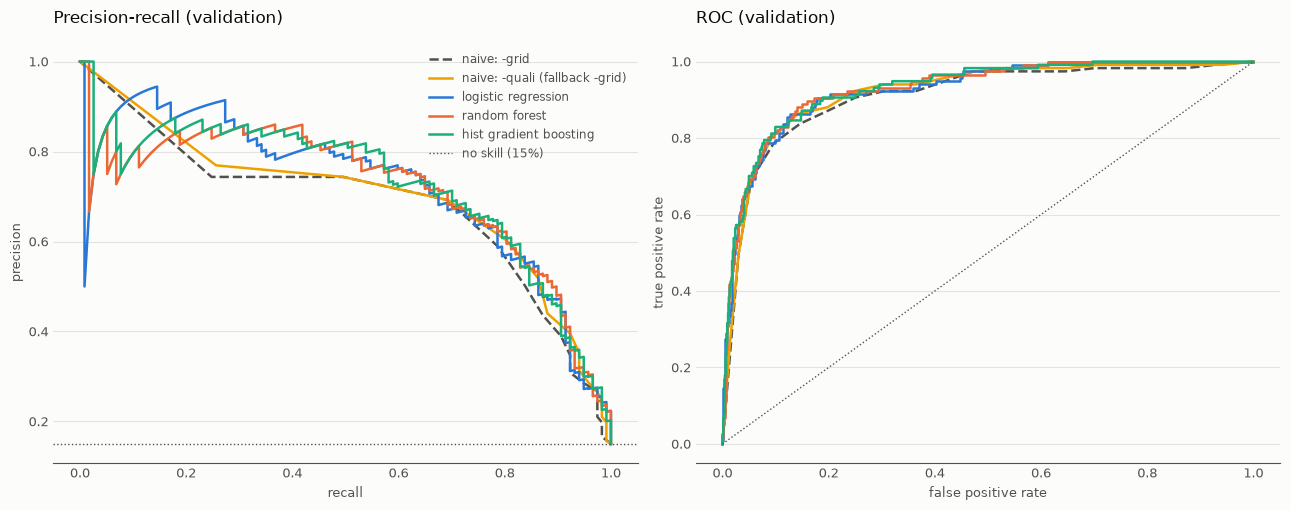

In [71]:
colors = {"naive: -grid": plots.INK_MUTED, "naive: -quali (fallback -grid)": plots.SERIES[3],
          "logistic regression": plots.SERIES[0], "random forest": plots.SERIES[1],
          "hist gradient boosting": plots.SERIES[2]}
yv = y.loc[val_idx].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), facecolor=plots.SURFACE)
for ax in axes:
    ax.set_facecolor(plots.SURFACE)
for model_name, s in val_scores.items():
    p_, r_, _ = precision_recall_curve(yv, s)
    f_, t_, _ = roc_curve(yv, s)
    style = "--" if model_name == "naive: -grid" else "-"
    axes[0].plot(r_, p_, style, color=colors[model_name], linewidth=1.8, label=model_name)
    axes[1].plot(f_, t_, style, color=colors[model_name], linewidth=1.8, label=model_name)
axes[0].axhline(val_base, color=plots.INK_MUTED, linewidth=1, linestyle=":", label=f"no skill ({val_base:.0%})")
axes[1].plot([0, 1], [0, 1], color=plots.INK_MUTED, linewidth=1, linestyle=":")
plots.style_axes(axes[0], "Precision-recall (validation)", xlabel="recall", ylabel="precision")
plots.style_axes(axes[1], "ROC (validation)", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=plots.INK_MUTED, loc="upper right")
fig.tight_layout()
plt.show()

**What it shows.**
- **The ROC curves are nearly on top of each other.** The three learned models and the qualifying rule are
  indistinguishable by eye; the grid rule sits slightly lower at false-positive rates of 0.1–0.3.
- **The precision-recall curves differ mostly at low recall (below about 0.3),** where only the few top-ranked drivers
  count and the learned models' curves are spiky. They overlap from recall about 0.5 to 0.7.
- **At high recall (0.75–0.95) the learned models keep somewhat more precision** than the grid rule, which is where
  their PR-AUC advantage comes from.
- **The two rules draw flat steps** because their scores are whole grid positions with many ties.

> **Test stays locked.** `final_test_report` has not been called, and `results/final_test.csv` does not exist. The
> choices above (model families, hyperparameters, class weights, thresholds) are all frozen from validation, so a later
> one-off test evaluation is an honest estimate.